In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("All imports successful")

All imports successful


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

# Load raw dataset
RAW_DATA_PATH = Path("../data/raw/Data (4).csv")

df = pd.read_csv(RAW_DATA_PATH)

print("Shape:", df.shape)
df.head()

Shape: (377719, 7)


,time,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
0,01-01-2017 00:00,867.63,910.42,-189.54,-186.04,852.13,-145.9
1,01-01-2017 00:05,879.23,918.14,-184.33,-182.1,862.53,-149.76
2,01-01-2017 00:10,875.67,924.18,-181.26,-166.47,866.06,-145.01
3,01-01-2017 00:15,875.28,923.15,-179.15,-174.83,865.85,-142.82
4,01-01-2017 00:20,891.66,934.26,-178.32,-173.72,876.06,-143.39


In [3]:
# Create analysis copy
df_eda = df.copy()

SENSOR_COLS = [
    "Cyclone_Inlet_Gas_Temp",
    "Cyclone_Material_Temp",
    "Cyclone_Outlet_Gas_draft",
    "Cyclone_cone_draft",
    "Cyclone_Gas_Outlet_Temp",
    "Cyclone_Inlet_Draft"
]

# Convert timestamp
df_eda["timestamp"] = pd.to_datetime(
    df_eda["time"],
    format="mixed",
    errors="coerce"
)

# Convert sensor columns to numeric
df_eda[SENSOR_COLS] = df_eda[SENSOR_COLS].apply(
    pd.to_numeric,
    errors="coerce"
)

# Sort chronologically
df_eda = df_eda.sort_values("timestamp").reset_index(drop=True)

print("Shape:", df_eda.shape)
print("Time range:")
print(df_eda["timestamp"].min())
print("to")
print(df_eda["timestamp"].max())

Shape: (377719, 8)
Time range:
2017-01-01 00:00:00
to
2020-08-07 12:15:00


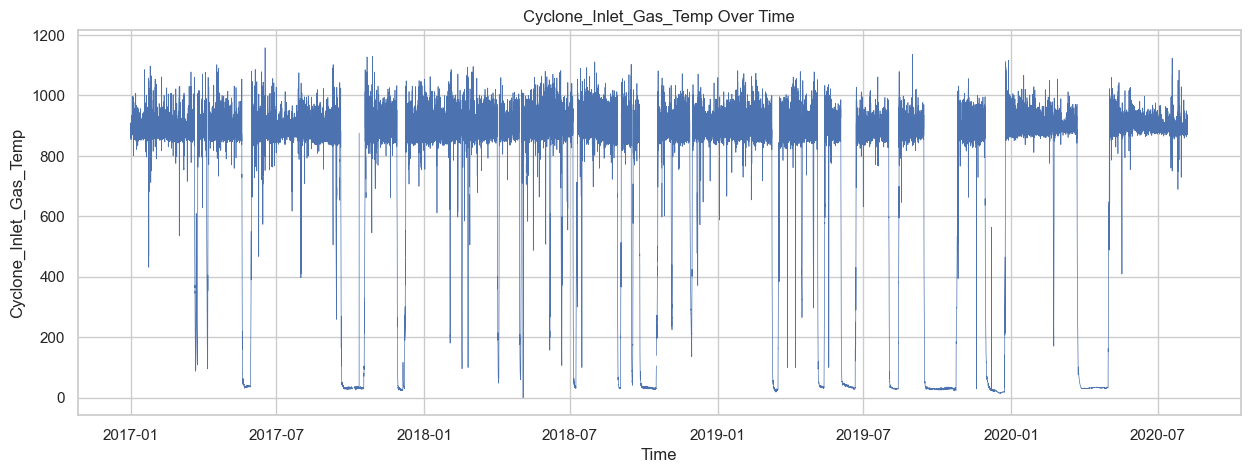

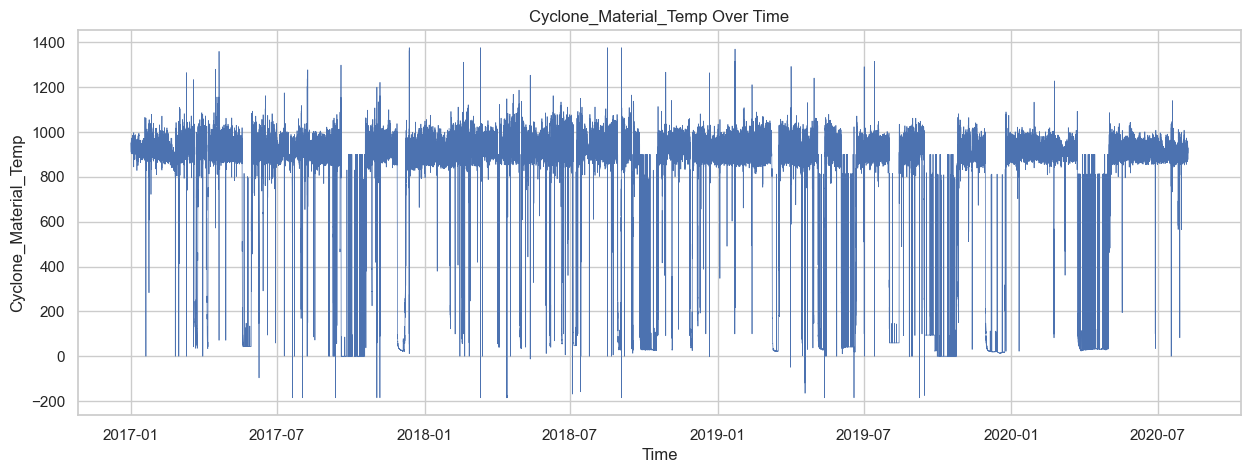

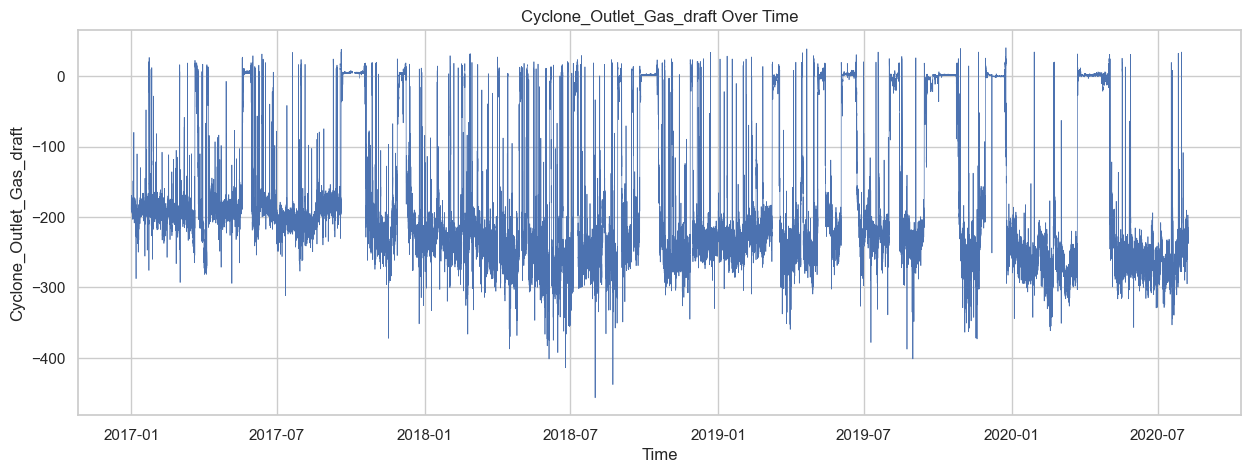

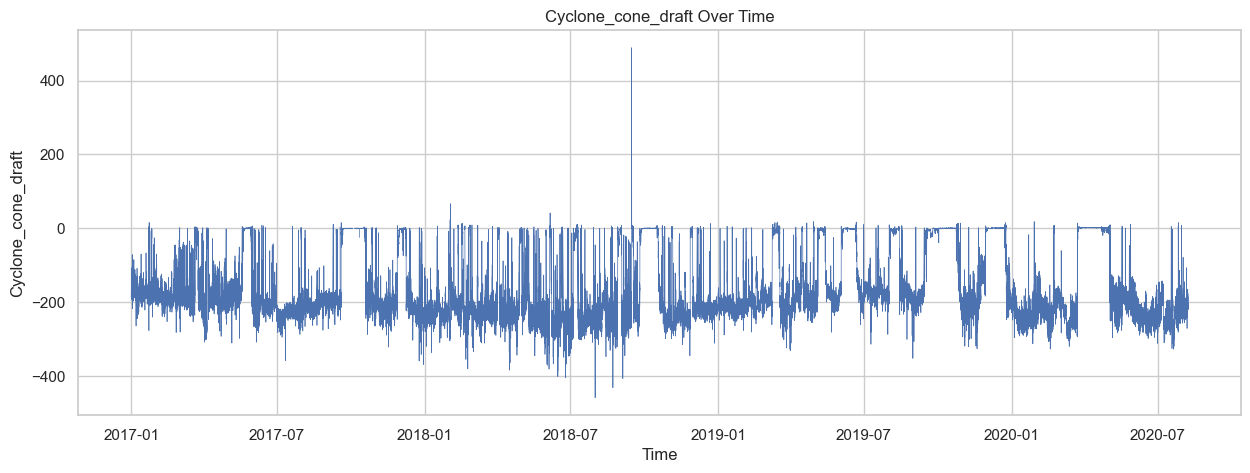

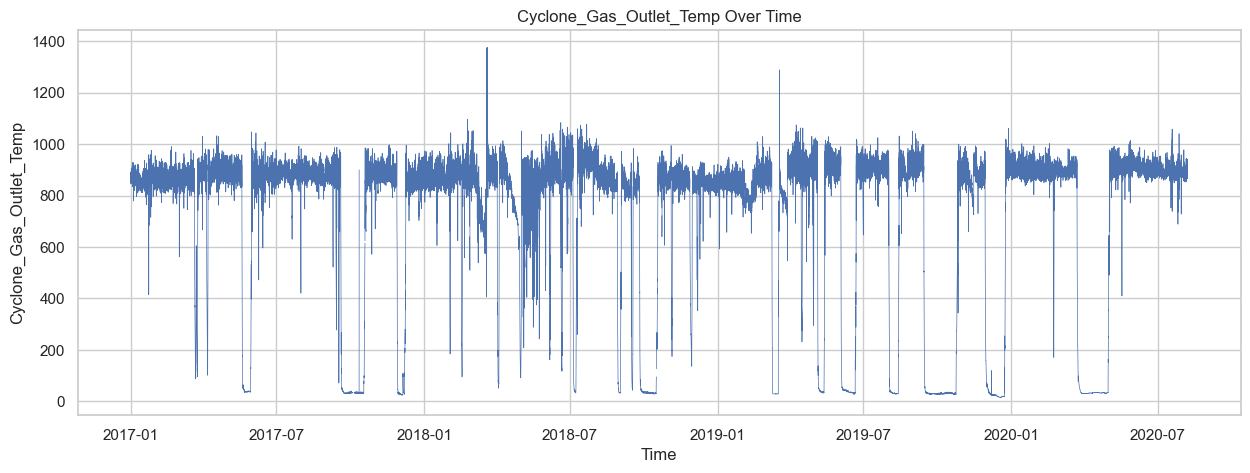

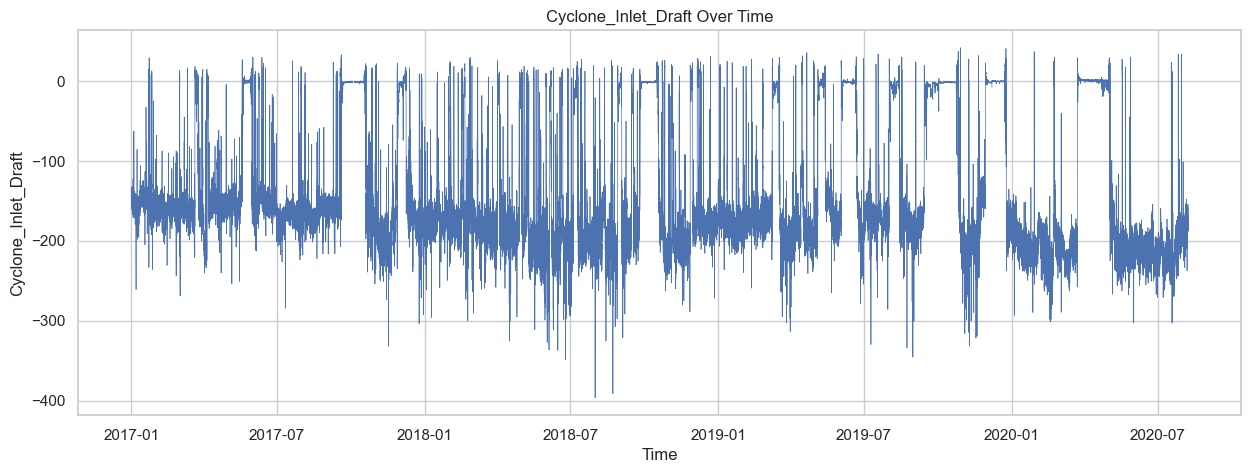

In [4]:
#Sensors over time:
for col in SENSOR_COLS:

    plt.figure(figsize=(15, 5))

    plt.plot(
        df_eda["timestamp"],
        df_eda[col],
        linewidth=0.5
    )

    plt.xlabel("Time")
    plt.ylabel(col)
    plt.title(f"{col} Over Time")

    plt.show()

In [5]:
start_date = "2017-01-01"
end_date = "2017-02-01"

df_zoom = df_eda[
    (df_eda["timestamp"] >= start_date) &
    (df_eda["timestamp"] < end_date)
]

print("Rows:", len(df_zoom))
print("Time range:")
print(df_zoom["timestamp"].min())
print("to")
print(df_zoom["timestamp"].max())

Rows: 8928
Time range:
2017-01-01 00:00:00
to
2017-01-31 23:55:00


#### ## Graphs for Jan 2017

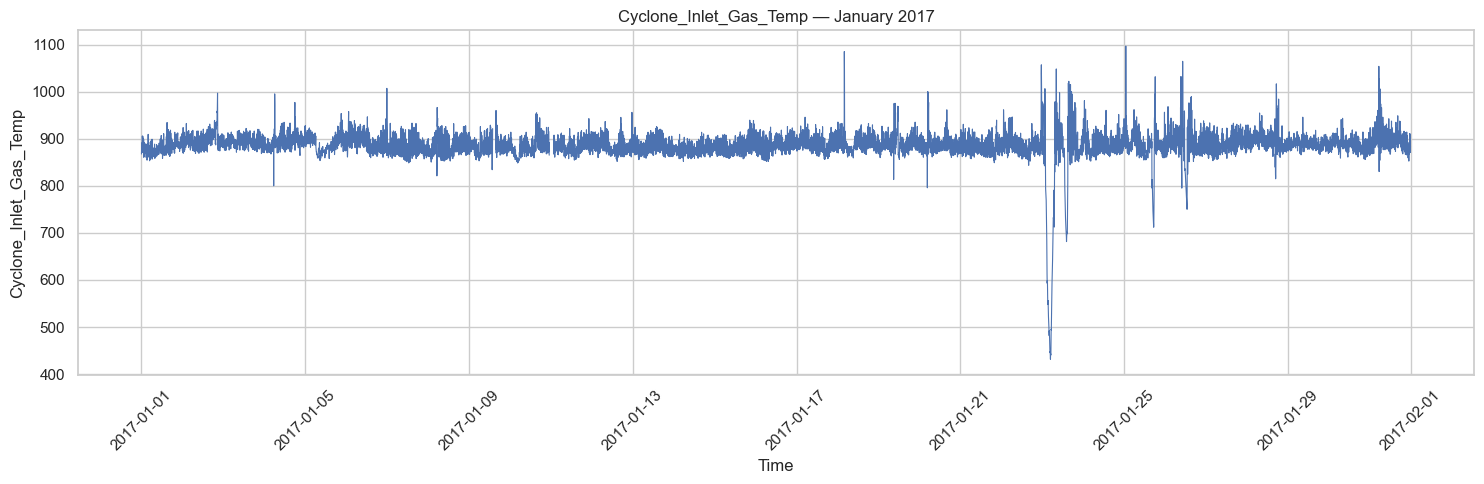

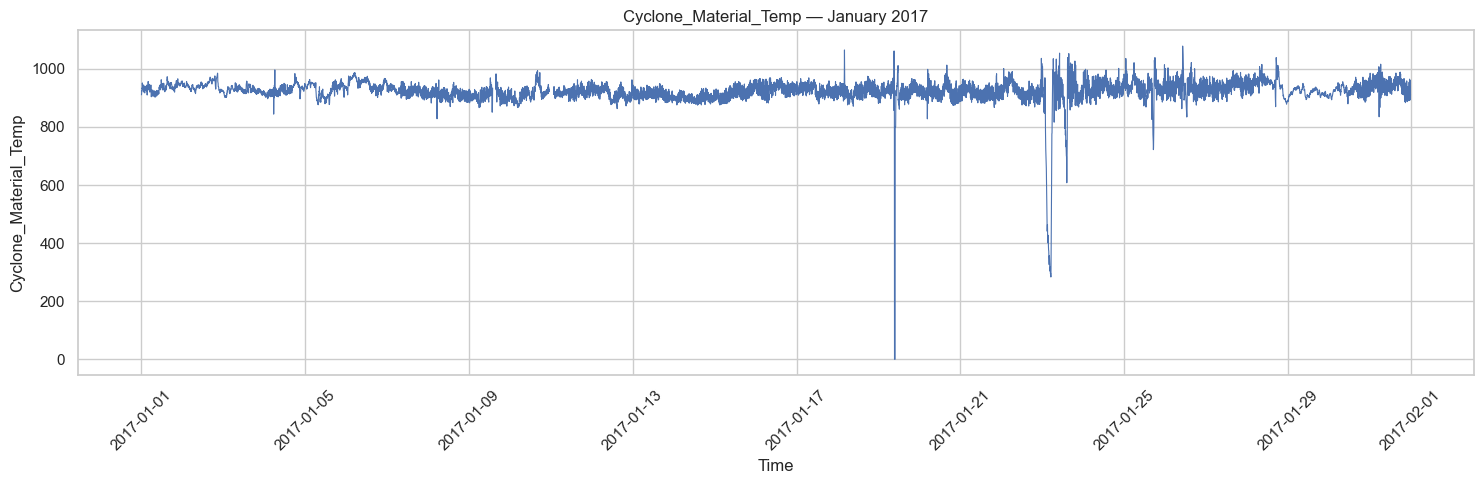

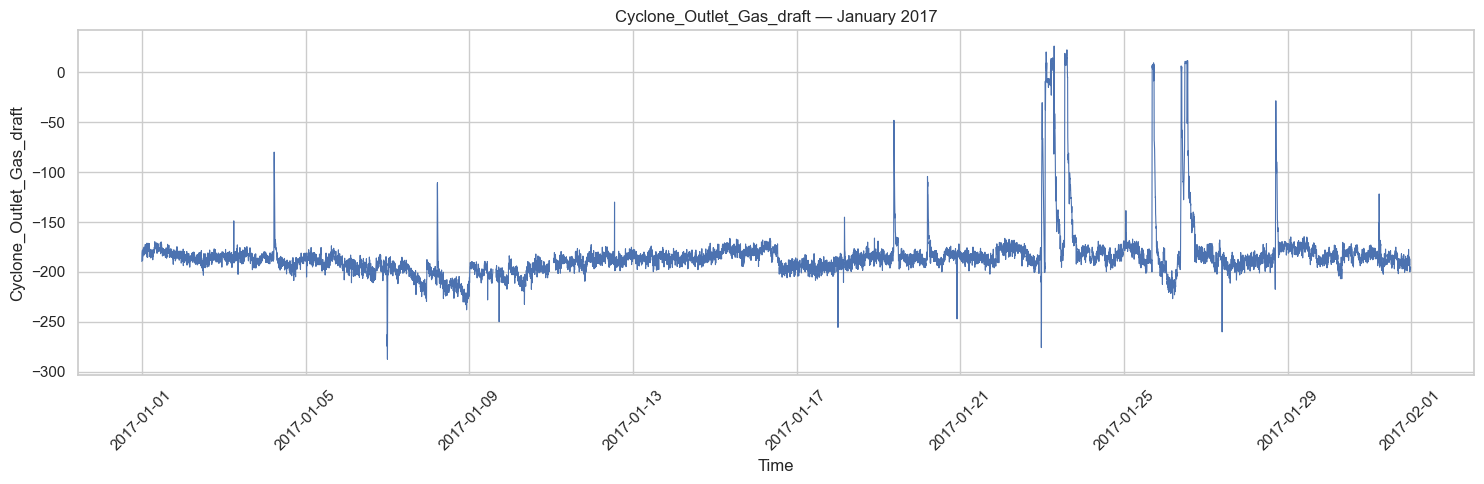

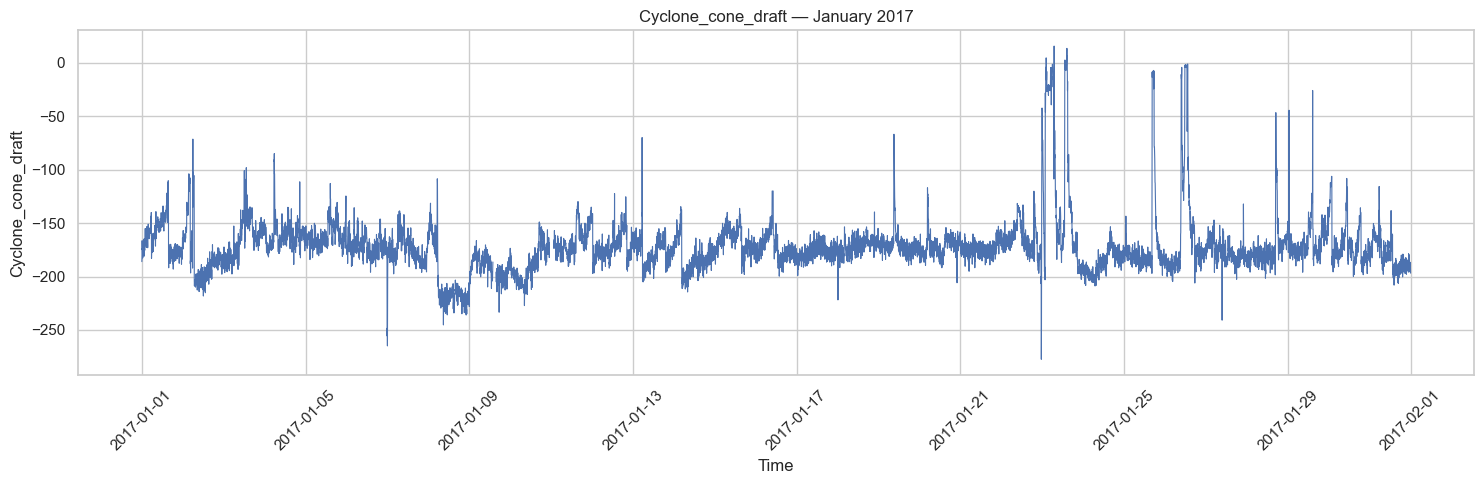

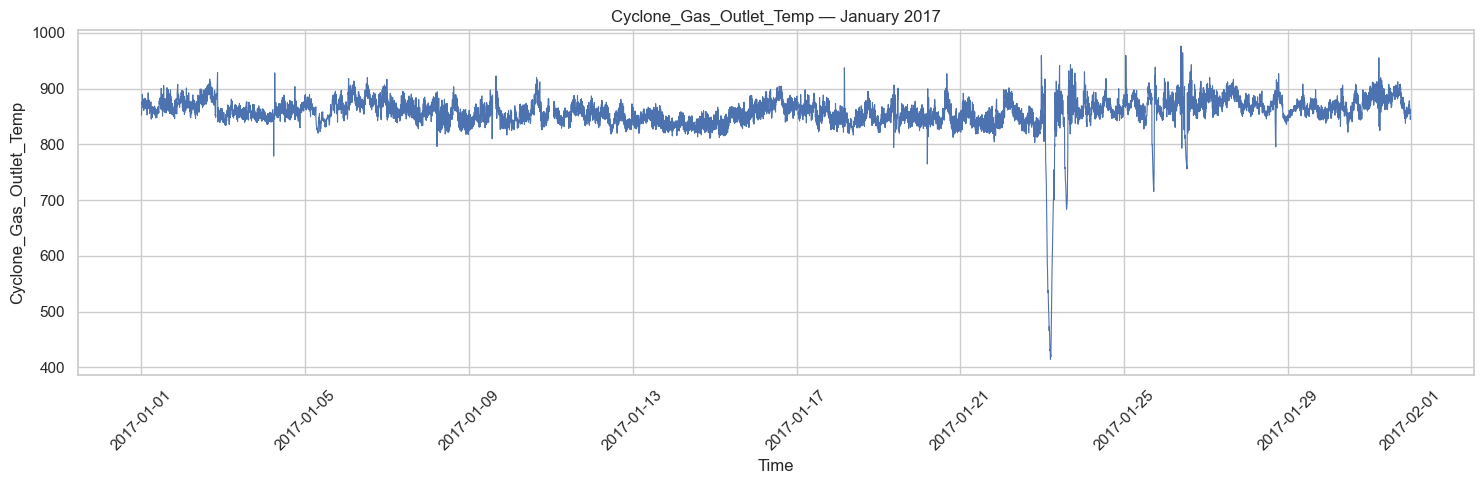

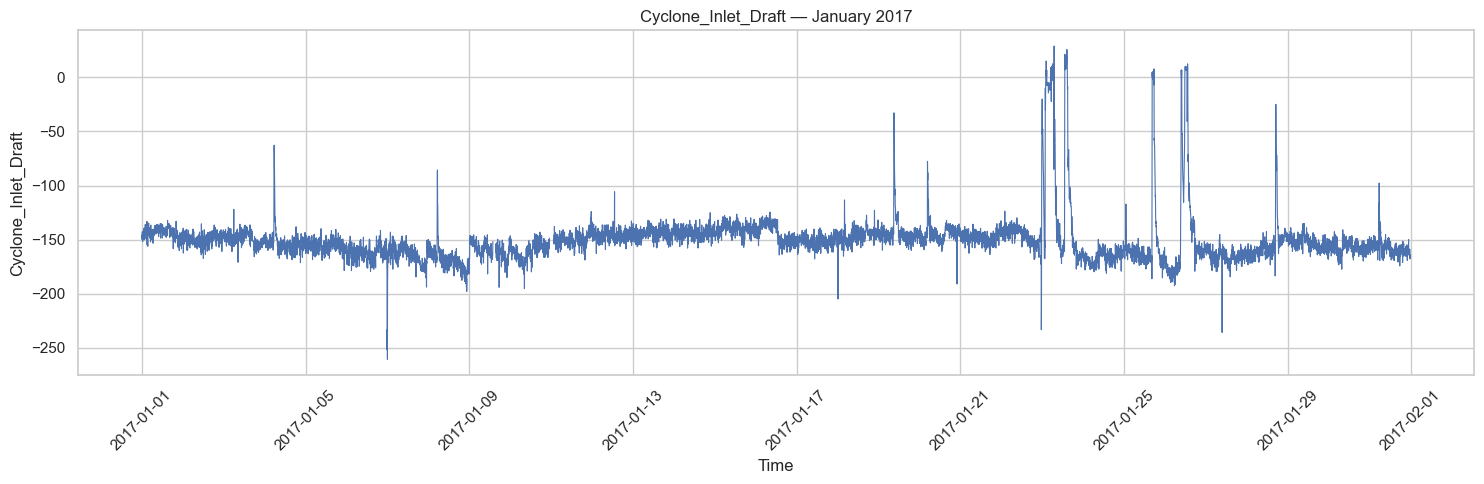

In [ ]:

for col in SENSOR_COLS:

    plt.figure(figsize=(15, 5))

    plt.plot(
        df_zoom["timestamp"],
        df_zoom[col],
        linewidth=0.8
    )

    plt.xlabel("Time")
    plt.ylabel(col)
    plt.title(f"{col} — January 2017")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

#### ##Does this cyclone operate in different normal states?

In [7]:
# Check monthly process behavior

monthly_stats = (
    df_eda
    .set_index("timestamp")[SENSOR_COLS]
    .resample("ME")
    .agg(["mean", "median", "std"])
)

monthly_stats.head()

Cyclone_Inlet_Gas_Temp                      Cyclone_Material_Temp  \
                             mean   median         std                  mean   
timestamp                                                                      
2017-01-31             886.123138  885.735   35.060640            922.478524   
2017-02-28             885.753389  883.475   19.448865            911.746837   
2017-03-31             806.085026  879.370  210.053155            843.906695   
2017-04-30             852.423455  882.320  145.426777            889.265464   
2017-05-31             582.283056  869.620  396.495969            604.733934   

                                Cyclone_Outlet_Gas_draft                      \
             median         std                     mean   median        std   
timestamp                                                                      
2017-01-31  924.935   49.797218              -183.740733 -186.790  27.520444   
2017-02-28  910.500   36.943279              -193.657451 -193.765  11.545836   
2017-03-31  930.100  257.846447              -164.045861 -189.205  70.825101   
2017-04-30  930.380  187.765546              -181.644933 -187.650  56.126963   
2017-05-31  895.030  415.698462              -111.212896 -171.870  91.100083   

           Cyclone_cone_draft                     Cyclone_Gas_Outlet_Temp  \
                         mean   median        std                    mean   
timestamp                                                                   
2017-01-31        -171.435080 -174.310  26.941718              856.973324   
2017-02-28        -184.057935 -187.175  21.789509              862.251909   
2017-03-31        -157.560870 -182.390  64.729353              791.777466   
2017-04-30        -185.134719 -195.360  57.597012              856.931077   
2017-05-31        -110.467354 -154.120  85.888954              583.418422   

                                Cyclone_Inlet_Draft                     
             median         std                mean  median        std  
timestamp                                                               
2017-01-31  858.335   33.475434         -150.080991 -151.93  23.129561  
2017-02-28  861.075   21.491179         -161.048451 -161.24  10.239905  
2017-03-31  863.745  206.747665         -135.004269 -155.27  56.464947  
2017-04-30  891.030  145.076026         -148.333624 -153.33  44.736944  
2017-05-31  871.570  396.837804          -90.822256 -134.63  71.052767

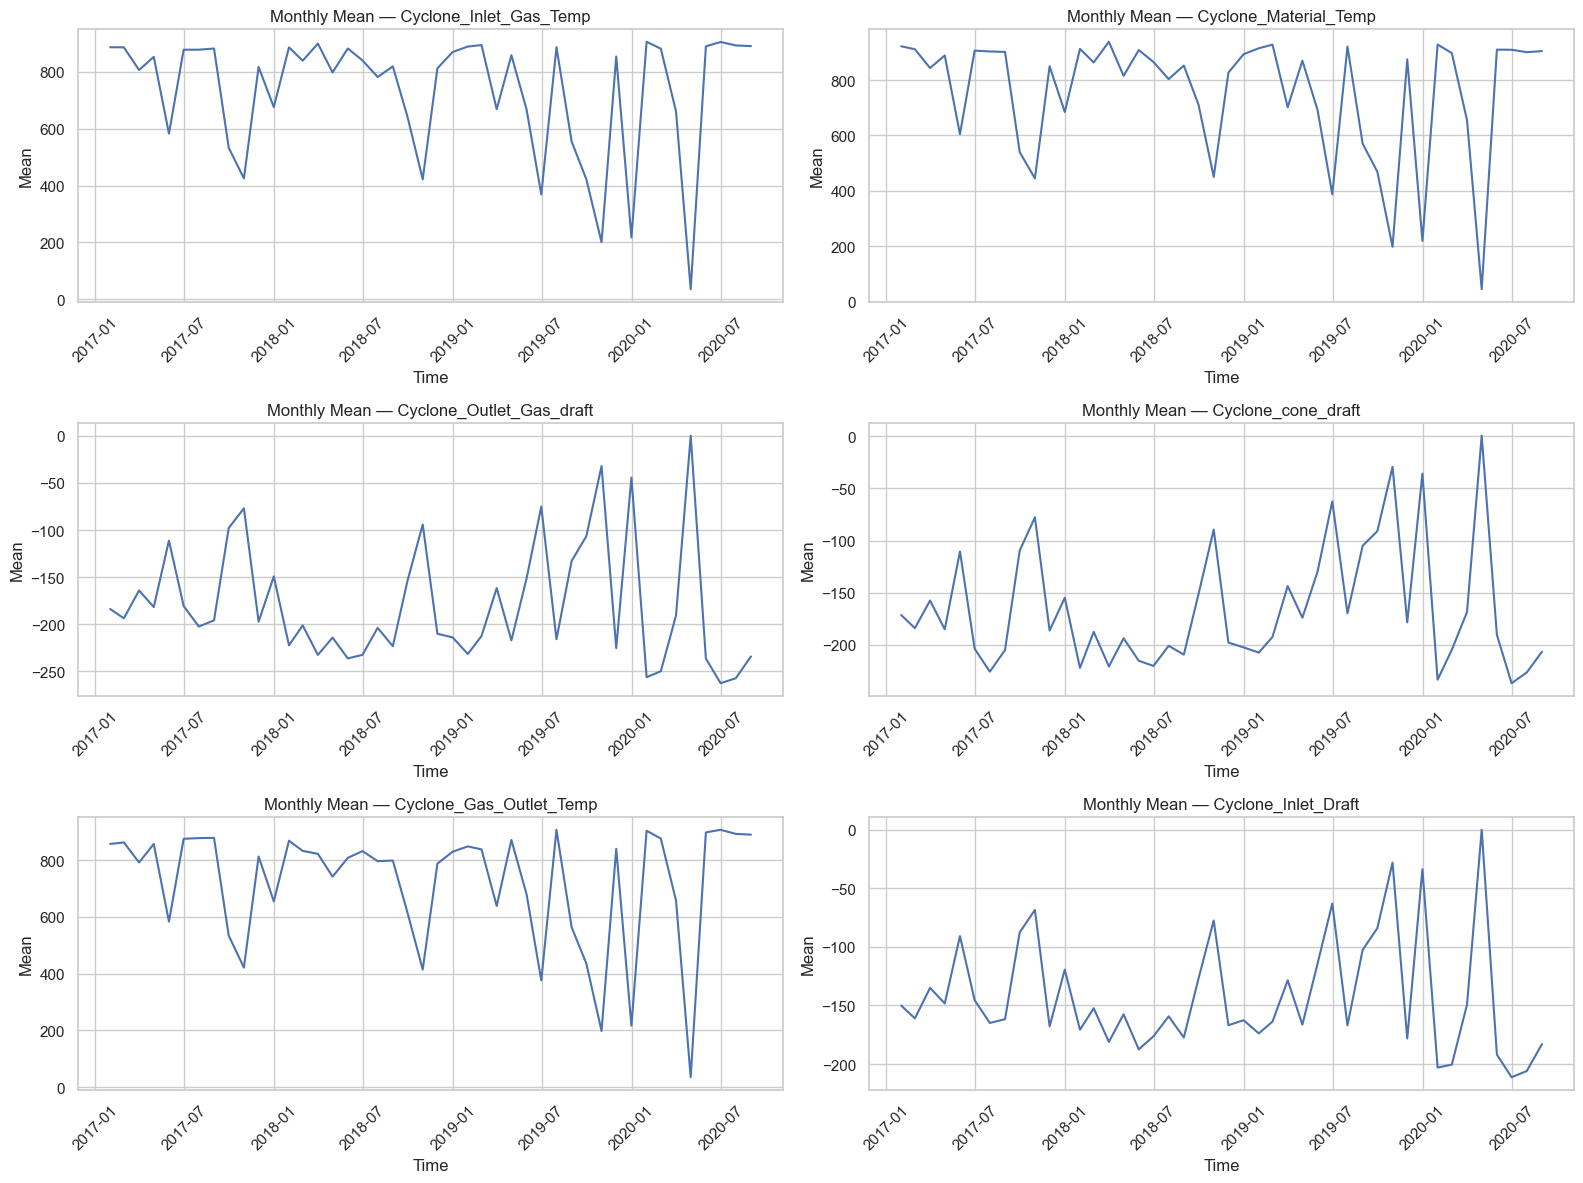

In [12]:
# Monthly mean for all six sensors

monthly_mean = (
    df_eda
    .set_index("timestamp")[SENSOR_COLS]
    .resample("ME")
    .mean()
)

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

for ax, col in zip(axes.flatten(), SENSOR_COLS):
    ax.plot(monthly_mean.index, monthly_mean[col])
    ax.set_title(f"Monthly Mean — {col}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Mean")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)

plt.tight_layout()
plt.show()

In [115]:
# Monthly mean and standard deviation for all sensors

monthly_stats = (
    df_eda
    .set_index("timestamp")[SENSOR_COLS]
    .resample("ME")
    .agg(["mean", "std"])
)

monthly_stats

Cyclone_Inlet_Gas_Temp             Cyclone_Material_Temp  \
                             mean         std                  mean   
timestamp                                                             
2017-01-31             886.123138   35.060640            922.478524   
2017-02-28             885.753389   19.448865            911.746837   
2017-03-31             806.085026  210.053155            843.906695   
2017-04-30             852.423455  145.426777            889.265464   
2017-05-31             582.283056  396.495969            604.733934   
2017-06-30             877.402312   44.856137            906.920923   
2017-07-31             877.574540   47.902730            903.547914   
2017-08-31             881.630335   22.271217            902.115635   
2017-09-30             533.052377  399.074579            539.681386   
2017-10-31             424.823582  416.922900            444.954574   
2017-11-30             817.097856  240.706582            850.062496   
2017-12-31             675.451559  357.033185            684.947804   
2018-01-31             885.747397   30.809800            913.111016   
2018-02-28             838.897282  162.668803            864.053414   
2018-03-31             898.865691   27.587984            938.687018   
2018-04-30             797.442910  250.794838            815.527991   
2018-05-31             881.739731   92.090399            908.718128   
2018-06-30             840.033219  188.927904            865.782094   
2018-07-31             781.563918  289.887773            803.862908   
2018-08-31             818.945095  232.976009            852.803819   
2018-09-30             641.210595  363.709586            711.166195   
2018-10-31             421.755610  414.548477            450.397114   
2018-11-30             812.158770  195.059677            827.289845   
2018-12-31             869.284622   81.406495            893.827049   
2019-01-31             888.583247   30.117923            915.226618   
2019-02-28             893.871506   33.054077            928.291570   
2019-03-31             668.179875  364.065774            702.165700   
2019-04-30             858.152357  132.496243            870.377135   
2019-05-31             666.837246  375.367692            691.671814   
2019-06-30             368.494175  403.508445            387.534217   
2019-07-31             886.153292   25.575049            921.508501   
2019-08-31             554.465114  406.499617            570.517750   
2019-09-30             421.916277  424.507910            468.957605   
2019-10-31             201.027013  323.227854            197.812520   
2019-11-30             853.616960  136.786882            875.115082   
2019-12-31             217.482221  354.648420            218.954845   
2020-01-31             905.343535   20.206746            928.742034   
2020-02-29             881.121920  102.656883            897.845411   
2020-03-31             660.767640  378.787792            655.877460   
2020-04-30              35.534472   23.482481             44.457223   
2020-05-31             889.257560   81.122265            910.214825   
2020-06-30             904.589568   13.482513            909.893942   
2020-07-31             892.572208   22.334676            901.088188   
2020-08-31             890.104067   12.537550            904.959375   

                       Cyclone_Outlet_Gas_draft              \
                   std                     mean         std   
timestamp                                                     
2017-01-31   49.797218              -183.740733   27.520444   
2017-02-28   36.943279              -193.657451   11.545836   
2017-03-31  257.846447              -164.045861   70.825101   
2017-04-30  187.765546              -181.644933   56.126963   
2017-05-31  415.698462              -111.212896   91.100083   
2017-06-30   99.357113              -180.565667   35.215771   
2017-07-31  104.023045              -202.322410   33.456487   
2017-08-31   94.065193              -195.78

#### ##Are these changes legitimate operating regimes or abnormal process behavior?

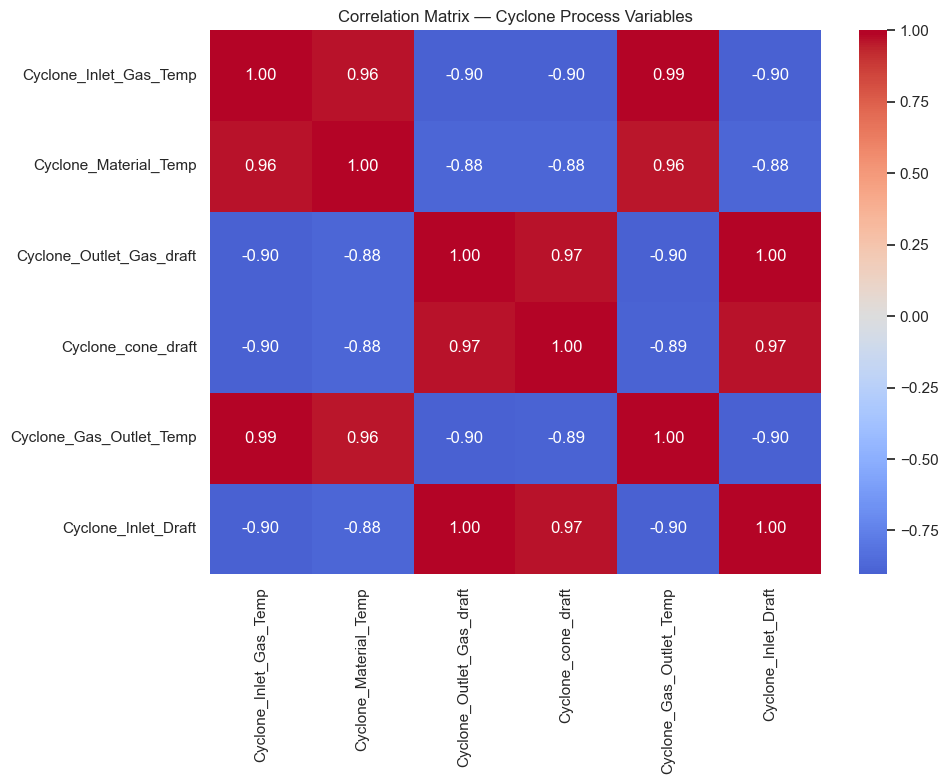

In [13]:
# Correlation between all six process variables

correlation_matrix = df_eda[SENSOR_COLS].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix — Cyclone Process Variables")
plt.tight_layout()
plt.show()

#### ## Does the relationship between temperature and draft remain stable over time?

The overall correlation showed a strong relationship between the temperature variables and draft variables.

However, a single correlation value summarizes the entire 3.5-year dataset.

To detect changes in process behavior, we will calculate **rolling correlation** and examine whether the relationship between the variables remains stable over time.

In [14]:
# Rolling correlation between inlet gas temperature and outlet gas draft

rolling_corr = (
    df_eda[
        ["timestamp",
         "Cyclone_Inlet_Gas_Temp",
         "Cyclone_Outlet_Gas_draft"]
    ]
    .set_index("timestamp")
    .rolling("7D")
    .corr()
)

rolling_corr

Cyclone_Inlet_Gas_Temp  \
timestamp                                                              
2017-01-01 00:00:00 Cyclone_Inlet_Gas_Temp                       NaN   
                    Cyclone_Outlet_Gas_draft                     NaN   
2017-01-01 00:05:00 Cyclone_Inlet_Gas_Temp                  1.000000   
                    Cyclone_Outlet_Gas_draft                1.000000   
2017-01-01 00:10:00 Cyclone_Inlet_Gas_Temp                  1.000000   
...                                                              ...   
2020-08-07 12:05:00 Cyclone_Outlet_Gas_draft                0.061139   
2020-08-07 12:10:00 Cyclone_Inlet_Gas_Temp                  1.000000   
                    Cyclone_Outlet_Gas_draft                0.061156   
2020-08-07 12:15:00 Cyclone_Inlet_Gas_Temp                  1.000000   
                    Cyclone_Outlet_Gas_draft                0.061342   

                                              Cyclone_Outlet_Gas_draft  
timestamp                                                               
2017-01-01 00:00:00 Cyclone_Inlet_Gas_Temp                         NaN  
                    Cyclone_Outlet_Gas_draft                       NaN  
2017-01-01 00:05:00 Cyclone_Inlet_Gas_Temp                    1.000000  
                    Cyclone_Outlet_Gas_draft                  1.000000  
2017-01-01 00:10:00 Cyclone_Inlet_Gas_Temp                    0.777771  
...                                                                ...  
2020-08-07 12:05:00 Cyclone_Outlet_Gas_draft                  1.000000  
2020-08-07 12:10:00 Cyclone_Inlet_Gas_Temp                    0.061156  
                    Cyclone_Outlet_Gas_draft                  1.000000  
2020-08-07 12:15:00 Cyclone_Inlet_Gas_Temp                    0.061342  
                    Cyclone_Outlet_Gas_draft                  1.000000  

[755438 rows x 2 columns]

In [15]:
# Calculate 7-day rolling correlation between
# inlet gas temperature and outlet gas draft

temp = (
    df_eda
    .set_index("timestamp")["Cyclone_Inlet_Gas_Temp"]
)

draft = (
    df_eda
    .set_index("timestamp")["Cyclone_Outlet_Gas_draft"]
)

rolling_corr = temp.rolling("7D").corr(draft)

rolling_corr.head()

timestamp
2017-01-01 00:00:00         NaN
2017-01-01 00:05:00    1.000000
2017-01-01 00:10:00    0.777771
2017-01-01 00:15:00    0.659059
2017-01-01 00:20:00    0.723412
dtype: float64

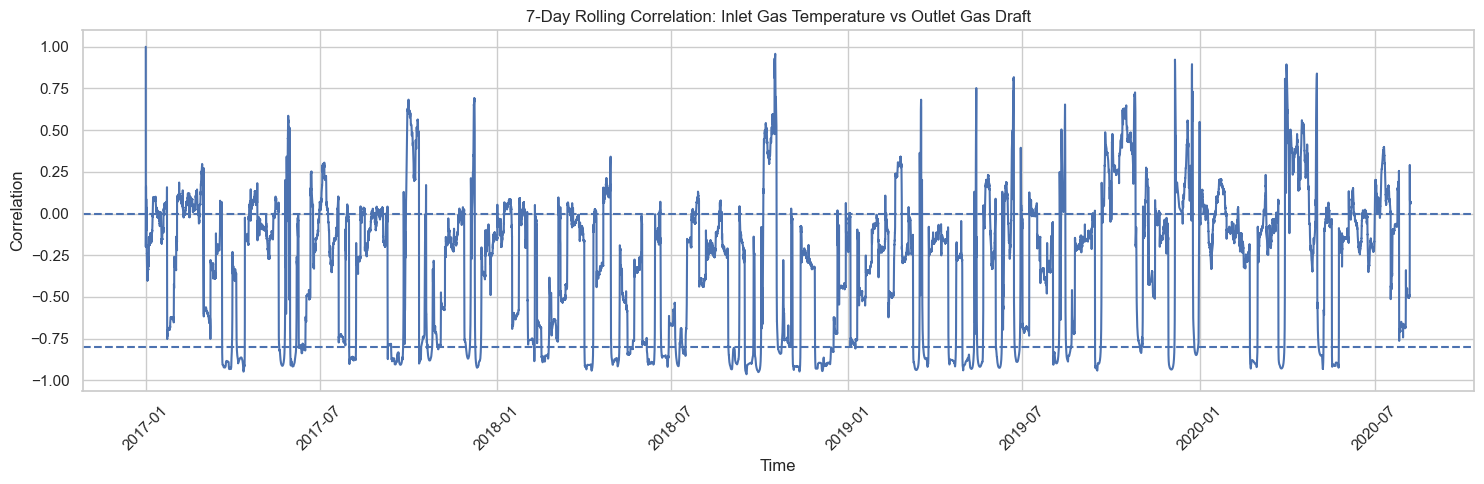

In [16]:
plt.figure(figsize=(15, 5))

plt.plot(
    rolling_corr.index,
    rolling_corr.values
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axhline(
    -0.8,
    linestyle="--"
)

plt.title(
    "7-Day Rolling Correlation: Inlet Gas Temperature vs Outlet Gas Draft"
)

plt.xlabel("Time")
plt.ylabel("Correlation")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### ## Does the sensor relationship change only in the short term, or does it persist for longer periods?

The 7-day rolling correlation shows that the relationship between inlet gas temperature and outlet gas draft changes substantially over time.

To distinguish short-term fluctuations from persistent process changes, we will compare 7-day and 30-day rolling correlations.

In [17]:
# Calculate 7-day and 30-day rolling correlations

temp = (
    df_eda
    .set_index("timestamp")["Cyclone_Inlet_Gas_Temp"]
)

draft = (
    df_eda
    .set_index("timestamp")["Cyclone_Outlet_Gas_draft"]
)

rolling_corr_7d = temp.rolling("7D").corr(draft)
rolling_corr_30d = temp.rolling("30D").corr(draft)

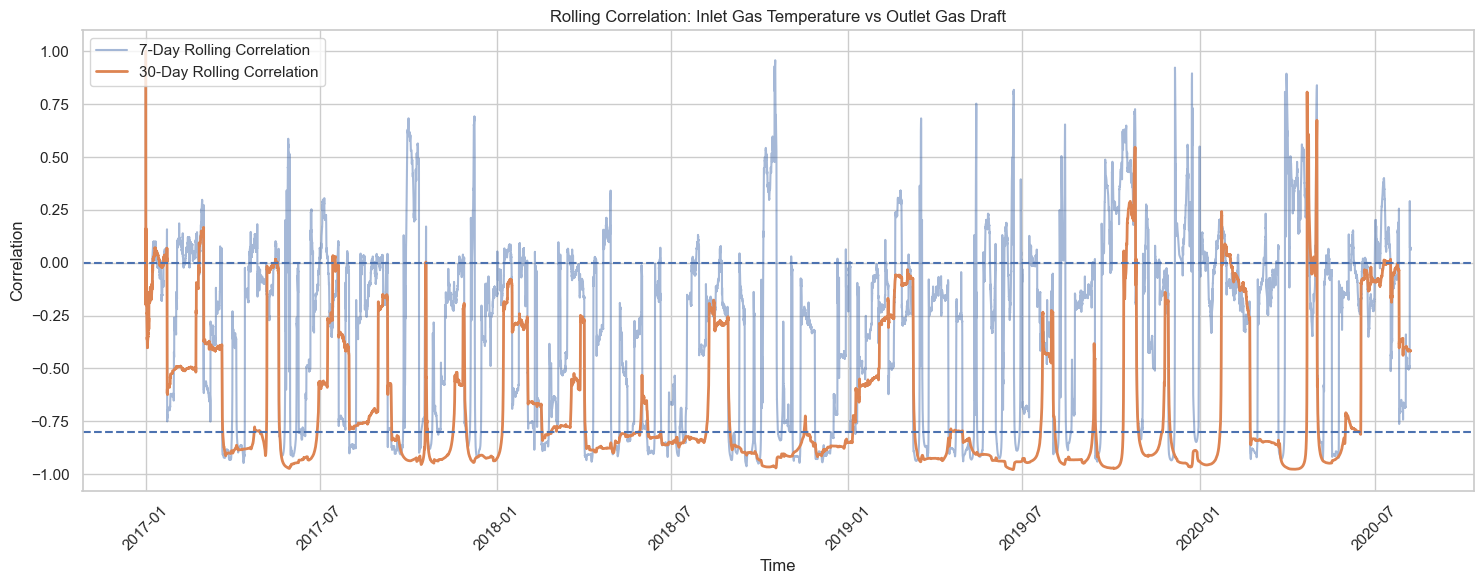

In [18]:
plt.figure(figsize=(15, 6))

plt.plot(
    rolling_corr_7d.index,
    rolling_corr_7d.values,
    alpha=0.5,
    label="7-Day Rolling Correlation"
)

plt.plot(
    rolling_corr_30d.index,
    rolling_corr_30d.values,
    linewidth=2,
    label="30-Day Rolling Correlation"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axhline(
    -0.8,
    linestyle="--"
)

plt.title(
    "Rolling Correlation: Inlet Gas Temperature vs Outlet Gas Draft"
)

plt.xlabel("Time")
plt.ylabel("Correlation")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Does a change in temperature occur before or after a change in draft?

Correlation tells us whether two variables move together.

However, it does not tell us whether one variable changes first and the other responds later.

Because this is time-series process data, we will investigate whether changes in inlet gas temperature are associated with changes in outlet gas draft at different time lags.

In [19]:
# Prepare the two time-series

ts = (
    df_eda
    .set_index("timestamp")
    [["Cyclone_Inlet_Gas_Temp",
      "Cyclone_Outlet_Gas_draft"]]
    .dropna()
)

# Calculate change from one 5-minute observation to the next

ts["temp_change"] = ts["Cyclone_Inlet_Gas_Temp"].diff()
ts["draft_change"] = ts["Cyclone_Outlet_Gas_draft"].diff()

ts.head()

,Cyclone_Inlet_Gas_Temp,Cyclone_Outlet_Gas_draft,temp_change,draft_change
timestamp,,,,
2017-01-01 00:00:00,867.63,-189.54,NaN,NaN
2017-01-01 00:05:00,879.23,-184.33,11.60,5.21
2017-01-01 00:10:00,875.67,-181.26,-3.56,3.07
2017-01-01 00:15:00,875.28,-179.15,-0.39,2.11
2017-01-01 00:20:00,891.66,-178.32,16.38,0.83


In [20]:
# Correlation between temperature changes and
# draft changes at different time lags

lags = range(-288, 289)   # -24 hours to +24 hours

lag_correlations = []

for lag in lags:

    if lag < 0:
        corr = ts["temp_change"].corr(
            ts["draft_change"].shift(-lag)
        )

    else:
        corr = ts["temp_change"].corr(
            ts["draft_change"].shift(-lag)
        )

    lag_correlations.append(corr)

lag_results = pd.DataFrame({
    "lag_steps": list(lags),
    "correlation": lag_correlations
})

lag_results["lag_hours"] = (
    lag_results["lag_steps"] * 5 / 60
)

lag_results.head()

,lag_steps,correlation,lag_hours
0,-288,-0.000316,-24.000000
1,-287,0.000567,-23.916667
2,-286,0.000986,-23.833333
3,-285,-0.002674,-23.750000
4,-284,0.001676,-23.666667


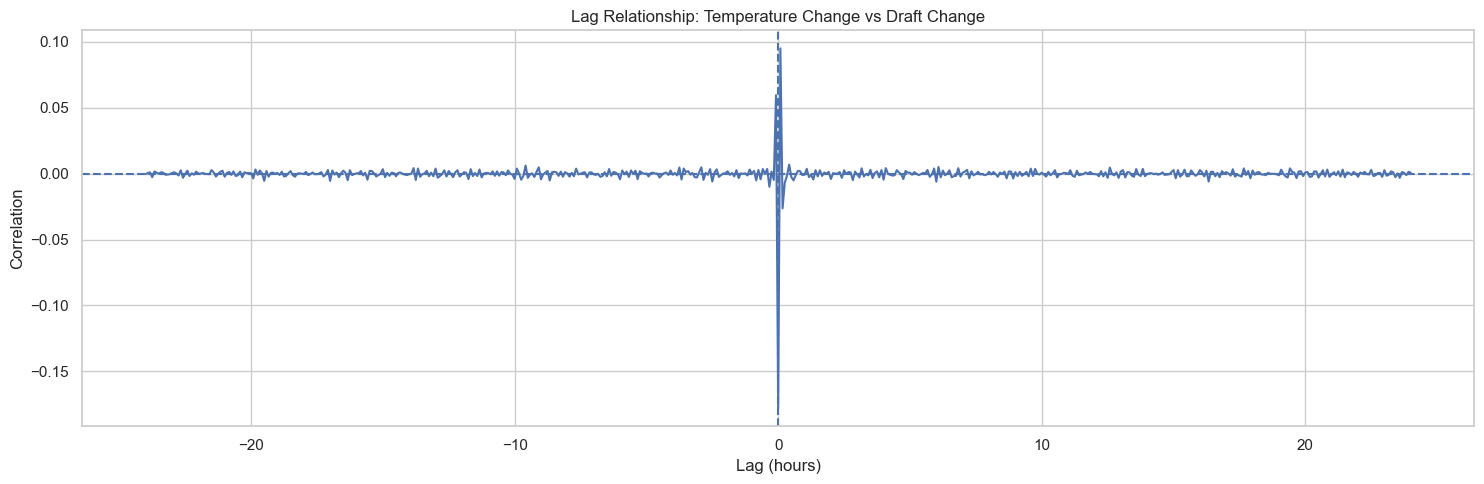

In [21]:
plt.figure(figsize=(15, 5))

plt.plot(
    lag_results["lag_hours"],
    lag_results["correlation"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Lag (hours)")
plt.ylabel("Correlation")

plt.title(
    "Lag Relationship: Temperature Change vs Draft Change"
)

plt.grid(True)
plt.tight_layout()
plt.show()

#### ## Does the lag relationship become clearer after smoothing short-term sensor noise?

The previous lag analysis used 5-minute changes, which can be highly sensitive to short-term fluctuations.

To reduce this noise, we will first smooth the sensor readings using a 1-hour rolling average and then examine the relationship between changes at different time lags.

In [22]:
# Create 1-hour rolling averages

ts_smooth = (
    df_eda
    .set_index("timestamp")
    [["Cyclone_Inlet_Gas_Temp",
      "Cyclone_Outlet_Gas_draft"]]
    .rolling("1H")
    .mean()
    .dropna()
)

# Calculate changes in the smoothed signals

ts_smooth["temp_change"] = (
    ts_smooth["Cyclone_Inlet_Gas_Temp"].diff()
)

ts_smooth["draft_change"] = (
    ts_smooth["Cyclone_Outlet_Gas_draft"].diff()
)

ts_smooth.head()

C:\Users\Sanji\AppData\Local\Temp\ipykernel_21656\1807380287.py:8: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  .rolling("1H")


,Cyclone_Inlet_Gas_Temp,Cyclone_Outlet_Gas_draft,temp_change,draft_change
timestamp,,,,
2017-01-01 00:00:00,867.630000,-189.540000,NaN,NaN
2017-01-01 00:05:00,873.430000,-186.935000,5.800000,2.605000
2017-01-01 00:10:00,874.176667,-185.043333,0.746667,1.891667
2017-01-01 00:15:00,874.452500,-183.570000,0.275833,1.473333
2017-01-01 00:20:00,877.894000,-182.520000,3.441500,1.050000


In [23]:
lags = range(-288, 289)

lag_correlations_smooth = []

for lag in lags:

    corr = (
        ts_smooth["temp_change"]
        .corr(ts_smooth["draft_change"].shift(-lag))
    )

    lag_correlations_smooth.append(corr)

lag_results_smooth = pd.DataFrame({
    "lag_steps": list(lags),
    "correlation": lag_correlations_smooth
})

lag_results_smooth["lag_hours"] = (
    lag_results_smooth["lag_steps"] * 5 / 60
)

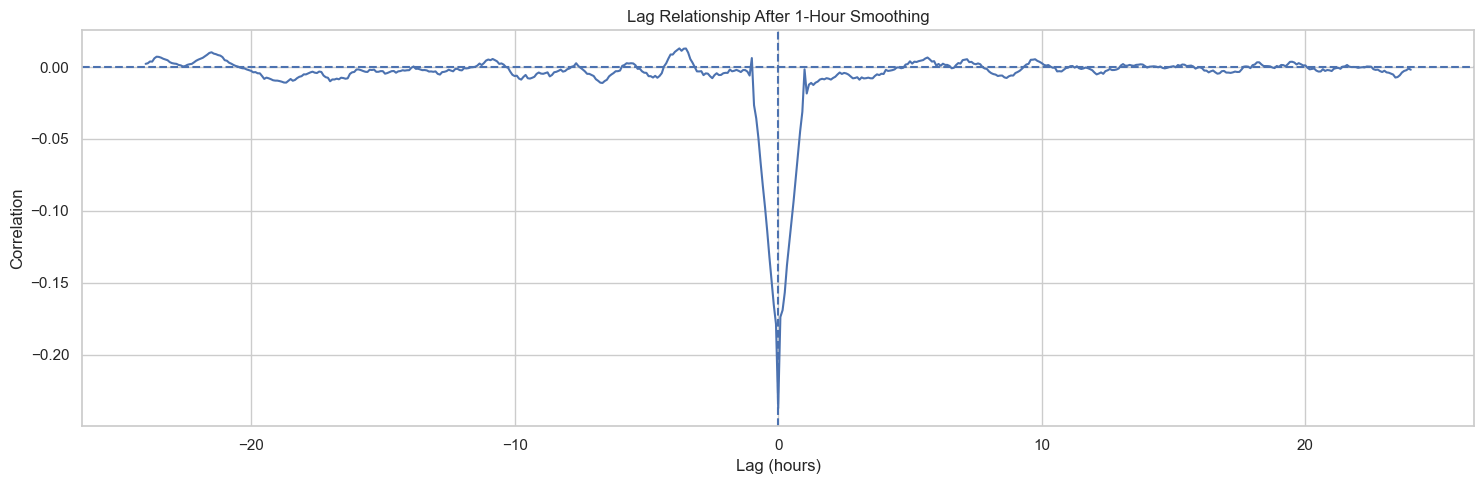

In [24]:
plt.figure(figsize=(15, 5))

plt.plot(
    lag_results_smooth["lag_hours"],
    lag_results_smooth["correlation"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Lag (hours)")
plt.ylabel("Correlation")

plt.title(
    "Lag Relationship After 1-Hour Smoothing"
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
#We do not find a strong and consistent delayed relationship between short-term temperature changes and draft changes within ±24 hours.

#### ## Does the process become more unstable during certain periods?

A process can become abnormal without producing extreme individual values.

To identify periods of increased process instability, we will calculate the rolling standard deviation of each sensor.

A higher rolling standard deviation indicates that the sensor is fluctuating more than usual during that period.

We will use a 1-hour window to examine short-term process stability.

In [26]:
# Calculate 1-hour rolling standard deviation for all sensors

rolling_std_1h = (
    df_eda
    .set_index("timestamp")[SENSOR_COLS]
    .rolling("1H")
    .std()
)

rolling_std_1h.head()

C:\Users\Sanji\AppData\Local\Temp\ipykernel_21656\1649112839.py:6: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  .rolling("1H")


,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
timestamp,,,,,,
2017-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-01 00:05:00,8.202439,5.458864,3.684026,2.786001,7.353911,2.729432
2017-01-01 00:10:00,5.942435,6.897072,4.185837,10.350567,7.241844,2.525015
2017-01-01 00:15:00,4.883239,6.282459,4.512612,8.617869,6.544531,2.896842
2017-01-01 00:20:00,8.780896,8.737477,4.559084,7.638761,8.584639,2.743416


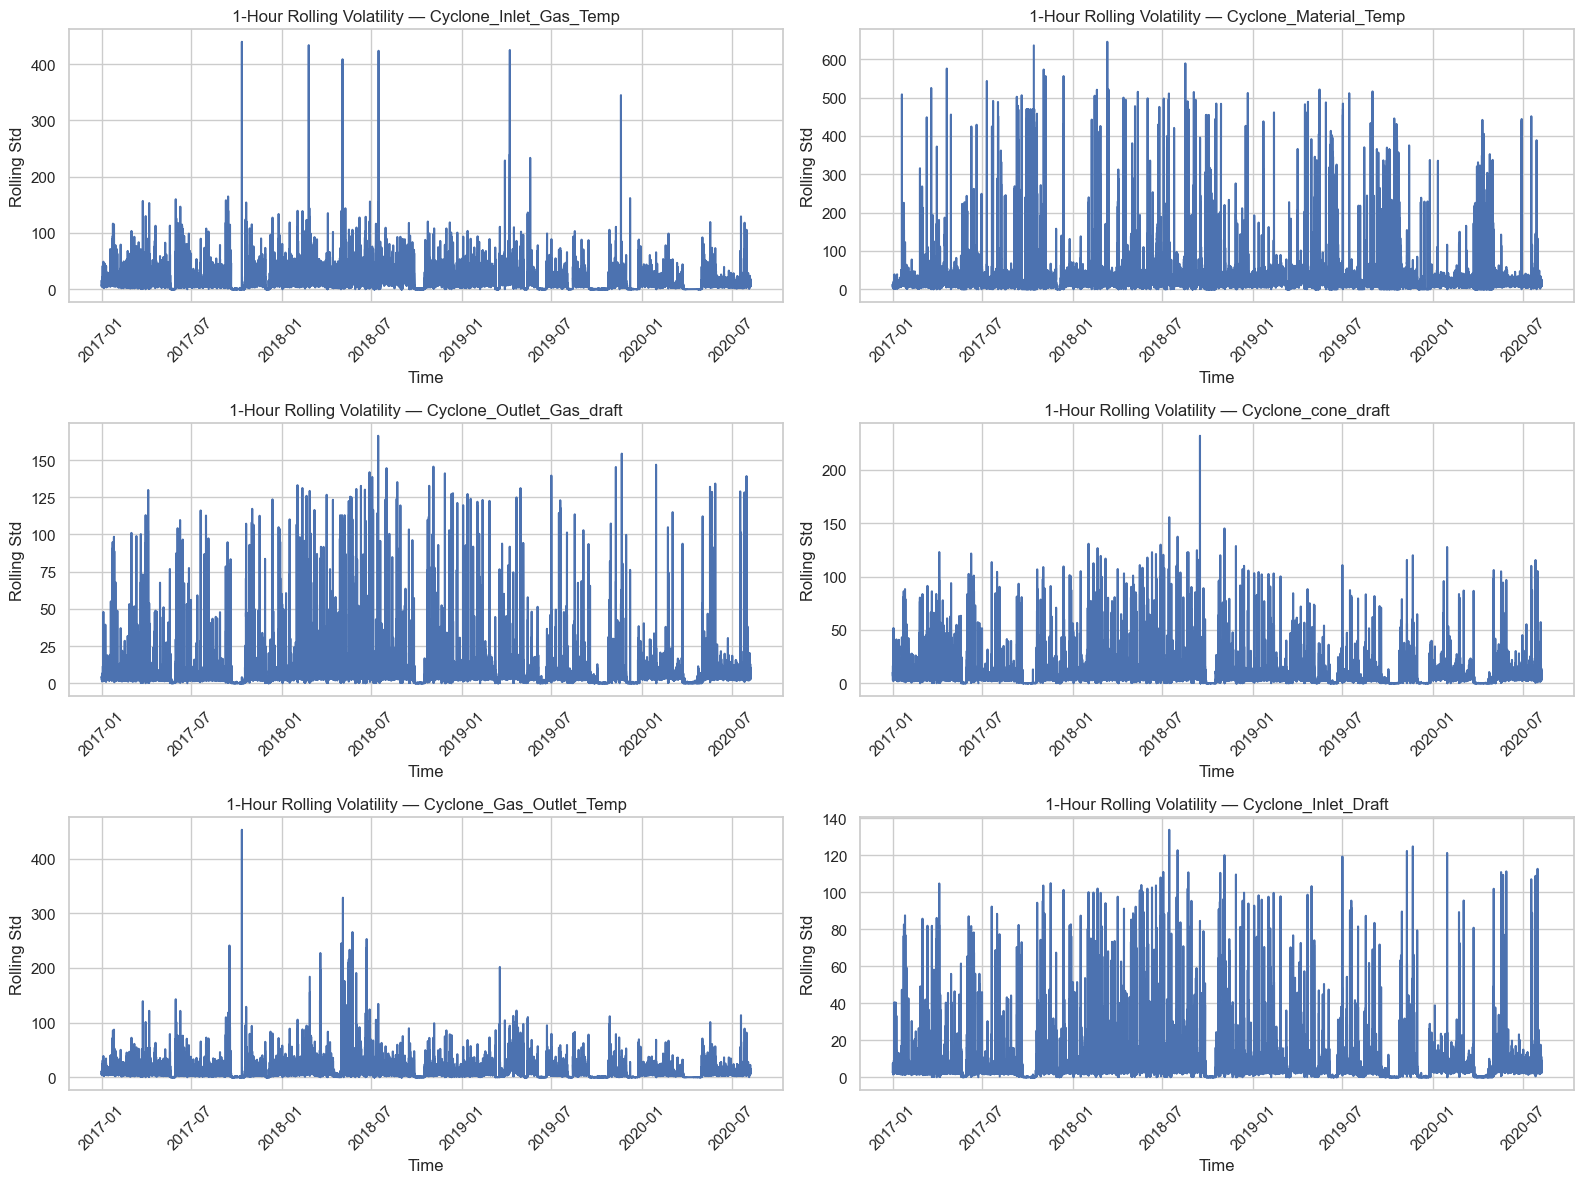

In [27]:
# Plot 1-hour rolling standard deviation

fig, axes = plt.subplots(3, 2, figsize=(16, 12))

for ax, col in zip(axes.flatten(), SENSOR_COLS):

    ax.plot(
        rolling_std_1h.index,
        rolling_std_1h[col]
    )

    ax.set_title(
        f"1-Hour Rolling Volatility — {col}"
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Rolling Std")

    ax.tick_params(axis="x", rotation=45)
    ax.grid(True)

plt.tight_layout()
plt.show()

#### ## Do multiple sensors become unusually unstable at the same time?

The rolling standard deviation showed that different sensors have periods of increased volatility.

However, the sensors operate on different numerical scales, so their raw rolling standard deviations cannot be compared directly.

We will therefore normalize the rolling volatility of each sensor and identify periods where multiple sensors simultaneously show unusually high volatility.

This helps us detect process-level instability rather than isolated sensor fluctuations.

In [28]:
# Normalize rolling volatility for each sensor

volatility_score = pd.DataFrame(
    index=rolling_std_1h.index
)

for col in SENSOR_COLS:

    median = rolling_std_1h[col].median()

    q1 = rolling_std_1h[col].quantile(0.25)
    q3 = rolling_std_1h[col].quantile(0.75)

    iqr = q3 - q1

    volatility_score[col] = (
        (rolling_std_1h[col] - median) / iqr
    )

volatility_score.head()

,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
timestamp,,,,,,
2017-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-01 00:05:00,-0.333681,-0.735387,-0.308474,-0.701531,-0.113254,-0.568491
2017-01-01 00:10:00,-0.505536,-0.652522,-0.174854,1.042758,-0.125492,-0.631119
2017-01-01 00:15:00,-0.586080,-0.687934,-0.087841,0.643221,-0.201644,-0.517202
2017-01-01 00:20:00,-0.289694,-0.546484,-0.075467,0.417451,0.021152,-0.564207


In [29]:
# Count sensors showing unusually high volatility

high_volatility = volatility_score > 3

number_of_unstable_sensors = high_volatility.sum(axis=1)

number_of_unstable_sensors.describe()

count    377719.000000
mean          0.185736
std           0.723021
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           6.000000
dtype: float64

#### ## Do multiple sensors become unusually unstable at the same time?

A process-level abnormality is more meaningful when several sensors show unusual behavior simultaneously.

Because each sensor has a different scale, we first normalize its rolling volatility relative to its own historical behavior.

We then count how many sensors are simultaneously showing unusually high volatility.

In [30]:
# Normalize each sensor's rolling volatility
# using its own median and IQR

volatility_score = pd.DataFrame(
    index=rolling_std_1h.index
)

for col in SENSOR_COLS:
    median = rolling_std_1h[col].median()

    q1 = rolling_std_1h[col].quantile(0.25)
    q3 = rolling_std_1h[col].quantile(0.75)

    iqr = q3 - q1

    volatility_score[col] = (
        (rolling_std_1h[col] - median) / iqr
    )

volatility_score.head()

,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
timestamp,,,,,,
2017-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-01 00:05:00,-0.333681,-0.735387,-0.308474,-0.701531,-0.113254,-0.568491
2017-01-01 00:10:00,-0.505536,-0.652522,-0.174854,1.042758,-0.125492,-0.631119
2017-01-01 00:15:00,-0.586080,-0.687934,-0.087841,0.643221,-0.201644,-0.517202
2017-01-01 00:20:00,-0.289694,-0.546484,-0.075467,0.417451,0.021152,-0.564207


#### Do multiple sensors become unusually unstable at the same time?

The volatility score measures how unusual the current volatility is for each sensor compared with its own historical behavior.

We now identify time points where a sensor has a volatility score greater than 3 and count how many sensors are simultaneously showing unusually high volatility.

This helps us identify process-level instability rather than isolated sensor fluctuations.

In [31]:
# Identify unusually high volatility

high_volatility = volatility_score > 3

# Count how many sensors are highly volatile at each timestamp

number_of_unstable_sensors = high_volatility.sum(axis=1)

number_of_unstable_sensors.describe()

count    377719.000000
mean          0.185736
std           0.723021
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           6.000000
dtype: float64

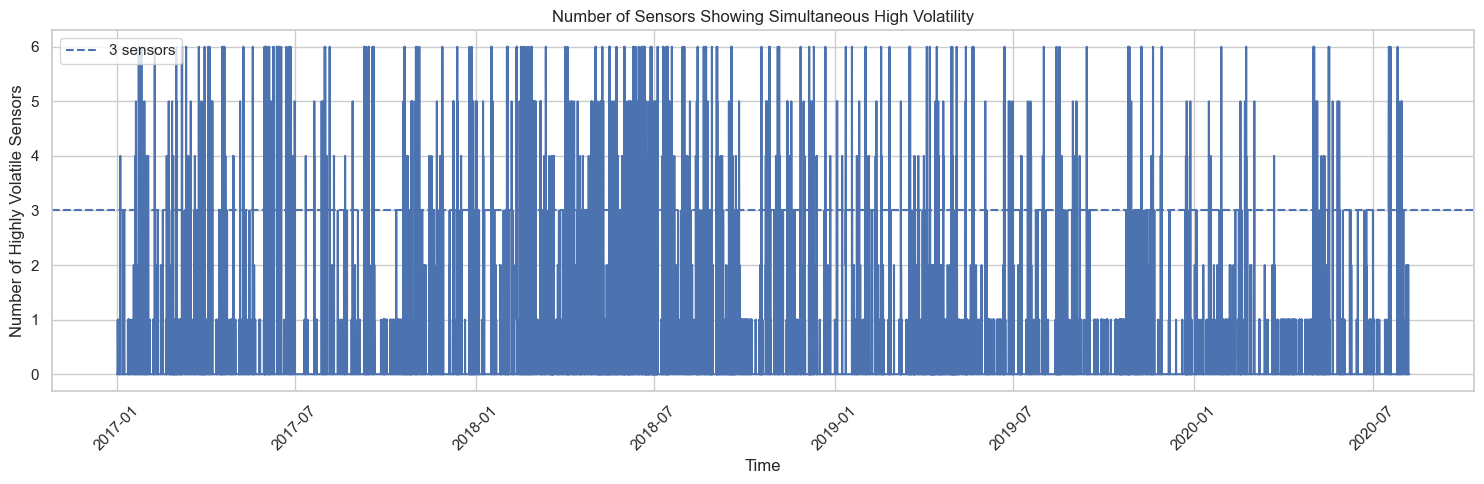

In [32]:
plt.figure(figsize=(15, 5))

plt.plot(
    number_of_unstable_sensors.index,
    number_of_unstable_sensors.values
)

plt.axhline(
    3,
    linestyle="--",
    label="3 sensors"
)

plt.xlabel("Time")
plt.ylabel("Number of Highly Volatile Sensors")

plt.title(
    "Number of Sensors Showing Simultaneous High Volatility"
)

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### How frequently do multiple sensors become unusually volatile together?

The previous analysis showed that the number of highly volatile sensors can reach all six sensors simultaneously.

We now quantify how frequently 3, 4, 5, or 6 sensors are simultaneously above the high-volatility threshold.

This helps us distinguish isolated sensor behavior from coordinated process-level instability.

In [33]:
# Count timestamps by number of highly volatile sensors

simultaneous_counts = (
    number_of_unstable_sensors
    .value_counts()
    .sort_index()
)

simultaneous_counts

0    342854
1     20133
2      3579
3      5669
4      2549
5      1948
6       987
Name: count, dtype: int64

In [34]:
# Calculate percentage of timestamps

simultaneous_percentage = (
    simultaneous_counts
    / len(number_of_unstable_sensors)
    * 100
)

simultaneous_summary = pd.DataFrame({
    "timestamp_count": simultaneous_counts,
    "percentage": simultaneous_percentage
})

simultaneous_summary

,timestamp_count,percentage
0,342854,90.769593
1,20133,5.330153
2,3579,0.947530
3,5669,1.500851
4,2549,0.674840
5,1948,0.515727
6,987,0.261305


In [35]:
# Focus on process-level instability
# where at least 3 sensors are highly volatile

process_instability = simultaneous_summary[
    simultaneous_summary.index >= 3
]

process_instability

,timestamp_count,percentage
3,5669,1.500851
4,2549,0.674840
5,1948,0.515727
6,987,0.261305


#### Can we group consecutive abnormal timestamps into continuous events?

Individual timestamps are difficult to interpret operationally.

If multiple consecutive timestamps show simultaneous high volatility, they may represent one continuous period of process instability.

We therefore group consecutive candidate timestamps into abnormal events and calculate the start time, end time, duration, and number of observations for each event.

In [36]:
# Candidate process-level instability

candidate_instability = (
    number_of_unstable_sensors >= 3
)

candidate_instability.sum()

np.int64(11153)

In [37]:
# Create candidate event dataframe

candidate_events = pd.DataFrame({
    "timestamp": number_of_unstable_sensors.index,
    "unstable_sensor_count": number_of_unstable_sensors.values,
    "candidate": candidate_instability.values
})

candidate_events.head()

,timestamp,unstable_sensor_count,candidate
0,2017-01-01 00:00:00,0,False
1,2017-01-01 00:05:00,0,False
2,2017-01-01 00:10:00,0,False
3,2017-01-01 00:15:00,0,False
4,2017-01-01 00:20:00,0,False


In [38]:
# Identify continuous candidate periods

candidate_events["event_group"] = (
    candidate_events["candidate"]
    != candidate_events["candidate"].shift()
).cumsum()

In [39]:
candidate_periods = candidate_events[
    candidate_events["candidate"]
].copy()

In [40]:
# Summarize candidate abnormal events

event_summary = (
    candidate_periods
    .groupby("event_group")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        observations=("timestamp", "count"),
        max_unstable_sensors=("unstable_sensor_count", "max"),
        mean_unstable_sensors=("unstable_sensor_count", "mean")
    )
    .reset_index()
)

event_summary["duration_minutes"] = (
    (
        event_summary["end_time"]
        - event_summary["start_time"]
    ).dt.total_seconds() / 60
    + 5
)

event_summary.head(20)

,event_group,start_time,end_time,observations,max_unstable_sensors,mean_unstable_sensors,duration_minutes
0,2,2017-01-04 05:30:00,2017-01-04 06:35:00,14,4,3.285714,70.0
1,4,2017-01-06 23:50:00,2017-01-07 00:55:00,14,3,3.000000,70.0
2,6,2017-01-08 05:15:00,2017-01-08 06:20:00,14,3,3.000000,70.0
3,8,2017-01-19 09:00:00,2017-01-19 10:15:00,16,4,3.625000,80.0
4,10,2017-01-20 04:45:00,2017-01-20 05:40:00,12,5,4.166667,60.0
5,12,2017-01-22 23:25:00,2017-01-23 03:20:00,48,6,4.083333,240.0
6,14,2017-01-23 05:40:00,2017-01-23 08:45:00,38,5,3.815789,190.0
7,16,2017-01-23 13:05:00,2017-01-23 13:55:00,11,5,4.181818,55.0
8,18,2017-01-23 14:55:00,2017-01-23 16:15:00,17,6,4.647059,85.0
9,20,2017-01-25 16:20:00,2017-01-25 17:15:00,12,6,4.416667,60.0


#### Which candidate instability events are the most significant?

We have identified candidate periods where at least three sensors simultaneously show unusually high volatility.

Before treating these as abnormal events, we will rank them using:
- maximum number of affected sensors,
- average number of affected sensors,
- event duration.

This allows us to focus our investigation on the strongest candidate periods first.

In [41]:
# Rank candidate events by severity

event_summary_ranked = event_summary.sort_values(
    by=[
        "max_unstable_sensors",
        "mean_unstable_sensors",
        "duration_minutes"
    ],
    ascending=False
).reset_index(drop=True)

event_summary_ranked.head(20)

,event_group,start_time,end_time,observations,max_unstable_sensors,mean_unstable_sensors,duration_minutes
0,1326,2018-11-27 05:40:00,2018-11-27 06:30:00,11,6,5.818182,55.0
1,534,2018-02-11 12:15:00,2018-02-11 13:10:00,12,6,5.666667,60.0
2,1914,2020-07-19 04:45:00,2020-07-19 07:05:00,29,6,5.551724,145.0
3,330,2017-10-20 14:35:00,2017-10-20 14:50:00,4,6,5.500000,20.0
4,186,2017-06-03 16:10:00,2017-06-03 18:35:00,30,6,5.466667,150.0
5,284,2017-09-09 04:50:00,2017-09-09 06:00:00,15,6,5.466667,75.0
6,856,2018-06-01 02:15:00,2018-06-01 03:10:00,12,6,5.416667,60.0
7,1542,2019-05-05 00:50:00,2019-05-05 01:50:00,13,6,5.384615,65.0
8,1650,2019-08-17 12:55:00,2019-08-17 13:45:00,11,6,5.363636,55.0
9,1554,2019-05-22 02:40:00,2019-05-22 03:45:00,14,6,5.357143,70.0


#### Can we create a simple candidate-event severity score?

To prioritize investigation, we combine three characteristics of each candidate event:

1. How many sensors were affected at the peak.
2. How many sensors were affected on average.
3. How long the instability lasted.

This score is only used for investigation priority; it is not the final anomaly score.

In [42]:
event_summary_ranked["severity_score"] = (
    event_summary_ranked["max_unstable_sensors"]
    * event_summary_ranked["mean_unstable_sensors"]
    * np.log1p(event_summary_ranked["duration_minutes"])
)

event_summary_ranked = event_summary_ranked.sort_values(
    "severity_score",
    ascending=False
).reset_index(drop=True)

event_summary_ranked.head(15)

,event_group,start_time,end_time,observations,max_unstable_sensors,mean_unstable_sensors,duration_minutes,severity_score
0,1914,2020-07-19 04:45:00,2020-07-19 07:05:00,29,6,5.551724,145.0,166.005655
1,440,2017-12-25 06:15:00,2017-12-25 10:10:00,48,6,5.020833,240.0,165.229508
2,186,2017-06-03 16:10:00,2017-06-03 18:35:00,30,6,5.466667,150.0,164.566779
3,1698,2019-10-26 12:05:00,2019-10-26 16:00:00,48,6,4.958333,240.0,163.172709
4,264,2017-08-05 03:20:00,2017-08-05 06:20:00,37,6,5.054054,185.0,158.467237
5,944,2018-06-19 22:00:00,2018-06-20 00:50:00,35,6,5.085714,175.0,157.773626
6,176,2017-05-31 20:00:00,2017-05-31 23:20:00,41,6,4.902439,205.0,156.717528
7,580,2018-02-22 12:25:00,2018-02-22 14:35:00,27,6,5.259259,135.0,155.021554
8,116,2017-03-30 23:40:00,2017-03-31 01:30:00,23,6,5.347826,115.0,152.528242
9,996,2018-06-27 15:20:00,2018-06-27 19:20:00,49,6,4.530612,245.0,149.655135


In [43]:
top_event = event_summary_ranked.iloc[0]

top_event

event_group                             1914
start_time               2020-07-19 04:45:00
end_time                 2020-07-19 07:05:00
observations                              29
max_unstable_sensors                       6
mean_unstable_sensors               5.551724
duration_minutes                       145.0
severity_score                    166.005655
Name: 0, dtype: object

#### What actually happened during a candidate instability event?

A volatility-based candidate should be investigated using the original sensor values.

We will examine all six process variables around the selected event to determine whether the sensors show coordinated process changes or whether the signal may simply be caused by noisy measurements.

In [44]:
# Select the top candidate event

event_start = top_event["start_time"]
event_end = top_event["end_time"]

# Add context before and after the event

context_start = event_start - pd.Timedelta(hours=2)
context_end = event_end + pd.Timedelta(hours=2)

event_data = df_eda[
    (df_eda["timestamp"] >= context_start) &
    (df_eda["timestamp"] <= context_end)
]

print("Event:")
print(event_start)
print("to")
print(event_end)

print("\nContext:")
print(context_start)
print("to")
print(context_end)

Event:
2020-07-19 04:45:00
to
2020-07-19 07:05:00

Context:
2020-07-19 02:45:00
to
2020-07-19 09:05:00


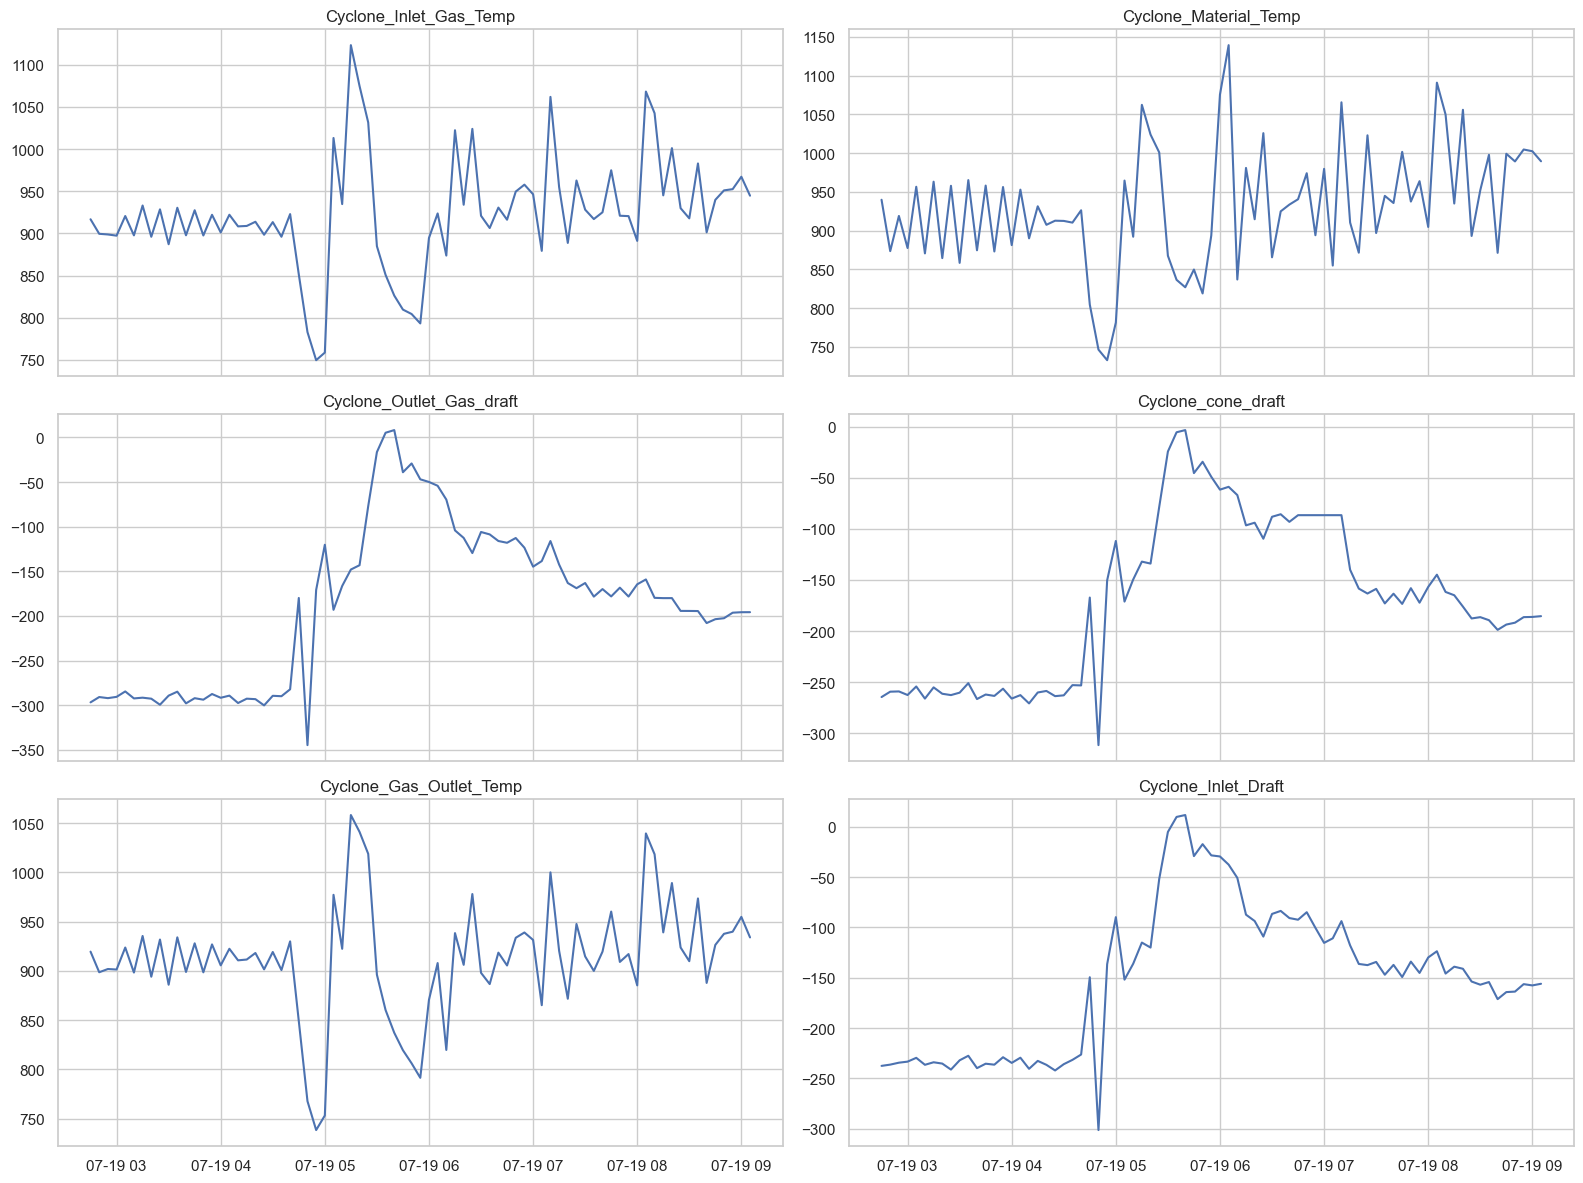

In [45]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 12),
    sharex=True
)

for ax, col in zip(axes.flatten(), SENSOR_COLS):

    ax.plot(
        event_data["timestamp"],
        event_data[col]
    )

    ax.set_title(col)
    ax.grid(True)

plt.tight_layout()
plt.show()

#### How different was the candidate event from normal process behavior?

Visual inspection shows coordinated changes across multiple sensors during the candidate event.

We now quantify the event by comparing the sensor behavior during the event with the surrounding baseline period.

This helps determine whether the observed changes are large and coordinated enough to support the candidate abnormality.

In [46]:
# Statistics during the candidate event

event_stats = event_data[SENSOR_COLS].agg(
    ["mean", "std", "min", "max"]
).T

event_stats

,mean,std,min,max
Cyclone_Inlet_Gas_Temp,923.274545,66.703695,749.74,1123.07
Cyclone_Material_Temp,930.570909,77.253732,732.69,1139.22
Cyclone_Outlet_Gas_draft,-187.324675,88.381274,-344.56,8.13
Cyclone_cone_draft,-169.708831,79.038100,-311.61,-3.32
Cyclone_Gas_Outlet_Temp,912.383117,58.263208,738.56,1058.14
Cyclone_Inlet_Draft,-150.082727,73.366433,-301.49,11.86


In [47]:
# Baseline period before the event(statistics from the 2-hour context before the event:)

baseline_data = df_eda[
    (df_eda["timestamp"] >= event_start - pd.Timedelta(hours=2)) &
    (df_eda["timestamp"] < event_start)
]

baseline_stats = baseline_data[SENSOR_COLS].agg(
    ["mean", "std", "min", "max"]
).T

baseline_stats

,mean,std,min,max
Cyclone_Inlet_Gas_Temp,909.793750,13.540848,887.14,933.05
Cyclone_Material_Temp,913.771667,36.393803,858.26,965.07
Cyclone_Outlet_Gas_draft,-291.660417,4.513118,-300.08,-282.07
Cyclone_cone_draft,-260.649167,4.920854,-270.79,-250.97
Cyclone_Gas_Outlet_Temp,912.402083,14.480377,885.97,935.46
Cyclone_Inlet_Draft,-234.579583,4.232843,-242.21,-226.37


In [48]:
# Compare event vs baseline

comparison = pd.DataFrame({
    "baseline_mean": baseline_stats["mean"],
    "event_mean": event_stats["mean"],
    "baseline_std": baseline_stats["std"],
    "event_std": event_stats["std"],
    "baseline_min": baseline_stats["min"],
    "event_min": event_stats["min"],
    "baseline_max": baseline_stats["max"],
    "event_max": event_stats["max"]
})

comparison

,baseline_mean,event_mean,baseline_std,event_std,baseline_min,event_min,baseline_max,event_max
Cyclone_Inlet_Gas_Temp,909.793750,923.274545,13.540848,66.703695,887.14,749.74,933.05,1123.07
Cyclone_Material_Temp,913.771667,930.570909,36.393803,77.253732,858.26,732.69,965.07,1139.22
Cyclone_Outlet_Gas_draft,-291.660417,-187.324675,4.513118,88.381274,-300.08,-344.56,-282.07,8.13
Cyclone_cone_draft,-260.649167,-169.708831,4.920854,79.038100,-270.79,-311.61,-250.97,-3.32
Cyclone_Gas_Outlet_Temp,912.402083,912.383117,14.480377,58.263208,885.97,738.56,935.46,1058.14
Cyclone_Inlet_Draft,-234.579583,-150.082727,4.232843,73.366433,-242.21,-301.49,-226.37,11.86


In [49]:
# Outlet Gas Draft
# Normal SD:  4.5
# Event SD:  88.4

# Cone Draft
# Normal SD:  4.9
# Event SD:  79.0

# Inlet Draft
# Normal SD:  4.2
# Event SD:  73.4

#This candidate period represents a coordinated change in the behavior of multiple process variables, not merely an isolated spike in one sensor.

#### How unusual is the overall process state at each timestamp?

The previous analysis identified candidate events using volatility.

We now want a timestamp-level anomaly score that considers all six process variables simultaneously.

For each sensor, we compare the current value with its historical distribution using a robust standardized score.

We then combine the six sensor-level scores into one overall process anomaly score.

This provides a simple statistical baseline before applying more advanced multivariate methods.

In [50]:
# Calculate robust anomaly scores for each sensor

# I have used median + IQR, rather than mean + standard deviation, because our data contains extreme values.

robust_scores = pd.DataFrame(
    index=df_eda.index
)

for col in SENSOR_COLS:

    median = df_eda[col].median()

    q1 = df_eda[col].quantile(0.25)
    q3 = df_eda[col].quantile(0.75)

    iqr = q3 - q1

    robust_scores[col] = (
        (df_eda[col] - median) / iqr
    )

robust_scores.head()

,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
0,-0.328947,-0.038688,0.333766,0.150607,-0.199250,0.411744
1,-0.070250,0.062901,0.401376,0.198003,-0.092408,0.344285
2,-0.149643,0.142382,0.441215,0.386022,-0.056143,0.427298
3,-0.158341,0.128829,0.468596,0.285457,-0.058301,0.465571
4,0.206958,0.275027,0.479367,0.298809,0.046589,0.455610


#### How unusual is the complete six-sensor process state?

A process abnormality may involve several sensors simultaneously.

We therefore combine the absolute robust scores across all six sensors using the Euclidean magnitude.

A high score means that the overall process state is far from its typical historical state.

In [51]:
# Combine six sensor scores into one process-level score

process_anomaly_score = np.sqrt(
    (robust_scores ** 2).sum(axis=1)
)

process_anomaly_score.describe()

count    377719.000000
mean          5.649358
std           8.848985
min           0.000000
25%           0.789089
50%           1.209946
75%           2.410254
max          25.836427
dtype: float64

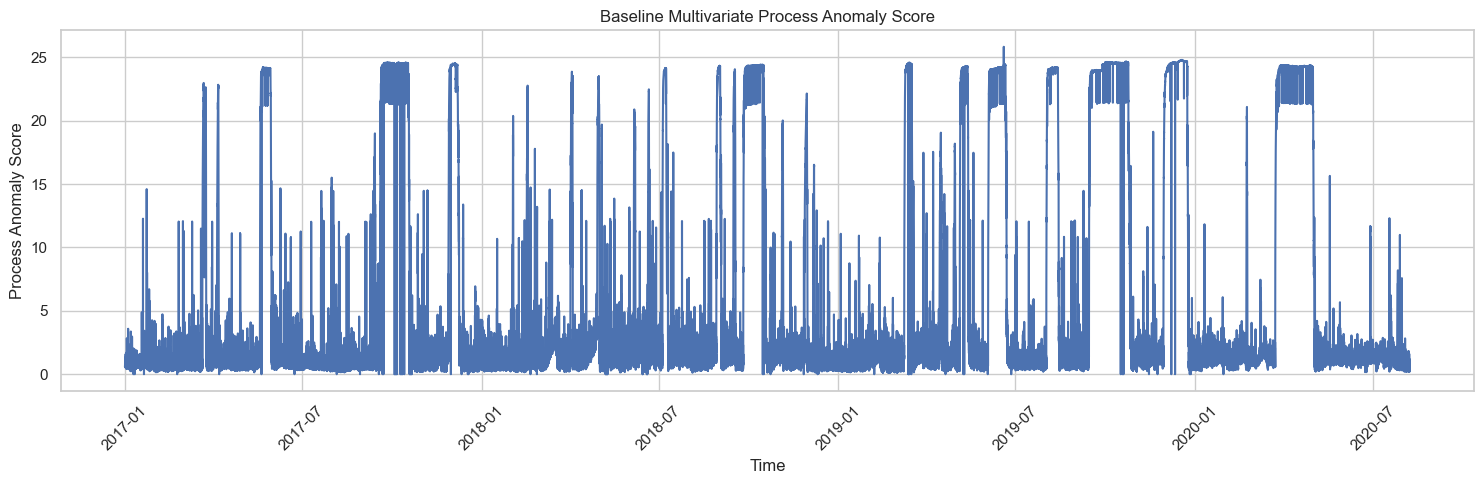

In [52]:
plt.figure(figsize=(15, 5))

plt.plot(
    df_eda["timestamp"],
    process_anomaly_score
)

plt.xlabel("Time")
plt.ylabel("Process Anomaly Score")

plt.title(
    "Baseline Multivariate Process Anomaly Score"
)

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [53]:
process_anomaly_score.describe()

count    377719.000000
mean          5.649358
std           8.848985
min           0.000000
25%           0.789089
50%           1.209946
75%           2.410254
max          25.836427
dtype: float64

#### How extreme are the highest process anomaly scores?

The baseline process anomaly score is strongly right-skewed, with most observations having relatively low scores and a small number of observations having much larger scores.

We will examine high percentiles of the score distribution to understand where the extreme tail begins.

In [54]:
# Examine the upper tail of the process anomaly score

score_percentiles = process_anomaly_score.quantile(
    [0.90, 0.95, 0.975, 0.99, 0.995, 0.999]
)

score_percentiles

0.900    24.239770
0.950    24.446025
0.975    24.544531
0.990    24.596134
0.995    24.669886
0.999    24.763344
dtype: float64

#### Which timestamps have the highest overall anomaly scores?

We now identify the timestamps with the highest process-level scores.

These timestamps will become candidates for detailed investigation rather than being immediately labelled as confirmed abnormalities.

In [55]:
top_anomalies = (
    pd.DataFrame({
        "timestamp": df_eda["timestamp"],
        "anomaly_score": process_anomaly_score
    })
    .sort_values(
        "anomaly_score",
        ascending=False
    )
)

top_anomalies.head(20)

,timestamp,anomaly_score
258377,2019-06-19 03:15:00,25.836427
258378,2019-06-19 03:20:00,25.836267
258379,2019-06-19 03:25:00,25.835135
310853,2019-12-18 08:15:00,24.805009
310850,2019-12-18 08:00:00,24.804340
310852,2019-12-18 08:10:00,24.804333
310851,2019-12-18 08:05:00,24.804273
310849,2019-12-18 07:55:00,24.803868
310854,2019-12-18 08:20:00,24.803346
310848,2019-12-18 07:50:00,24.803191


#### Do the highest anomaly-score timestamps overlap with our candidate instability events?

We previously identified candidate events using simultaneous high volatility.

We now compare those events with the timestamps having the highest multivariate anomaly scores.

If both approaches identify the same periods, we have stronger evidence that those periods represent unusual process behavior.

In [56]:
# Define the extreme tail of the baseline anomaly score

anomaly_threshold = process_anomaly_score.quantile(0.99)

print("99th percentile threshold:", anomaly_threshold)

99th percentile threshold: 24.596133631435737


In [57]:
# Identify timestamps in the top 1% of anomaly scores

statistical_anomaly = (
    process_anomaly_score >= anomaly_threshold
)

print("Candidate statistical anomalies:")
print(statistical_anomaly.sum())

print(
    "Percentage:",
    statistical_anomaly.mean() * 100
)

Candidate statistical anomalies:
3778
Percentage: 1.0002144451298454


In [58]:
# Add statistical anomaly flag to our candidate event dataframe

candidate_events["statistical_anomaly"] = (
    statistical_anomaly.values
)

candidate_events.head()

,timestamp,unstable_sensor_count,candidate,event_group,statistical_anomaly
0,2017-01-01 00:00:00,0,False,1,False
1,2017-01-01 00:05:00,0,False,1,False
2,2017-01-01 00:10:00,0,False,1,False
3,2017-01-01 00:15:00,0,False,1,False
4,2017-01-01 00:20:00,0,False,1,False


In [59]:
# Calculate how many statistical anomalies
# occur inside each volatility event

event_validation = (
    candidate_events[
        candidate_events["candidate"]
    ]
    .groupby("event_group")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        observations=("timestamp", "count"),
        max_unstable_sensors=("unstable_sensor_count", "max"),
        statistical_anomalies=("statistical_anomaly", "sum")
    )
    .reset_index()
)

event_validation["anomaly_percentage"] = (
    event_validation["statistical_anomalies"]
    / event_validation["observations"]
    * 100
)

event_validation.sort_values(
    "anomaly_percentage",
    ascending=False
).head(20)

,event_group,start_time,end_time,observations,max_unstable_sensors,statistical_anomalies,anomaly_percentage
971,1944,2020-08-01 08:20:00,2020-08-01 09:15:00,12,3,0,0.0
0,2,2017-01-04 05:30:00,2017-01-04 06:35:00,14,4,0,0.0
1,4,2017-01-06 23:50:00,2017-01-07 00:55:00,14,3,0,0.0
2,6,2017-01-08 05:15:00,2017-01-08 06:20:00,14,3,0,0.0
3,8,2017-01-19 09:00:00,2017-01-19 10:15:00,16,4,0,0.0
4,10,2017-01-20 04:45:00,2017-01-20 05:40:00,12,5,0,0.0
5,12,2017-01-22 23:25:00,2017-01-23 03:20:00,48,6,0,0.0
6,14,2017-01-23 05:40:00,2017-01-23 08:45:00,38,5,0,0.0
7,16,2017-01-23 13:05:00,2017-01-23 13:55:00,11,5,0,0.0
8,18,2017-01-23 14:55:00,2017-01-23 16:15:00,17,6,0,0.0


## PCA-based Multivariate Process Monitoring

#### Does the six-sensor process state deviate from its normal multivariate structure?

The six process variables are strongly correlated.

Instead of evaluating each sensor independently, PCA is used to represent the dominant relationships between the process variables.

We then measure how far each observation deviates from this learned multivariate structure.

This provides a process-level anomaly signal that considers the interaction between all six sensors.

In [60]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Keep rows where all six sensors have valid numeric values
pca_data = df_eda[SENSOR_COLS].dropna()

print("Rows available for PCA:", len(pca_data))

Rows available for PCA: 376124


In [61]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(pca_data)

print("Scaled shape:", X_scaled.shape)

Scaled shape: (376124, 6)


In [62]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pd.DataFrame({
    "Component": range(1, len(SENSOR_COLS) + 1),
    "Explained_Variance": pca.explained_variance_ratio_,
    "Cumulative_Variance": np.cumsum(
        pca.explained_variance_ratio_
    )
})

explained_variance

,Component,Explained_Variance,Cumulative_Variance
0,1,0.937743,0.937743
1,2,0.045319,0.983062
2,3,0.008152,0.991214
3,4,0.006620,0.997834
4,5,0.001421,0.999255
5,6,0.000745,1.000000


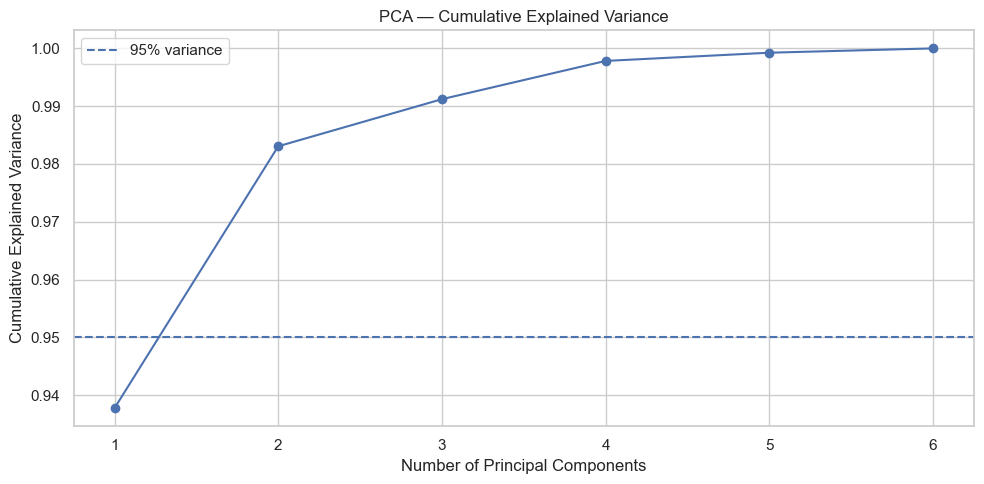

In [63]:
plt.figure(figsize=(10, 5))

plt.plot(
    explained_variance["Component"],
    explained_variance["Cumulative_Variance"],
    marker="o"
)

plt.axhline(
    0.95,
    linestyle="--",
    label="95% variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")

plt.title(
    "PCA — Cumulative Explained Variance"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

#### What do the principal components represent?

PCA has compressed the six process variables into a smaller number of underlying components.

We now inspect the PCA loadings to understand which sensors contribute most strongly to each component.

This helps us interpret the dominant multivariate process patterns before using PCA for anomaly detection.

In [64]:
# Inspect PCA loadings

loadings = pd.DataFrame(
    pca.components_.T,
    index=SENSOR_COLS,
    columns=[
        f"PC{i}"
        for i in range(1, len(SENSOR_COLS) + 1)
    ]
)

loadings

,PC1,PC2,PC3,PC4,PC5,PC6
Cyclone_Inlet_Gas_Temp,0.410689,0.385592,-0.339505,-0.067418,0.744499,-0.092554
Cyclone_Material_Temp,0.403342,0.444637,0.788699,0.102900,-0.083512,0.002346
Cyclone_Outlet_Gas_draft,-0.409729,0.413541,0.021160,-0.410006,-0.101964,-0.694376
Cyclone_cone_draft,-0.406946,0.388504,-0.112940,0.817556,0.043186,-0.021021
Cyclone_Gas_Outlet_Temp,0.409133,0.394871,-0.498632,-0.016463,-0.648694,0.083534
Cyclone_Inlet_Draft,-0.409607,0.419216,0.029218,-0.384829,0.075375,0.708415


<Figure size 1000x600 with 0 Axes>

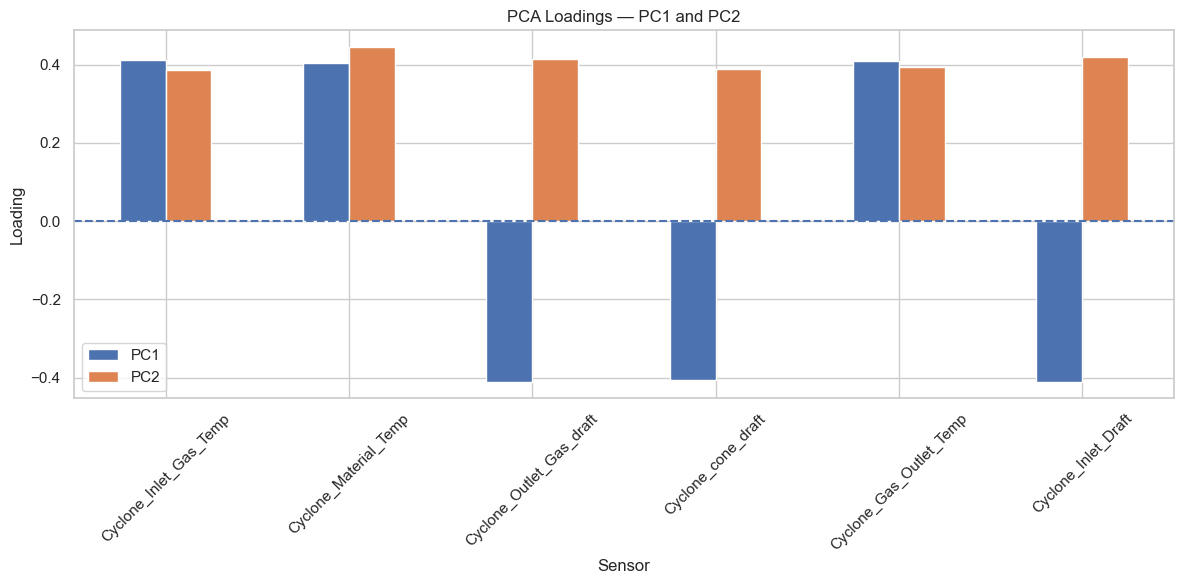

In [65]:
plt.figure(figsize=(10, 6))

loadings[["PC1", "PC2"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.axhline(0, linestyle="--")

plt.xlabel("Sensor")
plt.ylabel("Loading")

plt.title(
    "PCA Loadings — PC1 and PC2"
)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Which observations are unusual in the main PCA process space?

The first two principal components explain approximately 98% of the total variance.

We therefore use these components to represent the dominant multivariate process behavior.

Observations that are unusually far from the center of this PCA space are candidates for abnormal process states.

In [66]:
# Keep the first two principal components

X_pc2 = X_pca[:, :2]

print("PCA representation shape:", X_pc2.shape)

PCA representation shape: (376124, 2)


#### How far is each observation from the normal PCA center?

We calculate the Euclidean distance of each observation from the center of the two-dimensional PCA space.

A larger distance means that the overall combination of sensor values is further from the typical process state.

In [67]:
# Calculate distance from the PCA center

pc_center = X_pc2.mean(axis=0)

t2_score = np.sum(
    (X_pc2 - pc_center) ** 2,
    axis=1
)

t2_score = pd.Series(
    t2_score,
    index=pca_data.index,
    name="T2_score"
)

t2_score.describe()

count    376124.000000
mean          5.898374
std           7.948602
min           0.005595
25%           1.153709
50%           2.002757
75%           4.266645
max          31.891127
Name: T2_score, dtype: float64

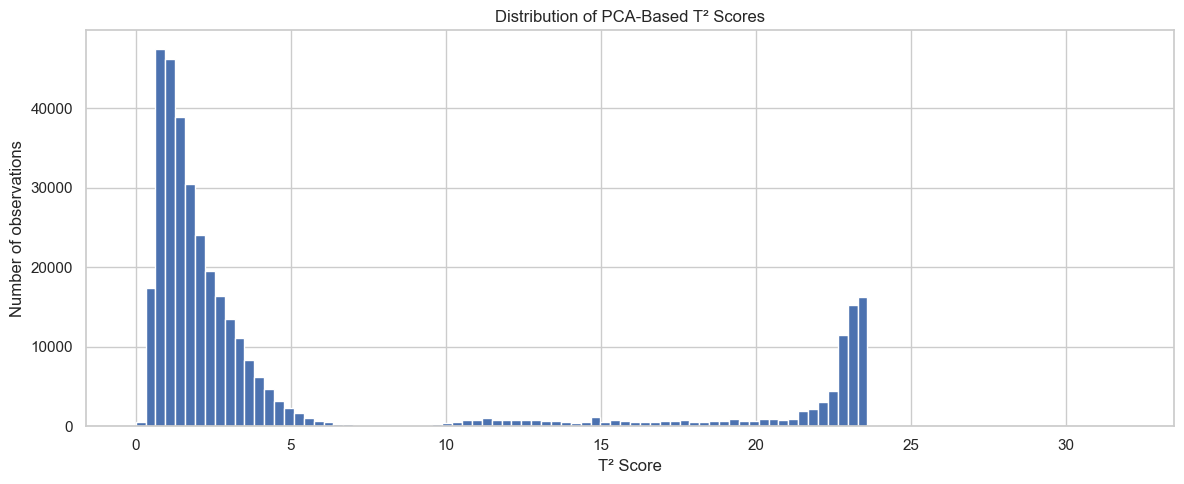

In [68]:
plt.figure(figsize=(12, 5))

plt.hist(
    t2_score,
    bins=100
)

plt.xlabel("T² Score")
plt.ylabel("Number of observations")

plt.title(
    "Distribution of PCA-Based T² Scores"
)

plt.tight_layout()
plt.show()

In [69]:
t2_score.quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

0.900    22.815802
0.950    23.166192
0.990    23.444211
0.995    23.476568
0.999    23.578001
Name: T2_score, dtype: float64

#### Does the process contain unusual behavior that PCA cannot explain?

T² measures how unusual an observation is within the main PCA space.

However, an observation can also be abnormal because it does not fit the relationships captured by the PCA model.

We therefore calculate the reconstruction error, known as the Squared Prediction Error (SPE) or Q statistic.

A high SPE indicates that the observation contains behavior that is poorly explained by the PCA model.

In [70]:
# Reconstruct the sensor data using the first 2 principal components

X_pc2 = X_pca[:, :2]

X_reconstructed = (
    X_pc2 @ pca.components_[:2]
)

print("Original shape:", X_scaled.shape)
print("Reconstructed shape:", X_reconstructed.shape)

Original shape: (376124, 6)
Reconstructed shape: (376124, 6)


In [71]:
# Calculate reconstruction error (SPE / Q statistic)

residuals = X_scaled - X_reconstructed

spe_score = np.sum(
    residuals ** 2,
    axis=1
)

spe_score = pd.Series(
    spe_score,
    index=pca_data.index,
    name="SPE_score"
)

spe_score.describe()

count    376124.000000
mean          0.101626
std           0.367127
min           0.000040
25%           0.010408
50%           0.031829
75%           0.075715
max          31.192093
Name: SPE_score, dtype: float64

In [72]:
spe_score.quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
)

0.900    0.175607
0.950    0.317439
0.990    1.171764
0.995    3.802853
0.999    4.392790
Name: SPE_score, dtype: float64

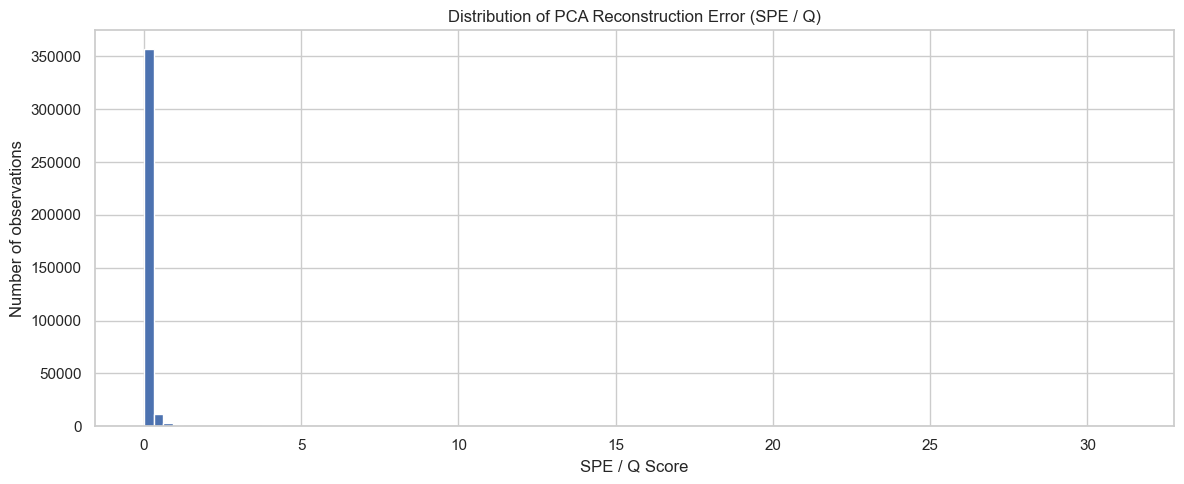

In [73]:
plt.figure(figsize=(12, 5))

plt.hist(
    spe_score,
    bins=100
)

plt.xlabel("SPE / Q Score")
plt.ylabel("Number of observations")

plt.title(
    "Distribution of PCA Reconstruction Error (SPE / Q)"
)

plt.tight_layout()
plt.show()

#### Which observations have unusually high PCA reconstruction error?

The SPE/Q score measures how poorly each observation is explained by the PCA model.

Most observations should have relatively small reconstruction errors.
We therefore use a high percentile of the SPE distribution as a practical threshold.

Observations above this threshold will be treated as candidate multivariate abnormalities.

In [74]:
# Define a high-percentile threshold for SPE

spe_threshold = spe_score.quantile(0.99)

print("SPE 99th percentile threshold:", spe_threshold)

# Flag candidate abnormalities
spe_anomaly = spe_score > spe_threshold

print("Number of SPE anomalies:", spe_anomaly.sum())
print("Percentage of observations:", spe_anomaly.mean() * 100)

SPE 99th percentile threshold: 1.1717642552701466
Number of SPE anomalies: 3762
Percentage of observations: 1.0002020610224287


#### Which observations are abnormal according to both PCA measures?

T2 and SPE capture different types of multivariate abnormality.

- T2 identifies observations that are unusual within the main PCA structure.
- SPE identifies observations that are poorly represented by the PCA structure.

We combine both signals to identify observations with stronger multivariate evidence of abnormal behavior.

In [75]:
# Define a high-percentile threshold for T2

t2_threshold = t2_score.quantile(0.99)

print("T² 99th percentile threshold:", t2_threshold)

# Flag T² anomalies
t2_anomaly = t2_score > t2_threshold

# Combine T2 and SPE
pca_anomaly = t2_anomaly & spe_anomaly

print("T² anomalies:", t2_anomaly.sum())
print("SPE anomalies:", spe_anomaly.sum())
print("Both T² and SPE:", pca_anomaly.sum())
print("Percentage:", pca_anomaly.mean() * 100)

T² 99th percentile threshold: 23.444210748836603
T² anomalies: 3762
SPE anomalies: 3762
Both T² and SPE: 0
Percentage: 0.0


#### How can we combine T2 and SPE into one PCA abnormality score?

T2 and SPE measure different aspects of multivariate abnormality.

Instead of requiring both to cross their thresholds simultaneously, we normalize each score by its 99th-percentile threshold.

A combined PCA score above 1 means that the observation is unusually high according to the PCA-based monitoring criteria.

This gives us a continuous multivariate abnormality score that we can later group into time-based events.

In [76]:
# Normalize T2 and SPE using their 99th-percentile thresholds

t2_normalized = t2_score / t2_threshold
spe_normalized = spe_score / spe_threshold

# Combined PCA abnormality score
pca_combined_score = np.maximum(
    t2_normalized,
    spe_normalized
)

# Flag observations exceeding the PCA threshold
pca_anomaly = pca_combined_score > 1

print("PCA candidate anomalies:", pca_anomaly.sum())
print("Percentage:", pca_anomaly.mean() * 100)

PCA candidate anomalies: 7524
Percentage: 2.0004041220448574


#### How do we correctly align PCA anomaly scores with the original timestamps?

PCA was calculated only on observations with complete sensor measurements.
We therefore need to attach the PCA results only to those valid observations
while keeping the original dataset and timestamps unchanged.

In [77]:
# Create the PCA analysis dataframe using only complete sensor observations

pca_valid_mask = df_eda[SENSOR_COLS].notna().all(axis=1)

df_pca = df_eda.loc[
    pca_valid_mask,
    ["timestamp"] + SENSOR_COLS
].copy()

# Attach PCA anomaly results to the valid observations only
df_pca["pca_anomaly"] = pca_anomaly

print("Original rows:", len(df_eda))
print("Rows used for PCA:", len(df_pca))
print("PCA anomaly rows:", df_pca["pca_anomaly"].sum())

Original rows: 377719
Rows used for PCA: 376124
PCA anomaly rows: 7524


In [78]:
# Keep only PCA candidate anomalies
pca_events = df_pca[df_pca["pca_anomaly"]].copy()

# Calculate time gap between consecutive anomaly observations
pca_events["time_diff"] = pca_events["timestamp"].diff()

# Start a new event when the gap is greater than 30 minutes
pca_events["new_event"] = (
    pca_events["time_diff"] > pd.Timedelta(minutes=30)
)

# Assign an event number
pca_events["event_group"] = (
    pca_events["new_event"].cumsum()
)

print(
    "Number of PCA candidate events:",
    pca_events["event_group"].nunique()
)

Number of PCA candidate events: 703


#### How strong is each PCA anomaly?

The PCA combined score measures how strongly an observation deviates
from the normal multivariate process structure.

We attach this score to each PCA candidate observation so that we can
summarize the intensity of each abnormal event.

In [79]:
# Attach the PCA score to the PCA dataframe

df_pca["pca_combined_score"] = pca_combined_score

# Keep only PCA candidate anomalies
pca_events = df_pca[df_pca["pca_anomaly"]].copy()

# Calculate the time gap between consecutive anomaly observations
pca_events["time_diff"] = pca_events["timestamp"].diff()

# Start a new event if the gap is more than 30 minutes
pca_events["new_event"] = (
    pca_events["time_diff"] > pd.Timedelta(minutes=30)
)

# Assign event numbers
pca_events["event_group"] = (
    pca_events["new_event"].cumsum()
)

print("PCA candidate events:", pca_events["event_group"].nunique())

PCA candidate events: 703


In [80]:
# Summarize each PCA candidate event

event_summary = (
    pca_events
    .groupby("event_group")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        observations=("timestamp", "count"),
        duration_minutes=(
            "timestamp",
            lambda x: (x.max() - x.min()).total_seconds() / 60
        ),
        max_pca_score=("pca_combined_score", "max"),
        mean_pca_score=("pca_combined_score", "mean")
    )
    .reset_index()
)

# Strongest events first
event_summary = event_summary.sort_values(
    "max_pca_score",
    ascending=False
).reset_index(drop=True)

event_summary.head(20)

,event_group,start_time,end_time,observations,duration_minutes,max_pca_score,mean_pca_score
0,301,2018-09-15 08:35:00,2018-09-15 08:45:00,3,10.0,26.619768,10.062594
1,277,2018-07-13 22:30:00,2018-07-14 00:05:00,20,95.0,6.559070,4.219958
2,183,2017-11-06 10:35:00,2017-11-06 12:45:00,19,130.0,5.911651,3.916682
3,66,2017-09-11 22:50:00,2017-09-12 07:20:00,100,510.0,5.866000,3.226588
4,224,2018-04-13 05:45:00,2018-04-13 05:45:00,1,0.0,5.852691,5.852691
5,495,2019-09-08 17:20:00,2019-09-08 17:20:00,1,0.0,5.702287,5.702287
6,225,2018-04-13 07:50:00,2018-04-13 11:15:00,39,205.0,5.682739,5.009161
7,182,2017-11-02 15:55:00,2017-11-02 17:25:00,13,90.0,5.632790,3.897281
8,272,2018-07-03 20:35:00,2018-07-03 21:00:00,6,25.0,5.625406,4.290372
9,53,2017-08-02 02:00:00,2017-08-02 08:40:00,78,400.0,5.555012,3.564672


#### Which sensors contribute most to each PCA candidate event?

The PCA model identifies unusual multivariate process states, but it does not automatically tell us which sensors are responsible.

We will compare each observation with its PCA reconstruction and calculate the reconstruction error for each sensor.

This allows us to identify which process variables contribute most strongly to an abnormal event.

In [81]:
# Calculate sensor-level reconstruction errors

sensor_reconstruction_error = (
    X_scaled - X_reconstructed
) ** 2

sensor_reconstruction_error = pd.DataFrame(
    sensor_reconstruction_error,
    index=pca_data.index,
    columns=SENSOR_COLS
)

sensor_reconstruction_error.head()

,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
0,0.000003,9.595387e-05,0.000295,0.009149,1.378817e-04,0.005474
1,0.000031,6.062687e-07,0.002983,0.004321,6.738909e-05,0.000078
2,0.000055,7.018057e-05,0.000009,0.000499,5.318064e-07,0.000367
3,0.000068,4.794700e-05,0.001018,0.003290,7.231681e-07,0.000517
4,0.000028,1.792425e-07,0.001289,0.002329,3.815655e-05,0.000115


#### What drove the strongest PCA candidate event?

We will examine the sensor-level reconstruction errors for the highest-scoring PCA event.

This helps us determine whether the event was driven by temperature variables, draft variables, or a coordinated combination of sensors.

In [82]:
# Get the strongest PCA event

top_event_group = event_summary.iloc[0]["event_group"]

top_event_rows = pca_events[
    pca_events["event_group"] == top_event_group
]

# Get the original row indices
top_indices = top_event_rows.index

# Sensor contribution during the event
top_event_contributions = (
    sensor_reconstruction_error.loc[top_indices]
    .mean()
    .sort_values(ascending=False)
)

top_event_contributions

Cyclone_cone_draft          7.930197
Cyclone_Outlet_Gas_draft    1.978202
Cyclone_Inlet_Draft         1.738262
Cyclone_Material_Temp       0.099466
Cyclone_Inlet_Gas_Temp      0.024175
Cyclone_Gas_Outlet_Temp     0.020686
dtype: float64

#### Validate the strongest PCA anomaly using the original sensor values

The PCA contribution analysis identifies which sensors drive the anomaly.
We now inspect the original sensor measurements around the event to verify
whether the detected abnormality is visible in the raw process behavior.

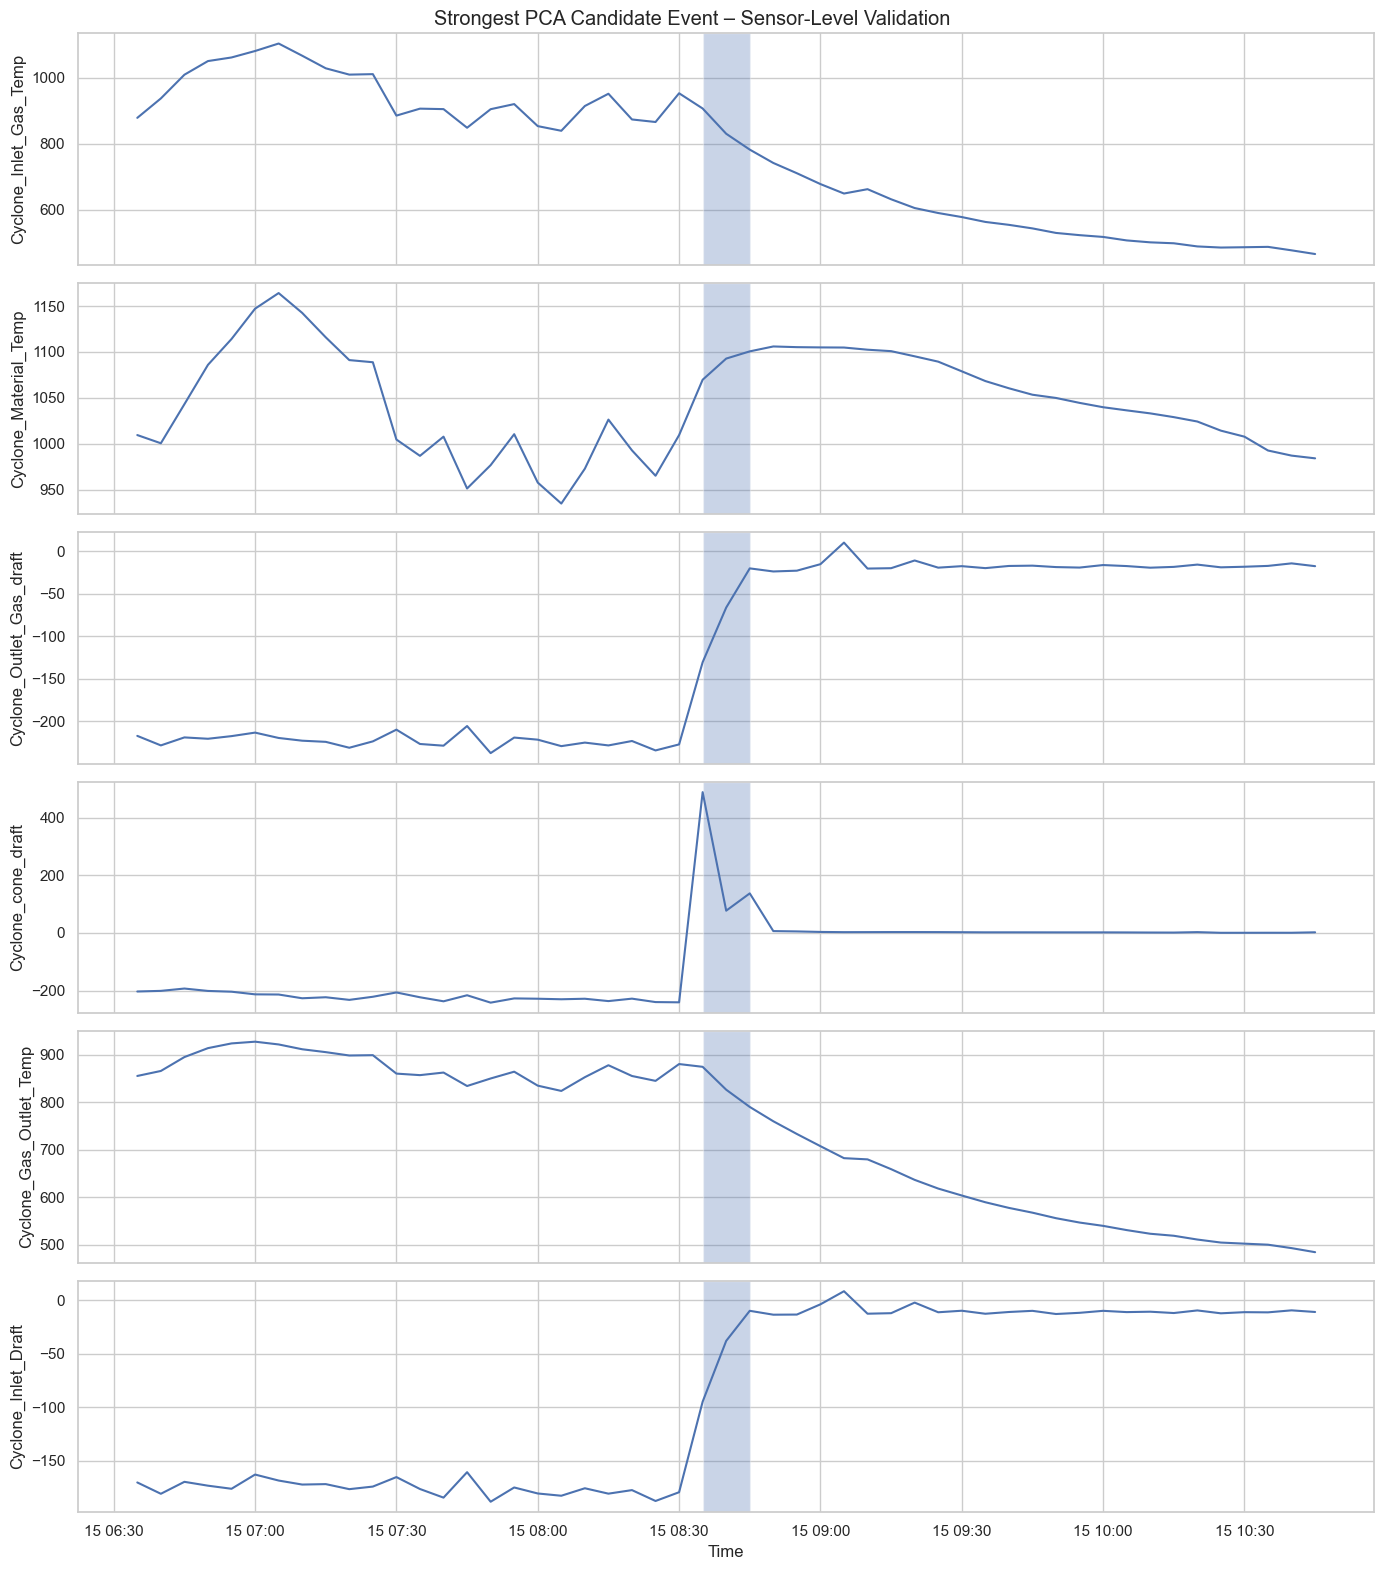

In [83]:
top_event_start = top_event_rows["timestamp"].min()
top_event_end = top_event_rows["timestamp"].max()

# Show 2 hours before and after the event
window_start = top_event_start - pd.Timedelta(hours=2)
window_end = top_event_end + pd.Timedelta(hours=2)

event_window = df_eda[
    (df_eda["timestamp"] >= window_start) &
    (df_eda["timestamp"] <= window_end)
].copy()

fig, axes = plt.subplots(6, 1, figsize=(14, 16), sharex=True)

for ax, col in zip(axes, SENSOR_COLS):
    ax.plot(event_window["timestamp"], event_window[col])
    ax.axvspan(top_event_start, top_event_end, alpha=0.3)
    ax.set_ylabel(col)
    ax.grid(True)

axes[-1].set_xlabel("Time")
plt.suptitle("Strongest PCA Candidate Event – Sensor-Level Validation")
plt.tight_layout()
plt.show()

#### Sensor-Level Contribution to PCA Anomalies

PCA identifies unusual multivariate process states, but it does not directly
show which sensors are responsible.

We calculate the squared reconstruction error for each sensor to identify
the variables contributing most to each abnormal event.

In [84]:
# Sensor-level squared reconstruction error
sensor_reconstruction_error = (
    X_scaled - X_reconstructed
) ** 2

sensor_reconstruction_error = pd.DataFrame(
    sensor_reconstruction_error,
    index=pca_data.index,
    columns=SENSOR_COLS
)

sensor_reconstruction_error.head()

,Cyclone_Inlet_Gas_Temp,Cyclone_Material_Temp,Cyclone_Outlet_Gas_draft,Cyclone_cone_draft,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Draft
0,0.000003,9.595387e-05,0.000295,0.009149,1.378817e-04,0.005474
1,0.000031,6.062687e-07,0.002983,0.004321,6.738909e-05,0.000078
2,0.000055,7.018057e-05,0.000009,0.000499,5.318064e-07,0.000367
3,0.000068,4.794700e-05,0.001018,0.003290,7.231681e-07,0.000517
4,0.000028,1.792425e-07,0.001289,0.002329,3.815655e-05,0.000115


#### Identify Dominant Sensors for Each PCA Event

For each detected PCA event, calculate the average reconstruction error
of every sensor and identify the sensors contributing most strongly.

In [85]:
event_contributions = []

for event_id in event_summary["event_group"]:
    
    event_rows = pca_events[
        pca_events["event_group"] == event_id
    ]
    
    indices = event_rows.index
    
    contribution = (
        sensor_reconstruction_error.loc[indices]
        .mean()
        .sort_values(ascending=False)
    )
    
    event_contributions.append({
        "event_group": event_id,
        "top_sensor_1": contribution.index[0],
        "top_sensor_1_error": contribution.iloc[0],
        "top_sensor_2": contribution.index[1],
        "top_sensor_2_error": contribution.iloc[1],
        "top_sensor_3": contribution.index[2],
        "top_sensor_3_error": contribution.iloc[2]
    })

event_contributions = pd.DataFrame(event_contributions)

event_contributions.head()

,event_group,top_sensor_1,top_sensor_1_error,top_sensor_2,top_sensor_2_error,top_sensor_3,top_sensor_3_error
0,301,Cyclone_cone_draft,7.930197,Cyclone_Outlet_Gas_draft,1.978202,Cyclone_Inlet_Draft,1.738262
1,277,Cyclone_Material_Temp,3.145448,Cyclone_Inlet_Gas_Temp,0.893992,Cyclone_Gas_Outlet_Temp,0.882250
2,183,Cyclone_Material_Temp,2.906293,Cyclone_Gas_Outlet_Temp,0.816950,Cyclone_Inlet_Gas_Temp,0.815439
3,66,Cyclone_Material_Temp,2.396474,Cyclone_Gas_Outlet_Temp,0.681722,Cyclone_Inlet_Gas_Temp,0.660322
4,224,Cyclone_Material_Temp,4.372091,Cyclone_Gas_Outlet_Temp,1.256200,Cyclone_Inlet_Gas_Temp,1.190747


#### Final PCA Candidate Events

Combine the event timing, duration, PCA severity and dominant sensor
contributions into a single table for interpretation.

In [86]:
final_event_table = event_summary.merge(
    event_contributions,
    on="event_group",
    how="left"
)

final_event_table = final_event_table.sort_values(
    "max_pca_score",
    ascending=False
).reset_index(drop=True)

final_event_table.head(10)

,event_group,start_time,end_time,observations,duration_minutes,max_pca_score,mean_pca_score,top_sensor_1,top_sensor_1_error,top_sensor_2,top_sensor_2_error,top_sensor_3,top_sensor_3_error
0,301,2018-09-15 08:35:00,2018-09-15 08:45:00,3,10.0,26.619768,10.062594,Cyclone_cone_draft,7.930197,Cyclone_Outlet_Gas_draft,1.978202,Cyclone_Inlet_Draft,1.738262
1,277,2018-07-13 22:30:00,2018-07-14 00:05:00,20,95.0,6.559070,4.219958,Cyclone_Material_Temp,3.145448,Cyclone_Inlet_Gas_Temp,0.893992,Cyclone_Gas_Outlet_Temp,0.882250
2,183,2017-11-06 10:35:00,2017-11-06 12:45:00,19,130.0,5.911651,3.916682,Cyclone_Material_Temp,2.906293,Cyclone_Gas_Outlet_Temp,0.816950,Cyclone_Inlet_Gas_Temp,0.815439
3,66,2017-09-11 22:50:00,2017-09-12 07:20:00,100,510.0,5.866000,3.226588,Cyclone_Material_Temp,2.396474,Cyclone_Gas_Outlet_Temp,0.681722,Cyclone_Inlet_Gas_Temp,0.660322
4,224,2018-04-13 05:45:00,2018-04-13 05:45:00,1,0.0,5.852691,5.852691,Cyclone_Material_Temp,4.372091,Cyclone_Gas_Outlet_Temp,1.256200,Cyclone_Inlet_Gas_Temp,1.190747
5,495,2019-09-08 17:20:00,2019-09-08 17:20:00,1,0.0,5.702287,5.702287,Cyclone_Material_Temp,4.246824,Cyclone_Gas_Outlet_Temp,1.253331,Cyclone_Inlet_Gas_Temp,1.141255
6,225,2018-04-13 07:50:00,2018-04-13 11:15:00,39,205.0,5.682739,5.009161,Cyclone_Material_Temp,3.736288,Cyclone_Gas_Outlet_Temp,1.047603,Cyclone_Inlet_Gas_Temp,1.043544
7,182,2017-11-02 15:55:00,2017-11-02 17:25:00,13,90.0,5.632790,3.897281,Cyclone_Material_Temp,2.854868,Cyclone_Gas_Outlet_Temp,0.871945,Cyclone_Inlet_Gas_Temp,0.747758
8,272,2018-07-03 20:35:00,2018-07-03 21:00:00,6,25.0,5.625406,4.290372,Cyclone_Material_Temp,3.180308,Cyclone_Gas_Outlet_Temp,0.990474,Cyclone_Inlet_Gas_Temp,0.789904
9,53,2017-08-02 02:00:00,2017-08-02 08:40:00,78,400.0,5.555012,3.564672,Cyclone_Material_Temp,2.631506,Cyclone_Gas_Outlet_Temp,0.771543,Cyclone_Inlet_Gas_Temp,0.695550


In [87]:
final_event_table = final_event_table[
    [
        "event_group",
        "start_time",
        "end_time",
        "duration_minutes",
        "observations",
        "max_pca_score",
        "mean_pca_score",
        "top_sensor_1",
        "top_sensor_1_error",
        "top_sensor_2",
        "top_sensor_2_error",
        "top_sensor_3",
        "top_sensor_3_error"
    ]
]

final_event_table.head(10)

,event_group,start_time,end_time,duration_minutes,observations,max_pca_score,mean_pca_score,top_sensor_1,top_sensor_1_error,top_sensor_2,top_sensor_2_error,top_sensor_3,top_sensor_3_error
0,301,2018-09-15 08:35:00,2018-09-15 08:45:00,10.0,3,26.619768,10.062594,Cyclone_cone_draft,7.930197,Cyclone_Outlet_Gas_draft,1.978202,Cyclone_Inlet_Draft,1.738262
1,277,2018-07-13 22:30:00,2018-07-14 00:05:00,95.0,20,6.559070,4.219958,Cyclone_Material_Temp,3.145448,Cyclone_Inlet_Gas_Temp,0.893992,Cyclone_Gas_Outlet_Temp,0.882250
2,183,2017-11-06 10:35:00,2017-11-06 12:45:00,130.0,19,5.911651,3.916682,Cyclone_Material_Temp,2.906293,Cyclone_Gas_Outlet_Temp,0.816950,Cyclone_Inlet_Gas_Temp,0.815439
3,66,2017-09-11 22:50:00,2017-09-12 07:20:00,510.0,100,5.866000,3.226588,Cyclone_Material_Temp,2.396474,Cyclone_Gas_Outlet_Temp,0.681722,Cyclone_Inlet_Gas_Temp,0.660322
4,224,2018-04-13 05:45:00,2018-04-13 05:45:00,0.0,1,5.852691,5.852691,Cyclone_Material_Temp,4.372091,Cyclone_Gas_Outlet_Temp,1.256200,Cyclone_Inlet_Gas_Temp,1.190747
5,495,2019-09-08 17:20:00,2019-09-08 17:20:00,0.0,1,5.702287,5.702287,Cyclone_Material_Temp,4.246824,Cyclone_Gas_Outlet_Temp,1.253331,Cyclone_Inlet_Gas_Temp,1.141255
6,225,2018-04-13 07:50:00,2018-04-13 11:15:00,205.0,39,5.682739,5.009161,Cyclone_Material_Temp,3.736288,Cyclone_Gas_Outlet_Temp,1.047603,Cyclone_Inlet_Gas_Temp,1.043544
7,182,2017-11-02 15:55:00,2017-11-02 17:25:00,90.0,13,5.632790,3.897281,Cyclone_Material_Temp,2.854868,Cyclone_Gas_Outlet_Temp,0.871945,Cyclone_Inlet_Gas_Temp,0.747758
8,272,2018-07-03 20:35:00,2018-07-03 21:00:00,25.0,6,5.625406,4.290372,Cyclone_Material_Temp,3.180308,Cyclone_Gas_Outlet_Temp,0.990474,Cyclone_Inlet_Gas_Temp,0.789904
9,53,2017-08-02 02:00:00,2017-08-02 08:40:00,400.0,78,5.555012,3.564672,Cyclone_Material_Temp,2.631506,Cyclone_Gas_Outlet_Temp,0.771543,Cyclone_Inlet_Gas_Temp,0.695550


#### Top 10 PCA-Detected Abnormal Periods

The following periods have the strongest PCA anomaly scores and are
selected for further process-level validation.

In [88]:
top_10_events = final_event_table.head(10).copy()

top_10_events

,event_group,start_time,end_time,duration_minutes,observations,max_pca_score,mean_pca_score,top_sensor_1,top_sensor_1_error,top_sensor_2,top_sensor_2_error,top_sensor_3,top_sensor_3_error
0,301,2018-09-15 08:35:00,2018-09-15 08:45:00,10.0,3,26.619768,10.062594,Cyclone_cone_draft,7.930197,Cyclone_Outlet_Gas_draft,1.978202,Cyclone_Inlet_Draft,1.738262
1,277,2018-07-13 22:30:00,2018-07-14 00:05:00,95.0,20,6.559070,4.219958,Cyclone_Material_Temp,3.145448,Cyclone_Inlet_Gas_Temp,0.893992,Cyclone_Gas_Outlet_Temp,0.882250
2,183,2017-11-06 10:35:00,2017-11-06 12:45:00,130.0,19,5.911651,3.916682,Cyclone_Material_Temp,2.906293,Cyclone_Gas_Outlet_Temp,0.816950,Cyclone_Inlet_Gas_Temp,0.815439
3,66,2017-09-11 22:50:00,2017-09-12 07:20:00,510.0,100,5.866000,3.226588,Cyclone_Material_Temp,2.396474,Cyclone_Gas_Outlet_Temp,0.681722,Cyclone_Inlet_Gas_Temp,0.660322
4,224,2018-04-13 05:45:00,2018-04-13 05:45:00,0.0,1,5.852691,5.852691,Cyclone_Material_Temp,4.372091,Cyclone_Gas_Outlet_Temp,1.256200,Cyclone_Inlet_Gas_Temp,1.190747
5,495,2019-09-08 17:20:00,2019-09-08 17:20:00,0.0,1,5.702287,5.702287,Cyclone_Material_Temp,4.246824,Cyclone_Gas_Outlet_Temp,1.253331,Cyclone_Inlet_Gas_Temp,1.141255
6,225,2018-04-13 07:50:00,2018-04-13 11:15:00,205.0,39,5.682739,5.009161,Cyclone_Material_Temp,3.736288,Cyclone_Gas_Outlet_Temp,1.047603,Cyclone_Inlet_Gas_Temp,1.043544
7,182,2017-11-02 15:55:00,2017-11-02 17:25:00,90.0,13,5.632790,3.897281,Cyclone_Material_Temp,2.854868,Cyclone_Gas_Outlet_Temp,0.871945,Cyclone_Inlet_Gas_Temp,0.747758
8,272,2018-07-03 20:35:00,2018-07-03 21:00:00,25.0,6,5.625406,4.290372,Cyclone_Material_Temp,3.180308,Cyclone_Gas_Outlet_Temp,0.990474,Cyclone_Inlet_Gas_Temp,0.789904
9,53,2017-08-02 02:00:00,2017-08-02 08:40:00,400.0,78,5.555012,3.564672,Cyclone_Material_Temp,2.631506,Cyclone_Gas_Outlet_Temp,0.771543,Cyclone_Inlet_Gas_Temp,0.695550


In [89]:
report_table = top_10_events.copy()

report_table["duration_minutes"] = (
    report_table["duration_minutes"].round(1)
)

report_table["max_pca_score"] = (
    report_table["max_pca_score"].round(2)
)

report_table["mean_pca_score"] = (
    report_table["mean_pca_score"].round(2)
)

report_table[
    [
        "start_time",
        "end_time",
        "duration_minutes",
        "max_pca_score",
        "top_sensor_1",
        "top_sensor_2",
        "top_sensor_3"
    ]
]

,start_time,end_time,duration_minutes,max_pca_score,top_sensor_1,top_sensor_2,top_sensor_3
0,2018-09-15 08:35:00,2018-09-15 08:45:00,10.0,26.62,Cyclone_cone_draft,Cyclone_Outlet_Gas_draft,Cyclone_Inlet_Draft
1,2018-07-13 22:30:00,2018-07-14 00:05:00,95.0,6.56,Cyclone_Material_Temp,Cyclone_Inlet_Gas_Temp,Cyclone_Gas_Outlet_Temp
2,2017-11-06 10:35:00,2017-11-06 12:45:00,130.0,5.91,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
3,2017-09-11 22:50:00,2017-09-12 07:20:00,510.0,5.87,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
4,2018-04-13 05:45:00,2018-04-13 05:45:00,0.0,5.85,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
5,2019-09-08 17:20:00,2019-09-08 17:20:00,0.0,5.70,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
6,2018-04-13 07:50:00,2018-04-13 11:15:00,205.0,5.68,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
7,2017-11-02 15:55:00,2017-11-02 17:25:00,90.0,5.63,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
8,2018-07-03 20:35:00,2018-07-03 21:00:00,25.0,5.63,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
9,2017-08-02 02:00:00,2017-08-02 08:40:00,400.0,5.56,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp


#### Visual Validation of PCA Candidate Events

For each candidate event, inspect the original sensor measurements around
the detected period.

This helps distinguish statistically detected abnormalities from ordinary
changes in operating conditions.

In [90]:
def plot_pca_event(event_rank=0, hours_before=2, hours_after=2):
    
    event = final_event_table.iloc[event_rank]
    
    start_time = event["start_time"]
    end_time = event["end_time"]
    
    window_start = start_time - pd.Timedelta(hours=hours_before)
    window_end = end_time + pd.Timedelta(hours=hours_after)
    
    event_window = df_eda[
        (df_eda["timestamp"] >= window_start) &
        (df_eda["timestamp"] <= window_end)
    ].copy()
    
    fig, axes = plt.subplots(
        6, 1,
        figsize=(15, 16),
        sharex=True
    )
    
    for ax, col in zip(axes, SENSOR_COLS):
        
        ax.plot(
            event_window["timestamp"],
            event_window[col]
        )
        
        ax.axvspan(
            start_time,
            end_time,
            alpha=0.3
        )
        
        ax.set_ylabel(col)
        ax.grid(True)
    
    axes[-1].set_xlabel("Time")
    
    plt.suptitle(
        f"PCA Candidate Event #{event_rank + 1}\n"
        f"{start_time} to {end_time}",
        fontsize=14
    )
    
    plt.tight_layout()
    plt.show()

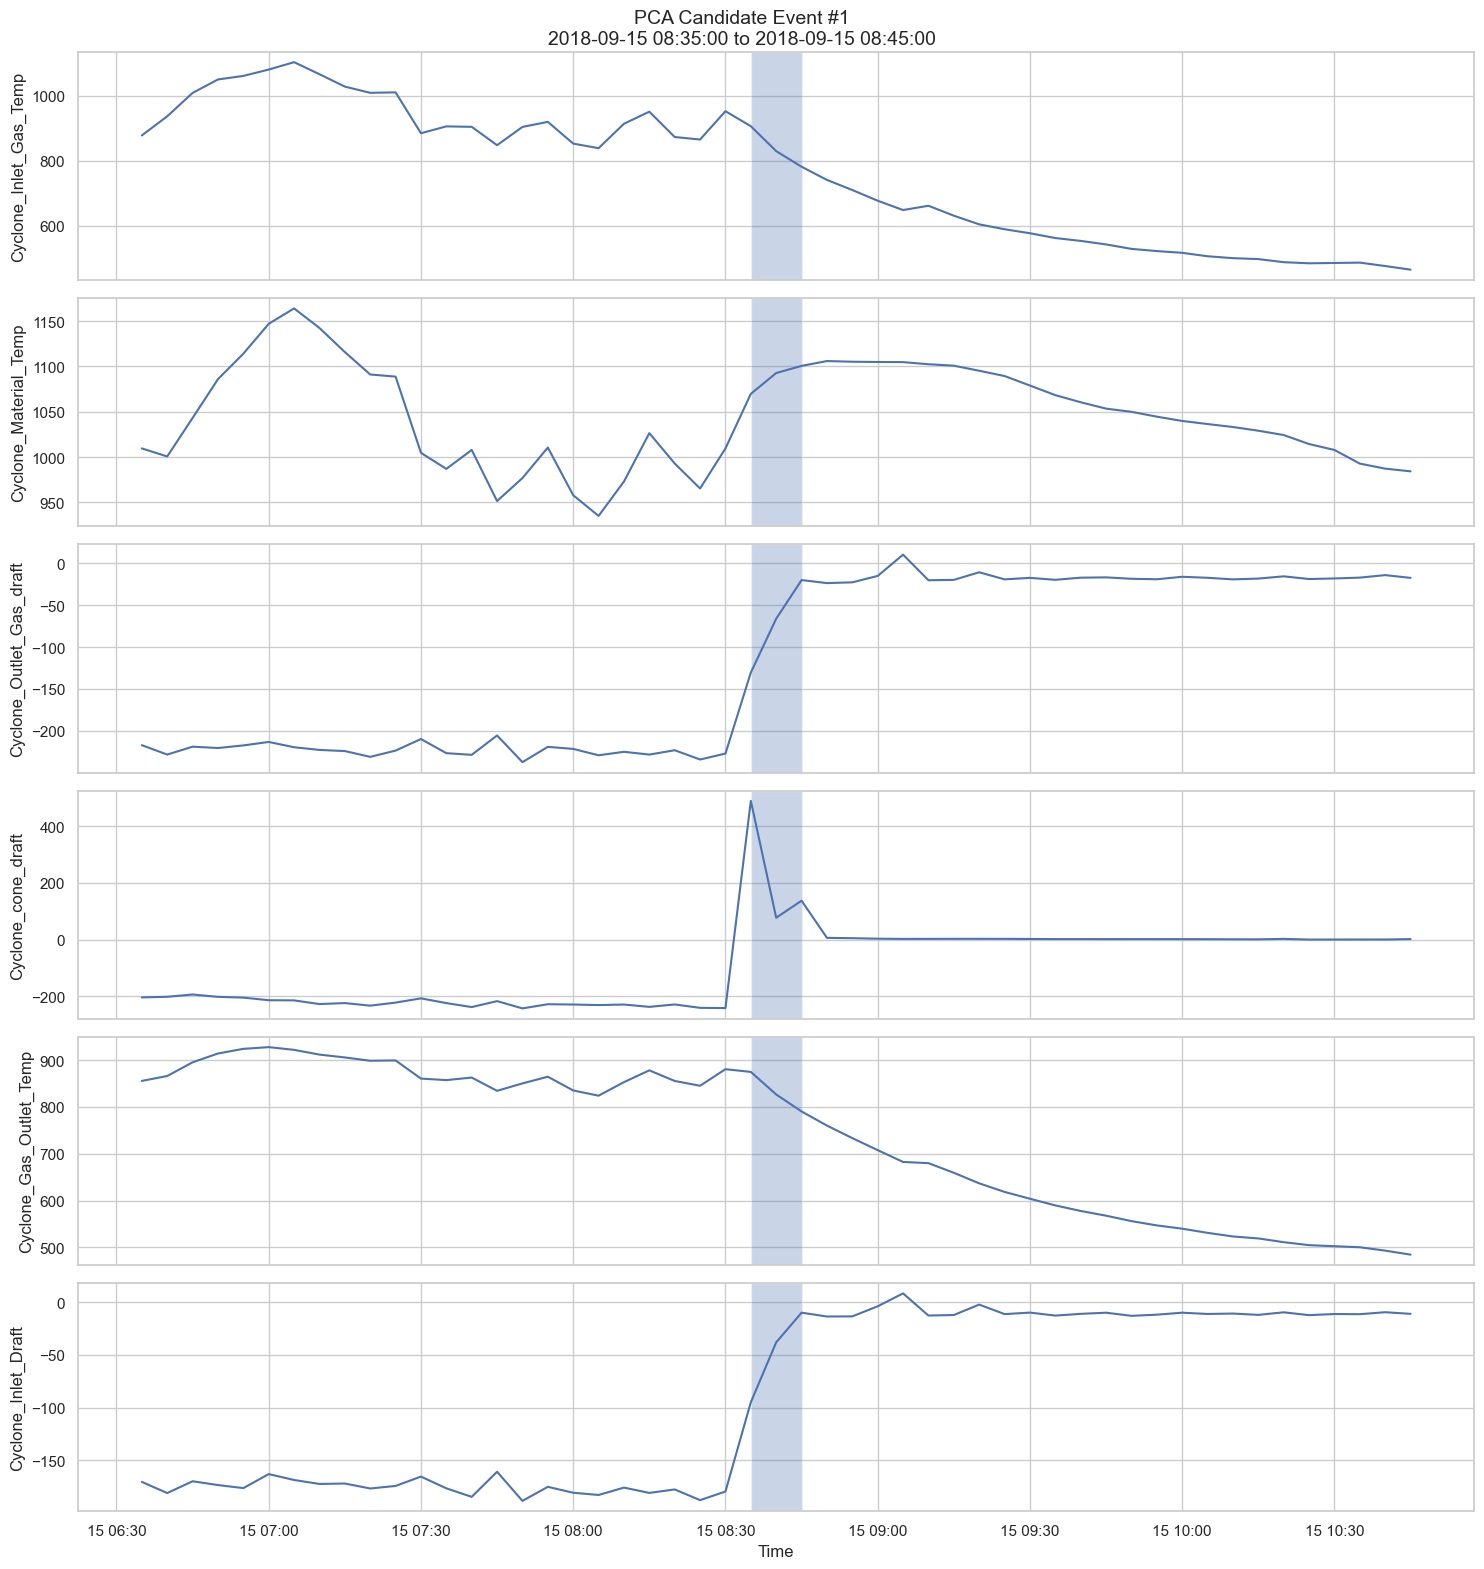

In [91]:
plot_pca_event(event_rank=0)

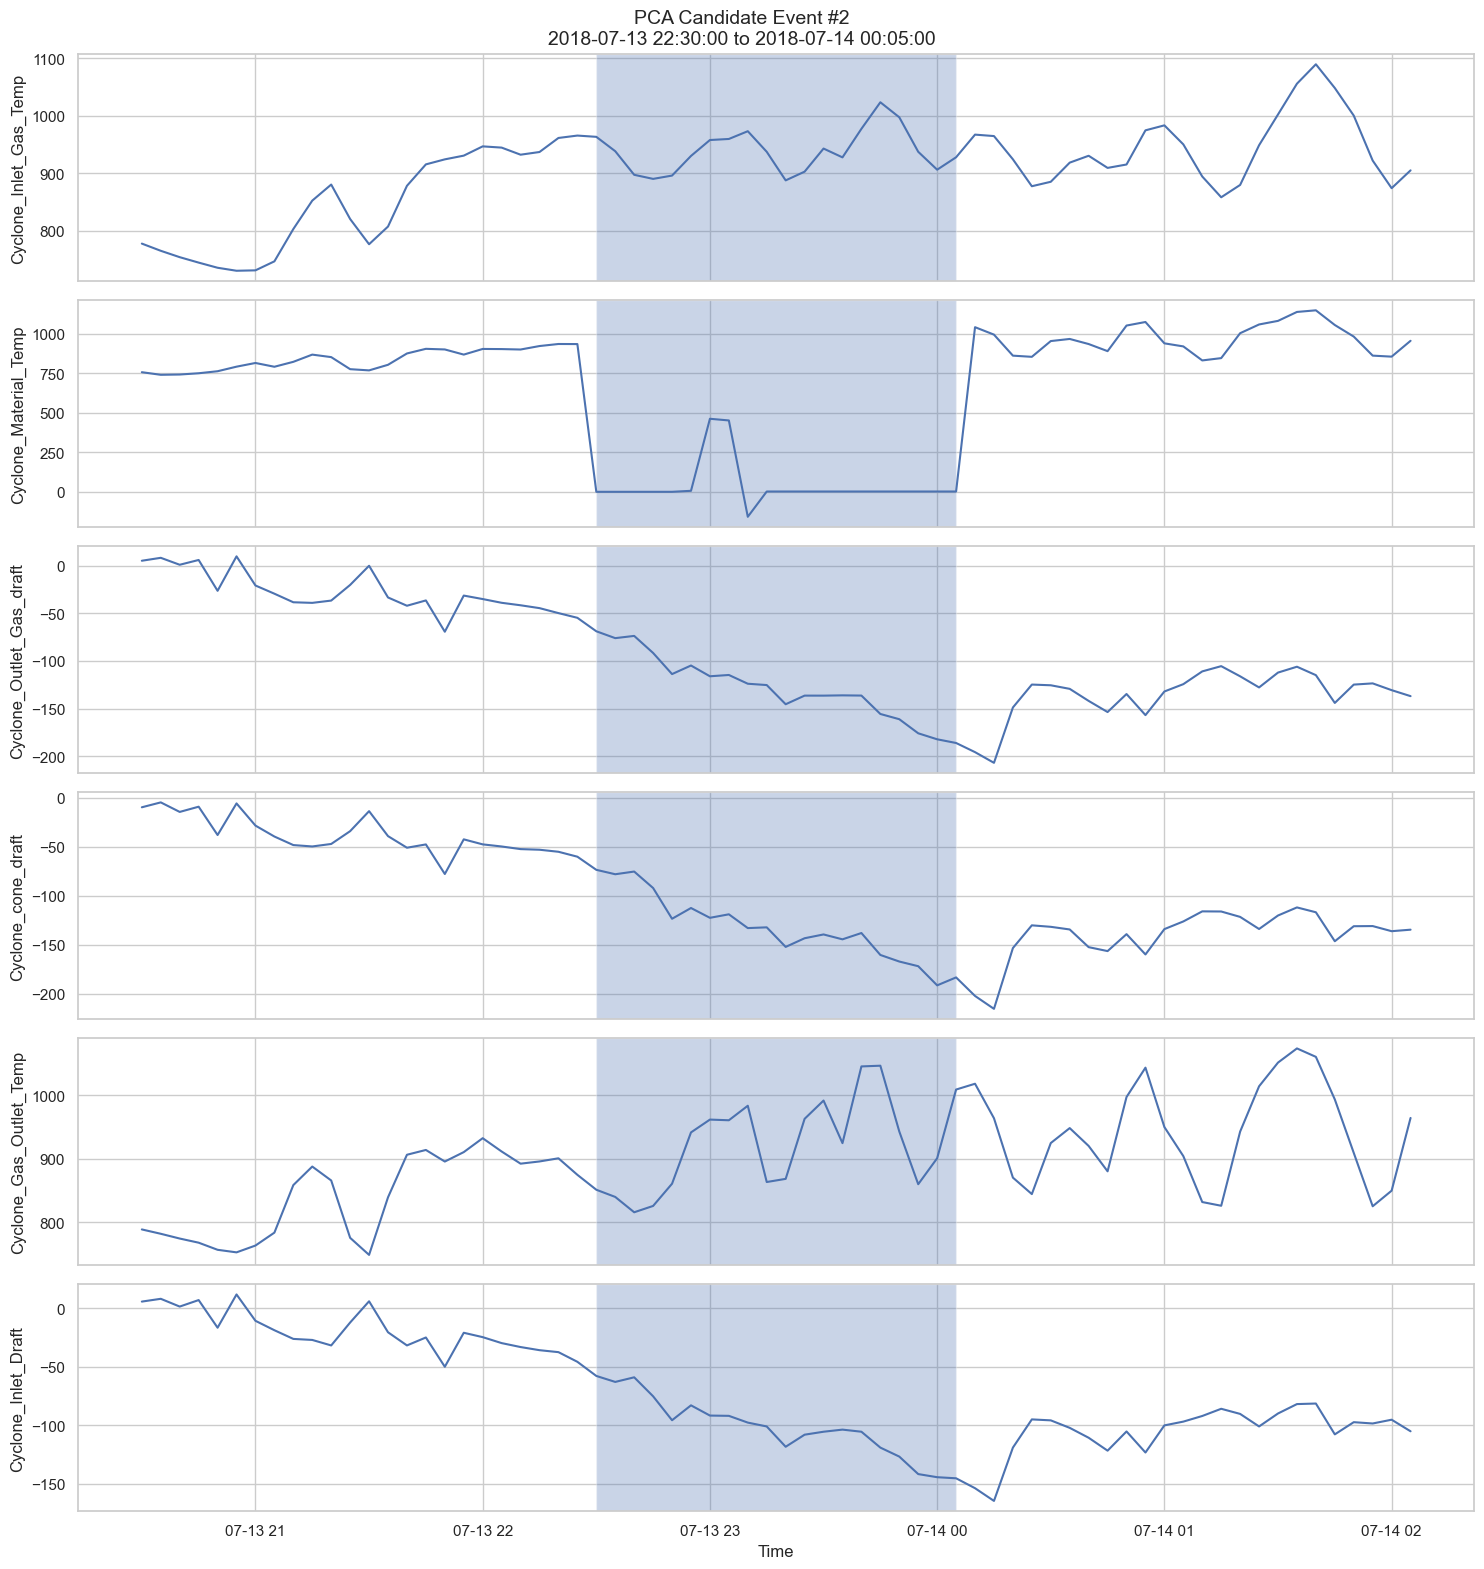

In [92]:
plot_pca_event(event_rank=1)


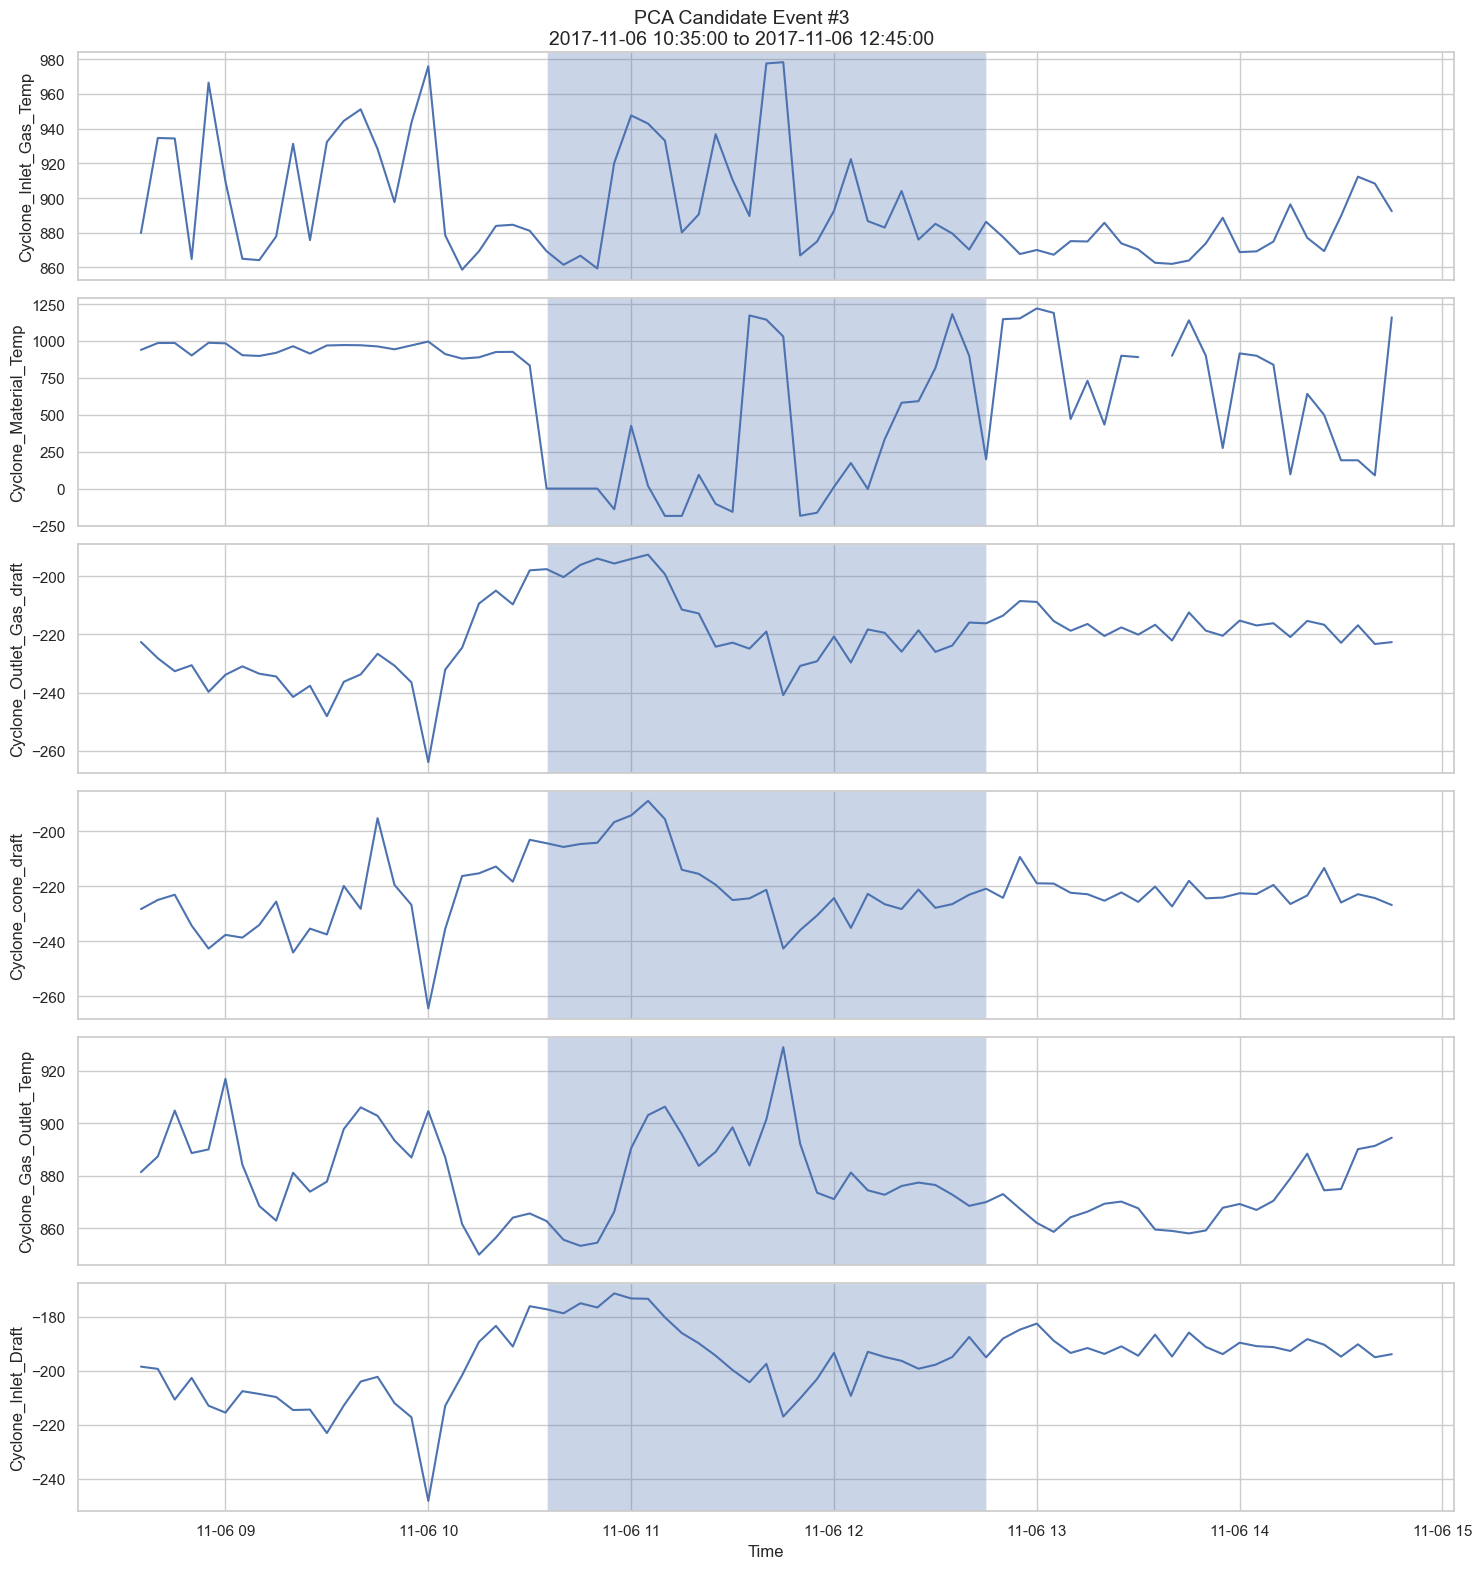

In [93]:
plot_pca_event(event_rank=2)


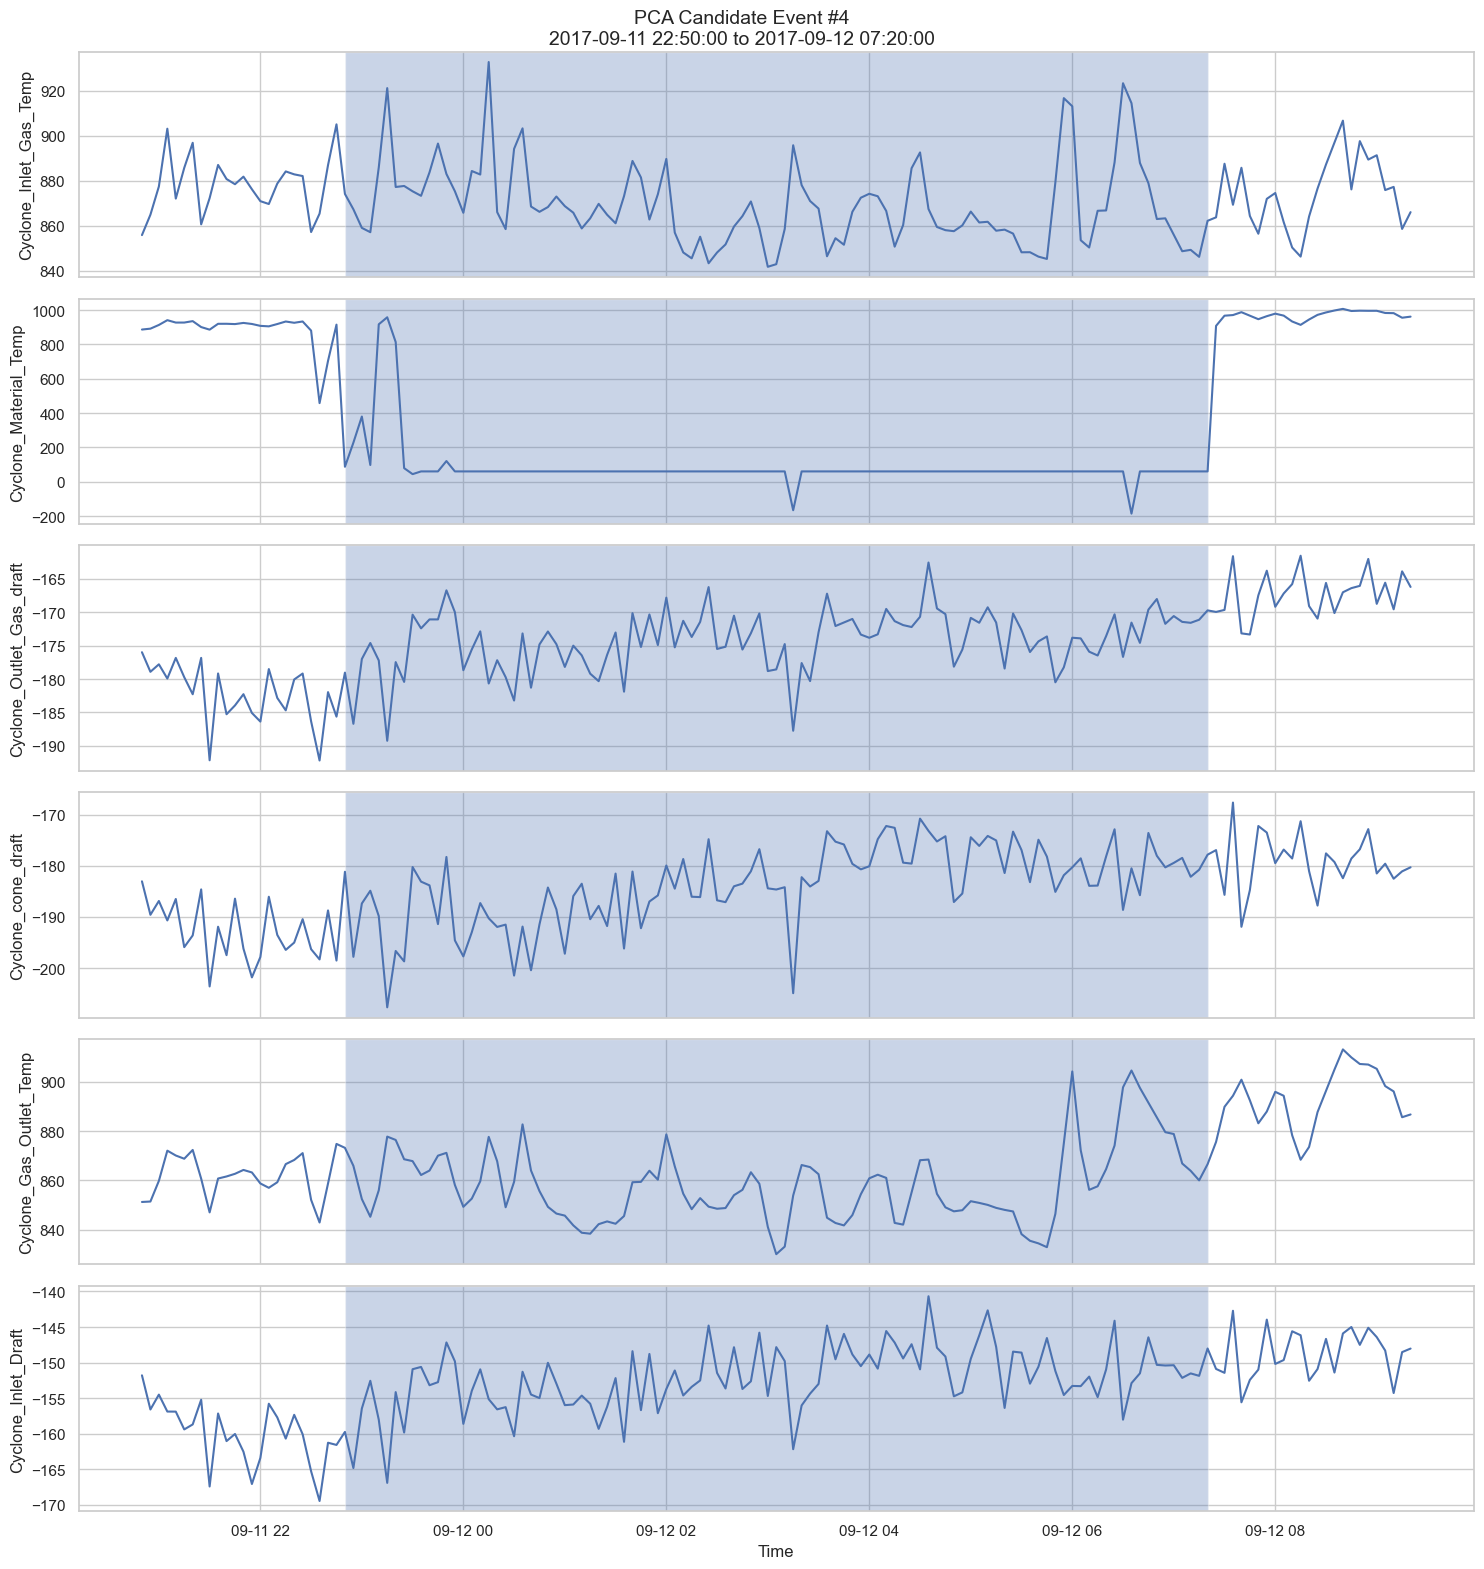

In [94]:
plot_pca_event(event_rank=3)


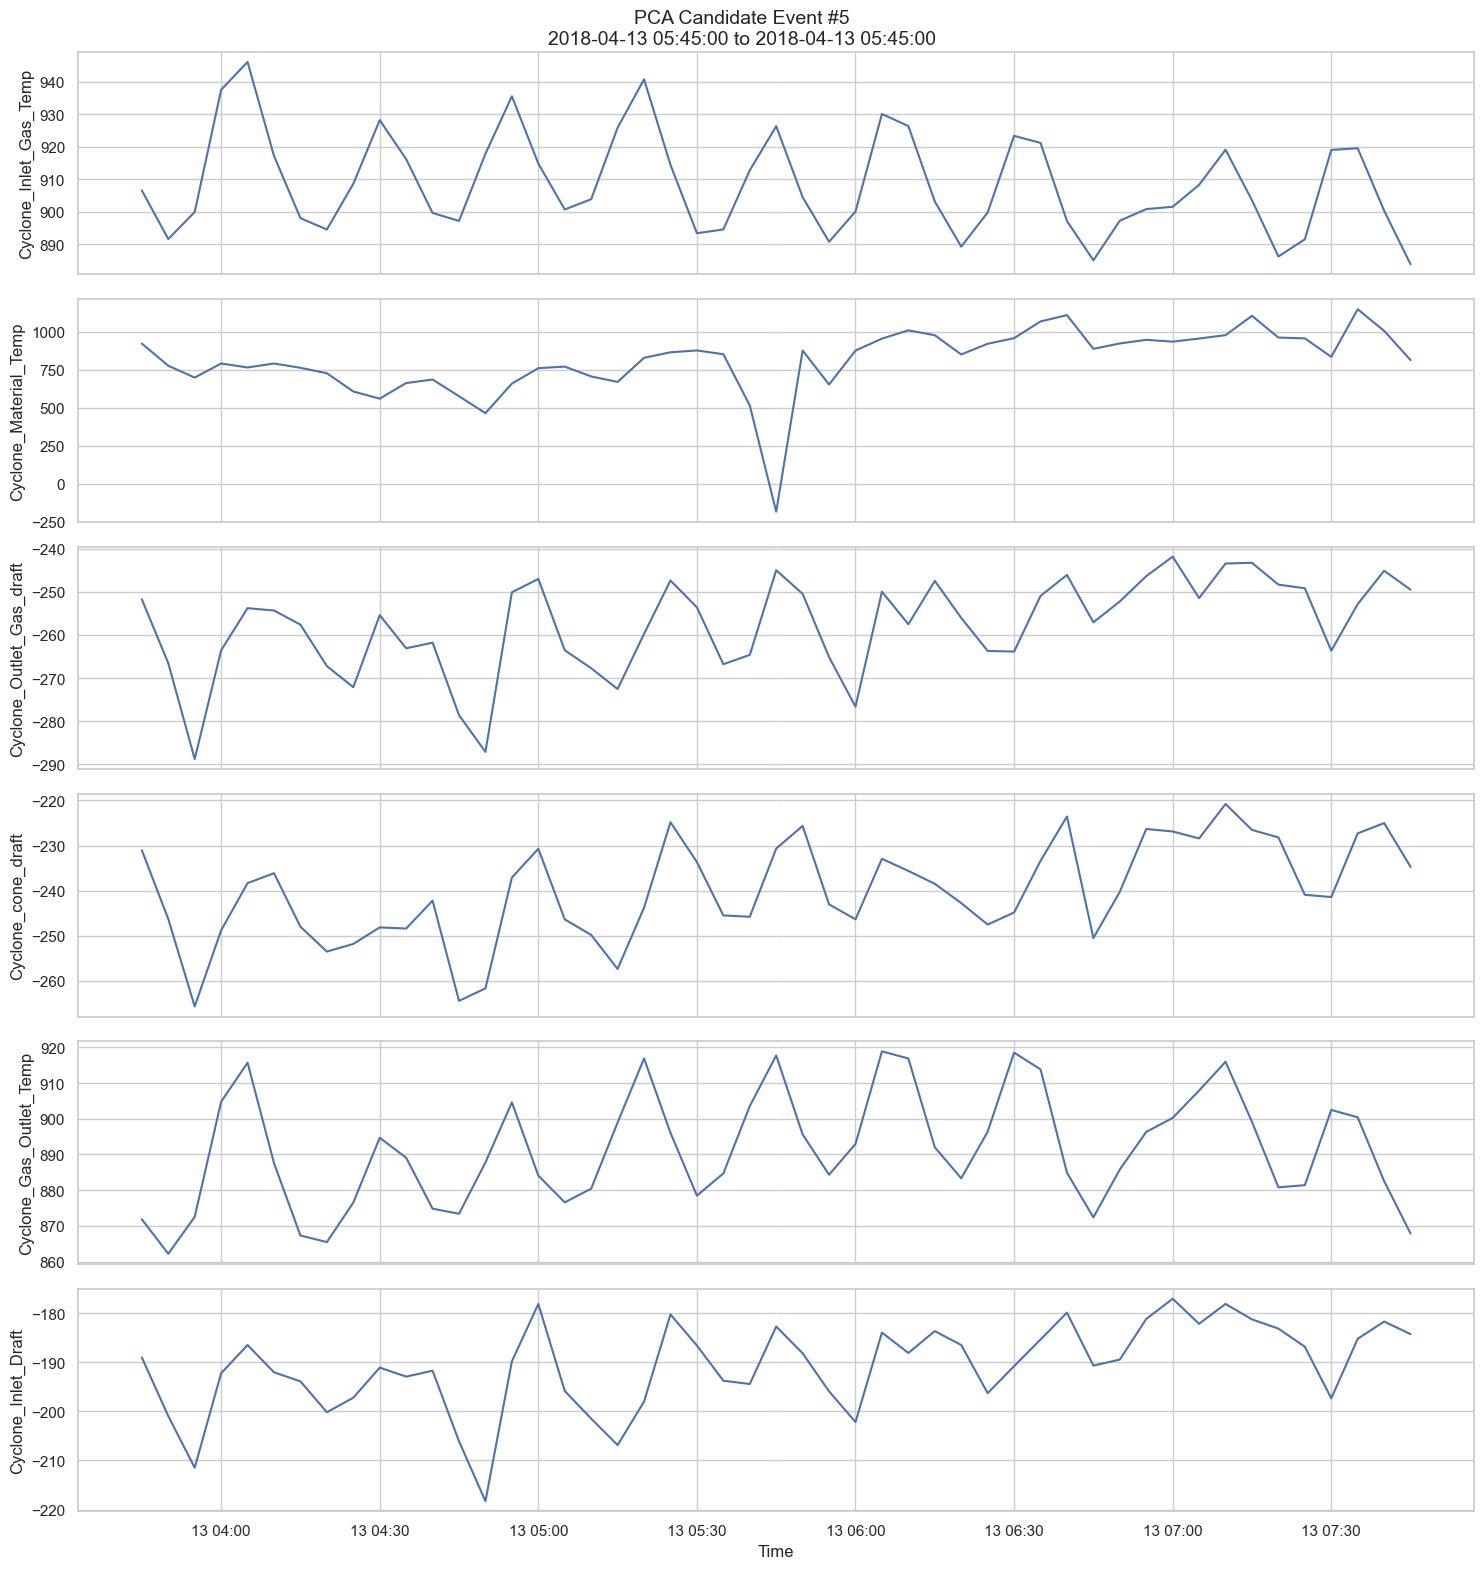

In [95]:
plot_pca_event(event_rank=4)

#### Persistence-Based Event Filtering

Very short isolated detections can represent transient fluctuations.

We therefore retain events with at least three observations or a duration
of at least 15 minutes for further investigation.

In [96]:
persistent_events = final_event_table[
    (final_event_table["observations"] >= 3) |
    (final_event_table["duration_minutes"] >= 15)
].copy()

persistent_events = persistent_events.sort_values(
    "max_pca_score",
    ascending=False
).reset_index(drop=True)

persistent_events.head(10)

,event_group,start_time,end_time,duration_minutes,observations,max_pca_score,mean_pca_score,top_sensor_1,top_sensor_1_error,top_sensor_2,top_sensor_2_error,top_sensor_3,top_sensor_3_error
0,301,2018-09-15 08:35:00,2018-09-15 08:45:00,10.0,3,26.619768,10.062594,Cyclone_cone_draft,7.930197,Cyclone_Outlet_Gas_draft,1.978202,Cyclone_Inlet_Draft,1.738262
1,277,2018-07-13 22:30:00,2018-07-14 00:05:00,95.0,20,6.559070,4.219958,Cyclone_Material_Temp,3.145448,Cyclone_Inlet_Gas_Temp,0.893992,Cyclone_Gas_Outlet_Temp,0.882250
2,183,2017-11-06 10:35:00,2017-11-06 12:45:00,130.0,19,5.911651,3.916682,Cyclone_Material_Temp,2.906293,Cyclone_Gas_Outlet_Temp,0.816950,Cyclone_Inlet_Gas_Temp,0.815439
3,66,2017-09-11 22:50:00,2017-09-12 07:20:00,510.0,100,5.866000,3.226588,Cyclone_Material_Temp,2.396474,Cyclone_Gas_Outlet_Temp,0.681722,Cyclone_Inlet_Gas_Temp,0.660322
4,225,2018-04-13 07:50:00,2018-04-13 11:15:00,205.0,39,5.682739,5.009161,Cyclone_Material_Temp,3.736288,Cyclone_Gas_Outlet_Temp,1.047603,Cyclone_Inlet_Gas_Temp,1.043544
5,182,2017-11-02 15:55:00,2017-11-02 17:25:00,90.0,13,5.632790,3.897281,Cyclone_Material_Temp,2.854868,Cyclone_Gas_Outlet_Temp,0.871945,Cyclone_Inlet_Gas_Temp,0.747758
6,272,2018-07-03 20:35:00,2018-07-03 21:00:00,25.0,6,5.625406,4.290372,Cyclone_Material_Temp,3.180308,Cyclone_Gas_Outlet_Temp,0.990474,Cyclone_Inlet_Gas_Temp,0.789904
7,53,2017-08-02 02:00:00,2017-08-02 08:40:00,400.0,78,5.555012,3.564672,Cyclone_Material_Temp,2.631506,Cyclone_Gas_Outlet_Temp,0.771543,Cyclone_Inlet_Gas_Temp,0.695550
8,51,2017-07-20 20:40:00,2017-07-20 23:30:00,170.0,27,5.497891,1.876958,Cyclone_Material_Temp,1.335167,Cyclone_Gas_Outlet_Temp,0.410602,Cyclone_Inlet_Gas_Temp,0.331618
9,396,2019-04-19 05:30:00,2019-04-19 07:15:00,105.0,19,5.070170,3.582574,Cyclone_Material_Temp,2.624681,Cyclone_Gas_Outlet_Temp,0.746017,Cyclone_Inlet_Gas_Temp,0.739431


#### Cross-Validation with Process Volatility

PCA detects unusual multivariate process states.

The rolling-volatility method detects periods where multiple sensors become
unstable.

Comparing the two approaches provides additional evidence for process-level
abnormality.

In [97]:
# Create volatility event timestamps
volatility_event_times = candidate_events[
    candidate_events["candidate"]
][["timestamp", "unstable_sensor_count"]].copy()

volatility_event_times["volatility_flag"] = True

# Add PCA flag
pca_flag_times = df_pca[
    ["timestamp", "pca_anomaly"]
].copy()

pca_flag_times = pca_flag_times[
    pca_flag_times["pca_anomaly"]
]

pca_flag_times["pca_flag"] = True

# Merge
validation_flags = pd.merge(
    volatility_event_times,
    pca_flag_times[["timestamp", "pca_flag"]],
    on="timestamp",
    how="outer"
)

validation_flags["volatility_flag"] = (
    validation_flags["volatility_flag"].fillna(False)
)

validation_flags["pca_flag"] = (
    validation_flags["pca_flag"].fillna(False)
)

validation_flags.head()

C:\Users\Sanji\AppData\Local\Temp\ipykernel_21656\3761985841.py:28: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validation_flags["volatility_flag"].fillna(False)
C:\Users\Sanji\AppData\Local\Temp\ipykernel_21656\3761985841.py:32: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  validation_flags["pca_flag"].fillna(False)


,timestamp,unstable_sensor_count,volatility_flag,pca_flag
0,2017-01-04 05:30:00,3.0,True,False
1,2017-01-04 05:35:00,3.0,True,False
2,2017-01-04 05:40:00,3.0,True,False
3,2017-01-04 05:45:00,3.0,True,False
4,2017-01-04 05:50:00,3.0,True,False


In [98]:
overlap_summary = pd.DataFrame({
    "Condition": [
        "PCA anomaly only",
        "Volatility anomaly only",
        "Both PCA and volatility",
        "Neither"
    ],
    "Count": [
        (
            validation_flags["pca_flag"] &
            ~validation_flags["volatility_flag"]
        ).sum(),
        
        (
            validation_flags["volatility_flag"] &
            ~validation_flags["pca_flag"]
        ).sum(),
        
        (
            validation_flags["pca_flag"] &
            validation_flags["volatility_flag"]
        ).sum(),
        
        (
            ~validation_flags["pca_flag"] &
            ~validation_flags["volatility_flag"]
        ).sum()
    ]
})

overlap_summary

,Condition,Count
0,PCA anomaly only,7345
1,Volatility anomaly only,10974
2,Both PCA and volatility,179
3,Neither,0


#### Final Abnormal Periods

The final candidate periods are based on:

1. Multivariate PCA anomaly score
2. Persistence of the detected condition
3. Sensor-level reconstruction contribution
4. Visual validation using the original time series
5. Supporting evidence from process volatility

These periods are treated as candidate abnormal process periods rather than
automatically assigning a specific root cause.

In [99]:
final_abnormal_periods = persistent_events.copy()

final_abnormal_periods["rank"] = (
    range(1, len(final_abnormal_periods) + 1)
)

final_abnormal_periods = final_abnormal_periods[
    [
        "rank",
        "start_time",
        "end_time",
        "duration_minutes",
        "observations",
        "max_pca_score",
        "mean_pca_score",
        "top_sensor_1",
        "top_sensor_2",
        "top_sensor_3"
    ]
]

final_abnormal_periods.head(15)

,rank,start_time,end_time,duration_minutes,observations,max_pca_score,mean_pca_score,top_sensor_1,top_sensor_2,top_sensor_3
0,1,2018-09-15 08:35:00,2018-09-15 08:45:00,10.0,3,26.619768,10.062594,Cyclone_cone_draft,Cyclone_Outlet_Gas_draft,Cyclone_Inlet_Draft
1,2,2018-07-13 22:30:00,2018-07-14 00:05:00,95.0,20,6.559070,4.219958,Cyclone_Material_Temp,Cyclone_Inlet_Gas_Temp,Cyclone_Gas_Outlet_Temp
2,3,2017-11-06 10:35:00,2017-11-06 12:45:00,130.0,19,5.911651,3.916682,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
3,4,2017-09-11 22:50:00,2017-09-12 07:20:00,510.0,100,5.866000,3.226588,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
4,5,2018-04-13 07:50:00,2018-04-13 11:15:00,205.0,39,5.682739,5.009161,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
5,6,2017-11-02 15:55:00,2017-11-02 17:25:00,90.0,13,5.632790,3.897281,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
6,7,2018-07-03 20:35:00,2018-07-03 21:00:00,25.0,6,5.625406,4.290372,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
7,8,2017-08-02 02:00:00,2017-08-02 08:40:00,400.0,78,5.555012,3.564672,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
8,9,2017-07-20 20:40:00,2017-07-20 23:30:00,170.0,27,5.497891,1.876958,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp
9,10,2019-04-19 05:30:00,2019-04-19 07:15:00,105.0,19,5.070170,3.582574,Cyclone_Material_Temp,Cyclone_Gas_Outlet_Temp,Cyclone_Inlet_Gas_Temp


#### Export Results

Save the detected abnormal periods and supporting event information so that
the results can be included in the final project submission.

In [100]:
from pathlib import Path

OUTPUT_DIR = Path("../data/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Final abnormal periods
final_abnormal_periods.to_csv(
    OUTPUT_DIR / "final_abnormal_periods.csv",
    index=False
)

# Complete PCA event table
final_event_table.to_csv(
    OUTPUT_DIR / "pca_event_summary.csv",
    index=False
)

# Volatility event summary
event_summary.to_csv(
    OUTPUT_DIR / "volatility_event_summary.csv",
    index=False
)

# PCA explained variance
explained_variance.to_csv(
    OUTPUT_DIR / "pca_explained_variance.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


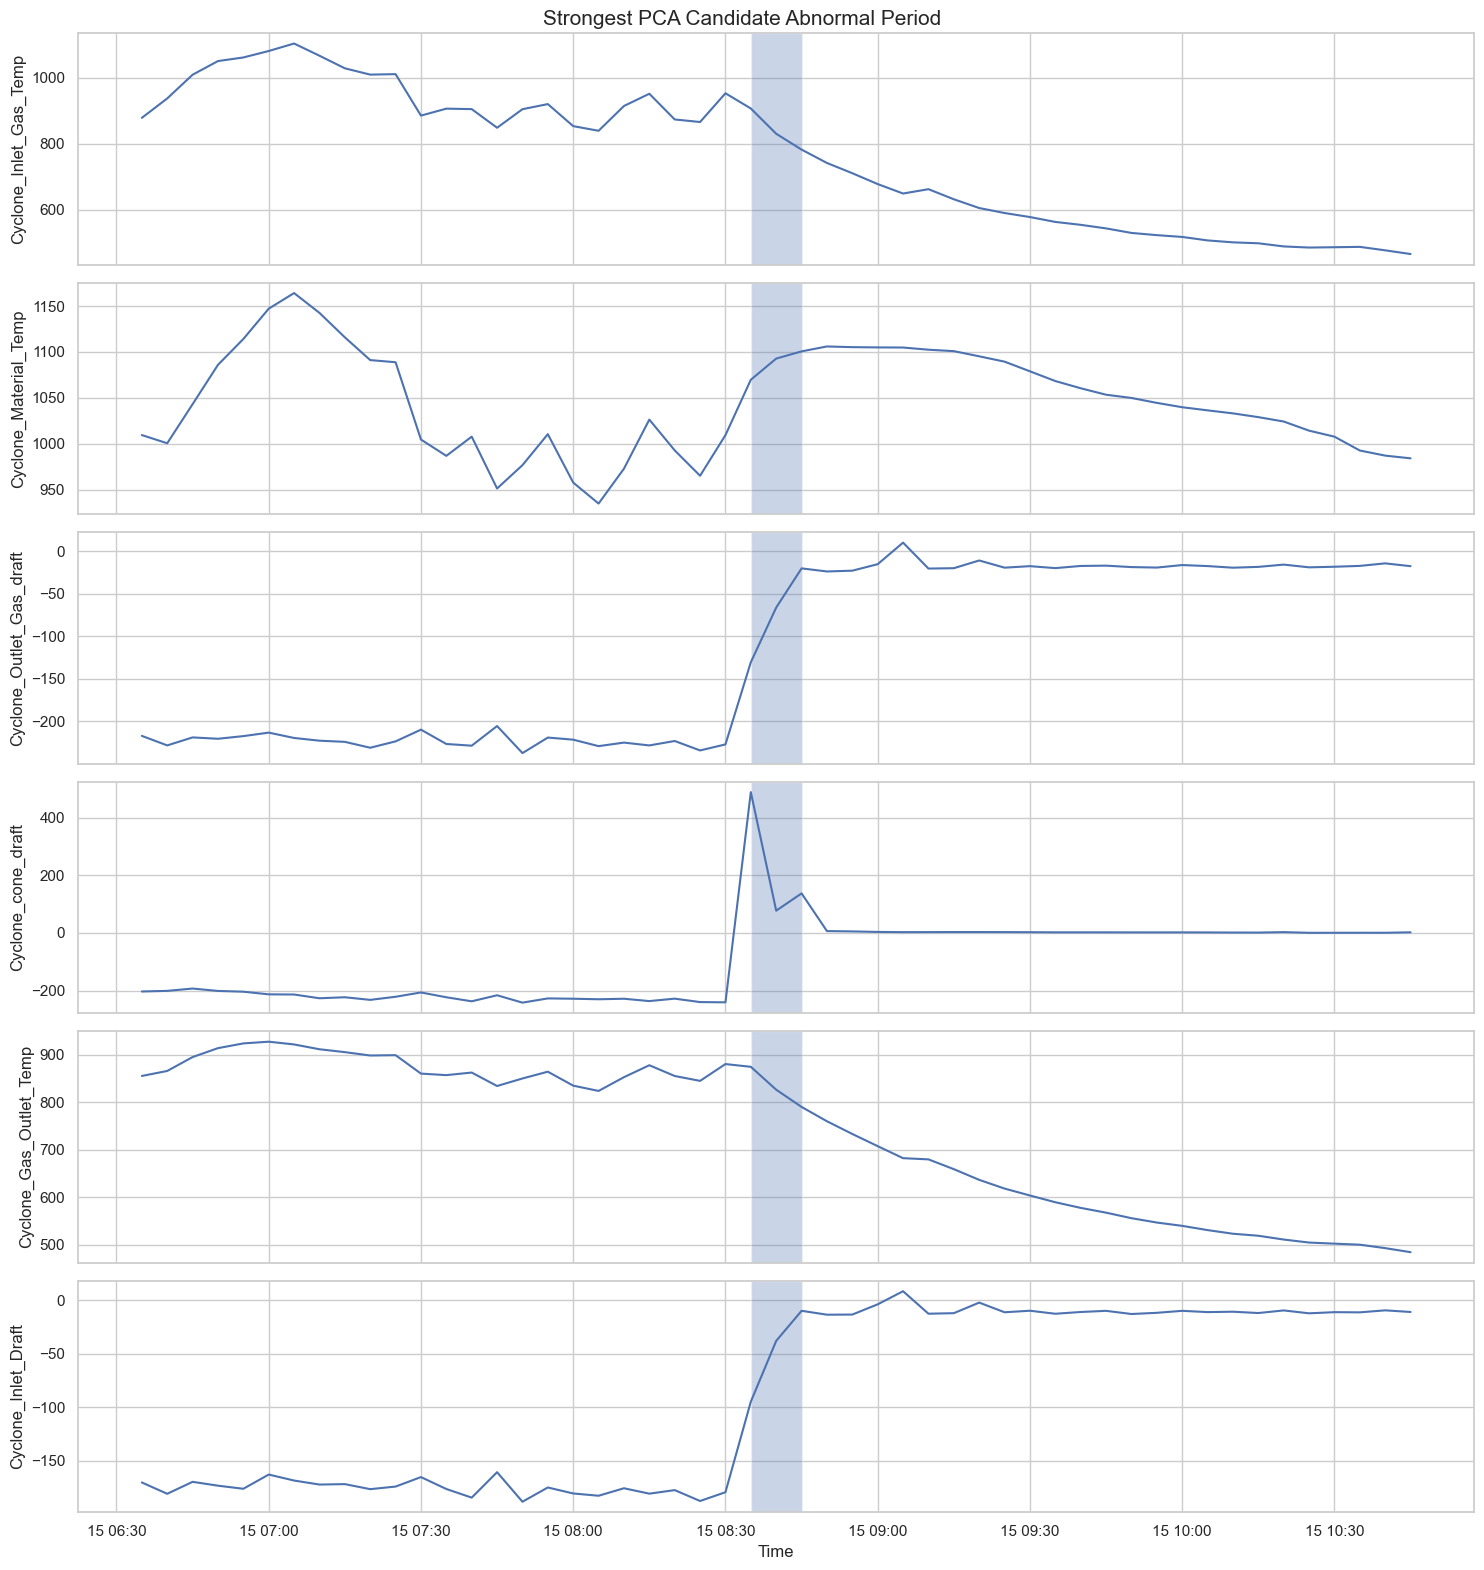

In [101]:
event = final_event_table.iloc[0]

start_time = event["start_time"]
end_time = event["end_time"]

window_start = start_time - pd.Timedelta(hours=2)
window_end = end_time + pd.Timedelta(hours=2)

event_window = df_eda[
    (df_eda["timestamp"] >= window_start) &
    (df_eda["timestamp"] <= window_end)
].copy()

fig, axes = plt.subplots(
    6, 1,
    figsize=(15, 16),
    sharex=True
)

for ax, col in zip(axes, SENSOR_COLS):
    
    ax.plot(
        event_window["timestamp"],
        event_window[col]
    )
    
    ax.axvspan(
        start_time,
        end_time,
        alpha=0.3
    )
    
    ax.set_ylabel(col)
    ax.grid(True)

axes[-1].set_xlabel("Time")

plt.suptitle(
    "Strongest PCA Candidate Abnormal Period",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "strongest_pca_event.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Isolation Forest for Independent Anomaly Detection

PCA identifies deviations from the dominant multivariate structure.

To independently validate these findings, we apply Isolation Forest,
an unsupervised anomaly detection algorithm that isolates observations
that are unusual relative to the overall sensor population.

In [102]:
from sklearn.ensemble import IsolationForest

# Use complete sensor observations
if_data = df_eda[SENSOR_COLS].dropna().copy()

# Fit Isolation Forest
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

iso_labels = iso_forest.fit_predict(if_data[SENSOR_COLS])

# Convert:
#  1  = normal
# -1  = anomaly
if_data["isolation_anomaly"] = iso_labels == -1

# Anomaly score
if_data["isolation_score"] = -iso_forest.score_samples(
    if_data[SENSOR_COLS]
)

print("Isolation Forest anomalies:",
      if_data["isolation_anomaly"].sum())

print(
    "Percentage:",
    round(
        if_data["isolation_anomaly"].mean() * 100,
        2
    ),
    "%"
)

Isolation Forest anomalies: 3762
Percentage: 1.0 %


#### Isolation Forest Candidate Abnormal Periods

The Isolation Forest identifies individual anomalous observations.
We group consecutive or closely spaced anomalous observations into
time periods so that the output is interpretable as process events.

In [103]:
# Add timestamps
if_data = if_data.join(
    df_eda.loc[if_data.index, ["timestamp"]]
)

# Keep anomalies
if_anomalies = if_data[
    if_data["isolation_anomaly"]
].copy()

# Sort chronologically
if_anomalies = if_anomalies.sort_values("timestamp")

# Start a new event if gap > 30 minutes
if_anomalies["time_gap"] = (
    if_anomalies["timestamp"].diff()
)

if_anomalies["new_event"] = (
    if_anomalies["time_gap"] > pd.Timedelta(minutes=30)
)

if_anomalies["event_group"] = (
    if_anomalies["new_event"].cumsum()
)

# Summarize events
if_event_summary = (
    if_anomalies
    .groupby("event_group")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        observations=("timestamp", "count"),
        max_isolation_score=("isolation_score", "max"),
        mean_isolation_score=("isolation_score", "mean")
    )
    .reset_index()
)

if_event_summary["duration_minutes"] = (
    (
        if_event_summary["end_time"]
        - if_event_summary["start_time"]
    ).dt.total_seconds() / 60
)

if_event_summary = if_event_summary.sort_values(
    "max_isolation_score",
    ascending=False
).reset_index(drop=True)

if_event_summary.head(20)

,event_group,start_time,end_time,observations,max_isolation_score,mean_isolation_score,duration_minutes
0,294,2019-06-04 08:45:00,2019-06-04 11:50:00,38,0.713155,0.684393,185.0
1,101,2018-02-01 23:45:00,2018-02-02 02:35:00,35,0.704083,0.678267,170.0
2,197,2018-08-01 00:00:00,2018-08-01 00:05:00,2,0.701563,0.694634,5.0
3,320,2019-09-15 08:55:00,2019-09-15 09:55:00,13,0.700011,0.697993,60.0
4,309,2019-08-02 10:30:00,2019-08-03 09:30:00,274,0.699930,0.684633,1380.0
5,28,2017-05-19 15:05:00,2017-05-19 15:25:00,5,0.699917,0.675421,20.0
6,316,2019-08-31 04:40:00,2019-08-31 04:40:00,1,0.699904,0.699904,0.0
7,64,2017-09-19 01:05:00,2017-09-19 05:05:00,40,0.699747,0.678150,240.0
8,352,2019-12-24 17:45:00,2019-12-24 23:45:00,67,0.699341,0.687508,360.0
9,366,2020-05-01 21:15:00,2020-05-02 00:15:00,36,0.698819,0.682743,180.0


In [104]:
if_event_summary.head(10)

,event_group,start_time,end_time,observations,max_isolation_score,mean_isolation_score,duration_minutes
0,294,2019-06-04 08:45:00,2019-06-04 11:50:00,38,0.713155,0.684393,185.0
1,101,2018-02-01 23:45:00,2018-02-02 02:35:00,35,0.704083,0.678267,170.0
2,197,2018-08-01 00:00:00,2018-08-01 00:05:00,2,0.701563,0.694634,5.0
3,320,2019-09-15 08:55:00,2019-09-15 09:55:00,13,0.700011,0.697993,60.0
4,309,2019-08-02 10:30:00,2019-08-03 09:30:00,274,0.699930,0.684633,1380.0
5,28,2017-05-19 15:05:00,2017-05-19 15:25:00,5,0.699917,0.675421,20.0
6,316,2019-08-31 04:40:00,2019-08-31 04:40:00,1,0.699904,0.699904,0.0
7,64,2017-09-19 01:05:00,2017-09-19 05:05:00,40,0.699747,0.678150,240.0
8,352,2019-12-24 17:45:00,2019-12-24 23:45:00,67,0.699341,0.687508,360.0
9,366,2020-05-01 21:15:00,2020-05-02 00:15:00,36,0.698819,0.682743,180.0


#### Cross-Validation of PCA and Isolation Forest

PCA and Isolation Forest identify anomalies using different principles.

PCA detects deviations from the dominant multivariate sensor structure,
while Isolation Forest identifies observations that are relatively isolated
in the feature space.

We compare their detected timestamps to identify periods supported by
multiple independent methods.

In [105]:
# Create PCA anomaly flags
pca_flags = df_pca[
    ["timestamp", "pca_anomaly"]
].copy()

# Create Isolation Forest flags
if_flags = if_data[
    ["timestamp", "isolation_anomaly"]
].copy()

# Merge both methods
method_comparison = pd.merge(
    pca_flags,
    if_flags,
    on="timestamp",
    how="outer"
)

method_comparison["pca_anomaly"] = (
    method_comparison["pca_anomaly"]
    .fillna(False)
)

method_comparison["isolation_anomaly"] = (
    method_comparison["isolation_anomaly"]
    .fillna(False)
)

# Categorize each timestamp
method_comparison["detection_type"] = np.select(
    [
        method_comparison["pca_anomaly"] &
        method_comparison["isolation_anomaly"],

        method_comparison["pca_anomaly"] &
        ~method_comparison["isolation_anomaly"],

        ~method_comparison["pca_anomaly"] &
        method_comparison["isolation_anomaly"]
    ],
    [
        "Both methods",
        "PCA only",
        "Isolation Forest only"
    ],
    default="Neither"
)

method_comparison["detection_type"].value_counts()

detection_type
Neither                  365055
PCA only                   7307
Isolation Forest only      3545
Both methods                217
Name: count, dtype: int64

In [106]:
#actual overlap
comparison_summary = pd.DataFrame({
    "Method": [
        "PCA",
        "Isolation Forest",
        "Both methods"
    ],
    "Anomaly_Count": [
        method_comparison["pca_anomaly"].sum(),
        method_comparison["isolation_anomaly"].sum(),
        (
            method_comparison["pca_anomaly"] &
            method_comparison["isolation_anomaly"]
        ).sum()
    ]
})

comparison_summary["Percentage"] = (
    comparison_summary["Anomaly_Count"]
    / len(method_comparison)
    * 100
)

comparison_summary

,Method,Anomaly_Count,Percentage
0,PCA,7524,2.000404
1,Isolation Forest,3762,1.000202
2,Both methods,217,0.057694


In [107]:
#common abnormal periods
common_anomalies = method_comparison[
    method_comparison["pca_anomaly"] &
    method_comparison["isolation_anomaly"]
].copy()

common_anomalies = common_anomalies.sort_values("timestamp")

common_anomalies["time_gap"] = (
    common_anomalies["timestamp"].diff()
)

common_anomalies["new_event"] = (
    common_anomalies["time_gap"] > pd.Timedelta(minutes=30)
)

common_anomalies["event_group"] = (
    common_anomalies["new_event"].cumsum()
)

common_events = (
    common_anomalies
    .groupby("event_group")
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        observations=("timestamp", "count")
    )
    .reset_index()
)

common_events["duration_minutes"] = (
    (
        common_events["end_time"]
        - common_events["start_time"]
    ).dt.total_seconds() / 60
)

common_events = common_events.sort_values(
    "observations",
    ascending=False
).reset_index(drop=True)

common_events.head(20)

,event_group,start_time,end_time,observations,duration_minutes
0,3,2017-09-19 02:30:00,2017-09-19 05:05:00,31,155.0
1,14,2018-06-05 14:35:00,2018-06-05 16:45:00,20,130.0
2,12,2018-05-01 13:35:00,2018-05-01 14:55:00,15,80.0
3,31,2018-09-15 10:05:00,2018-09-15 11:25:00,15,80.0
4,20,2018-06-21 06:25:00,2018-06-21 07:40:00,11,75.0
5,25,2018-07-13 22:30:00,2018-07-13 23:45:00,9,75.0
6,5,2017-12-12 22:05:00,2017-12-12 22:45:00,9,40.0
7,21,2018-06-21 16:30:00,2018-06-21 17:05:00,8,35.0
8,1,2017-06-09 02:10:00,2017-06-09 02:40:00,7,30.0
9,16,2018-06-05 19:30:00,2018-06-05 19:50:00,5,20.0


#### Cross-Validation with Process Volatility

Candidate periods detected independently by PCA and Isolation Forest
are compared with the rolling-volatility detector.

Periods supported by multiple complementary signals are prioritized
for final investigation.

In [108]:
# Create a timestamp-level volatility flag
volatility_flags = candidate_events[
    ["timestamp", "candidate", "unstable_sensor_count"]
].copy()

volatility_flags = volatility_flags.rename(
    columns={"candidate": "volatility_anomaly"}
)

# Merge with PCA + Isolation Forest comparison
three_method_comparison = pd.merge(
    method_comparison,
    volatility_flags,
    on="timestamp",
    how="left"
)

three_method_comparison["volatility_anomaly"] = (
    three_method_comparison["volatility_anomaly"]
    .fillna(False)
)

three_method_comparison["unstable_sensor_count"] = (
    three_method_comparison["unstable_sensor_count"]
    .fillna(0)
)

# Count how many methods agree
three_method_comparison["methods_detected"] = (
    three_method_comparison["pca_anomaly"].astype(int)
    +
    three_method_comparison["isolation_anomaly"].astype(int)
    +
    three_method_comparison["volatility_anomaly"].astype(int)
)

three_method_comparison[
    "methods_detected"
].value_counts().sort_index()

methods_detected
0    354840
1     20189
2      1049
3        46
Name: count, dtype: int64

In [109]:
common_event_validation = []

for _, event in common_events.iterrows():

    mask = (
        (three_method_comparison["timestamp"] >= event["start_time"]) &
        (three_method_comparison["timestamp"] <= event["end_time"])
    )

    window = three_method_comparison.loc[mask]

    common_event_validation.append({
        "start_time": event["start_time"],
        "end_time": event["end_time"],
        "duration_minutes": event["duration_minutes"],
        "observations": event["observations"],
        "pca_count": window["pca_anomaly"].sum(),
        "isolation_forest_count": window["isolation_anomaly"].sum(),
        "volatility_count": window["volatility_anomaly"].sum(),
        "max_unstable_sensors": window["unstable_sensor_count"].max()
    })

common_event_validation = pd.DataFrame(
    common_event_validation
)

common_event_validation.head(20)

,start_time,end_time,duration_minutes,observations,pca_count,isolation_forest_count,volatility_count,max_unstable_sensors
0,2017-09-19 02:30:00,2017-09-19 05:05:00,155.0,31,32,31,0,2
1,2018-06-05 14:35:00,2018-06-05 16:45:00,130.0,20,24,23,0,0
2,2018-05-01 13:35:00,2018-05-01 14:55:00,80.0,15,17,15,3,3
3,2018-09-15 10:05:00,2018-09-15 11:25:00,80.0,15,15,17,0,1
4,2018-06-21 06:25:00,2018-06-21 07:40:00,75.0,11,16,11,0,0
5,2018-07-13 22:30:00,2018-07-13 23:45:00,75.0,9,16,9,12,5
6,2017-12-12 22:05:00,2017-12-12 22:45:00,40.0,9,9,9,9,4
7,2018-06-21 16:30:00,2018-06-21 17:05:00,35.0,8,8,8,0,2
8,2017-06-09 02:10:00,2017-06-09 02:40:00,30.0,7,7,7,5,6
9,2018-06-05 19:30:00,2018-06-05 19:50:00,20.0,5,5,5,0,0


In [110]:
common_event_validation["methods_supported"] = (
    (common_event_validation["pca_count"] > 0).astype(int)
    +
    (common_event_validation["isolation_forest_count"] > 0).astype(int)
    +
    (common_event_validation["volatility_count"] > 0).astype(int)
)

final_validation_table = common_event_validation.sort_values(
    ["methods_supported", "observations"],
    ascending=[False, False]
).reset_index(drop=True)

final_validation_table.head(10)

,start_time,end_time,duration_minutes,observations,pca_count,isolation_forest_count,volatility_count,max_unstable_sensors,methods_supported
0,2018-05-01 13:35:00,2018-05-01 14:55:00,80.0,15,17,15,3,3,3
1,2018-07-13 22:30:00,2018-07-13 23:45:00,75.0,9,16,9,12,5,3
2,2017-12-12 22:05:00,2017-12-12 22:45:00,40.0,9,9,9,9,4,3
3,2017-06-09 02:10:00,2017-06-09 02:40:00,30.0,7,7,7,5,6,3
4,2017-12-12 23:20:00,2017-12-12 23:45:00,25.0,5,5,5,3,6,3
5,2018-07-10 14:00:00,2018-07-10 14:15:00,15.0,4,4,4,4,6,3
6,2018-09-02 22:00:00,2018-09-02 22:40:00,40.0,4,6,5,2,5,3
7,2018-02-24 09:15:00,2018-02-24 09:50:00,35.0,4,6,4,8,5,3
8,2018-05-16 16:55:00,2018-05-16 17:05:00,10.0,3,3,3,1,4,3
9,2018-07-10 15:25:00,2018-07-10 15:30:00,5.0,2,2,2,2,4,3


#### Final Abnormality Ranking

Candidate periods are ranked using multiple independent indicators:

- Agreement across PCA, Isolation Forest and volatility detection
- Event duration
- Number of observations
- Maximum number of simultaneously unstable sensors

The ranking is used to prioritize periods for investigation, not to assign
a confirmed root cause.

In [111]:
final_validation_table["evidence_score"] = (
    final_validation_table["methods_supported"] * 10
    + final_validation_table["max_unstable_sensors"] * 5
    + np.log1p(final_validation_table["duration_minutes"])
    + np.log1p(final_validation_table["observations"])
)

final_validation_table = final_validation_table.sort_values(
    "evidence_score",
    ascending=False
).reset_index(drop=True)

final_validation_table.head(10)

,start_time,end_time,duration_minutes,observations,pca_count,isolation_forest_count,volatility_count,max_unstable_sensors,methods_supported,evidence_score
0,2017-06-09 02:10:00,2017-06-09 02:40:00,30.0,7,7,7,5,6,3,65.513429
1,2017-12-12 23:20:00,2017-12-12 23:45:00,25.0,5,5,5,3,6,3,65.049856
2,2018-07-10 14:00:00,2018-07-10 14:15:00,15.0,4,4,4,4,6,3,64.382027
3,2020-07-17 16:40:00,2020-07-17 16:45:00,5.0,2,2,2,2,6,3,62.890372
4,2018-07-13 22:30:00,2018-07-13 23:45:00,75.0,9,16,9,12,5,3,61.633318
5,2018-09-02 22:00:00,2018-09-02 22:40:00,40.0,4,6,5,2,5,3,60.323010
6,2018-02-24 09:15:00,2018-02-24 09:50:00,35.0,4,6,4,8,5,3,60.192957
7,2017-12-12 22:05:00,2017-12-12 22:45:00,40.0,9,9,9,9,4,3,56.016157
8,2017-09-11 07:25:00,2017-09-11 07:25:00,0.0,1,1,1,1,5,3,55.693147
9,2018-05-16 16:55:00,2018-05-16 17:05:00,10.0,3,3,3,1,4,3,53.784190


In [112]:
final_validation_table[
    [
        "start_time",
        "end_time",
        "duration_minutes",
        "observations",
        "max_unstable_sensors",
        "pca_count",
        "isolation_forest_count",
        "volatility_count",
        "evidence_score"
    ]
].head(10)

,start_time,end_time,duration_minutes,observations,max_unstable_sensors,pca_count,isolation_forest_count,volatility_count,evidence_score
0,2017-06-09 02:10:00,2017-06-09 02:40:00,30.0,7,6,7,7,5,65.513429
1,2017-12-12 23:20:00,2017-12-12 23:45:00,25.0,5,6,5,5,3,65.049856
2,2018-07-10 14:00:00,2018-07-10 14:15:00,15.0,4,6,4,4,4,64.382027
3,2020-07-17 16:40:00,2020-07-17 16:45:00,5.0,2,6,2,2,2,62.890372
4,2018-07-13 22:30:00,2018-07-13 23:45:00,75.0,9,5,16,9,12,61.633318
5,2018-09-02 22:00:00,2018-09-02 22:40:00,40.0,4,5,6,5,2,60.323010
6,2018-02-24 09:15:00,2018-02-24 09:50:00,35.0,4,5,6,4,8,60.192957
7,2017-12-12 22:05:00,2017-12-12 22:45:00,40.0,9,4,9,9,9,56.016157
8,2017-09-11 07:25:00,2017-09-11 07:25:00,0.0,1,5,1,1,1,55.693147
9,2018-05-16 16:55:00,2018-05-16 17:05:00,10.0,3,4,3,3,1,53.784190


#### Final Validation of Multi-Method Candidate Events

The strongest candidate periods are inspected using the original sensor
measurements.

The purpose is to verify that the statistical detections correspond to
coordinated changes in the underlying process variables.

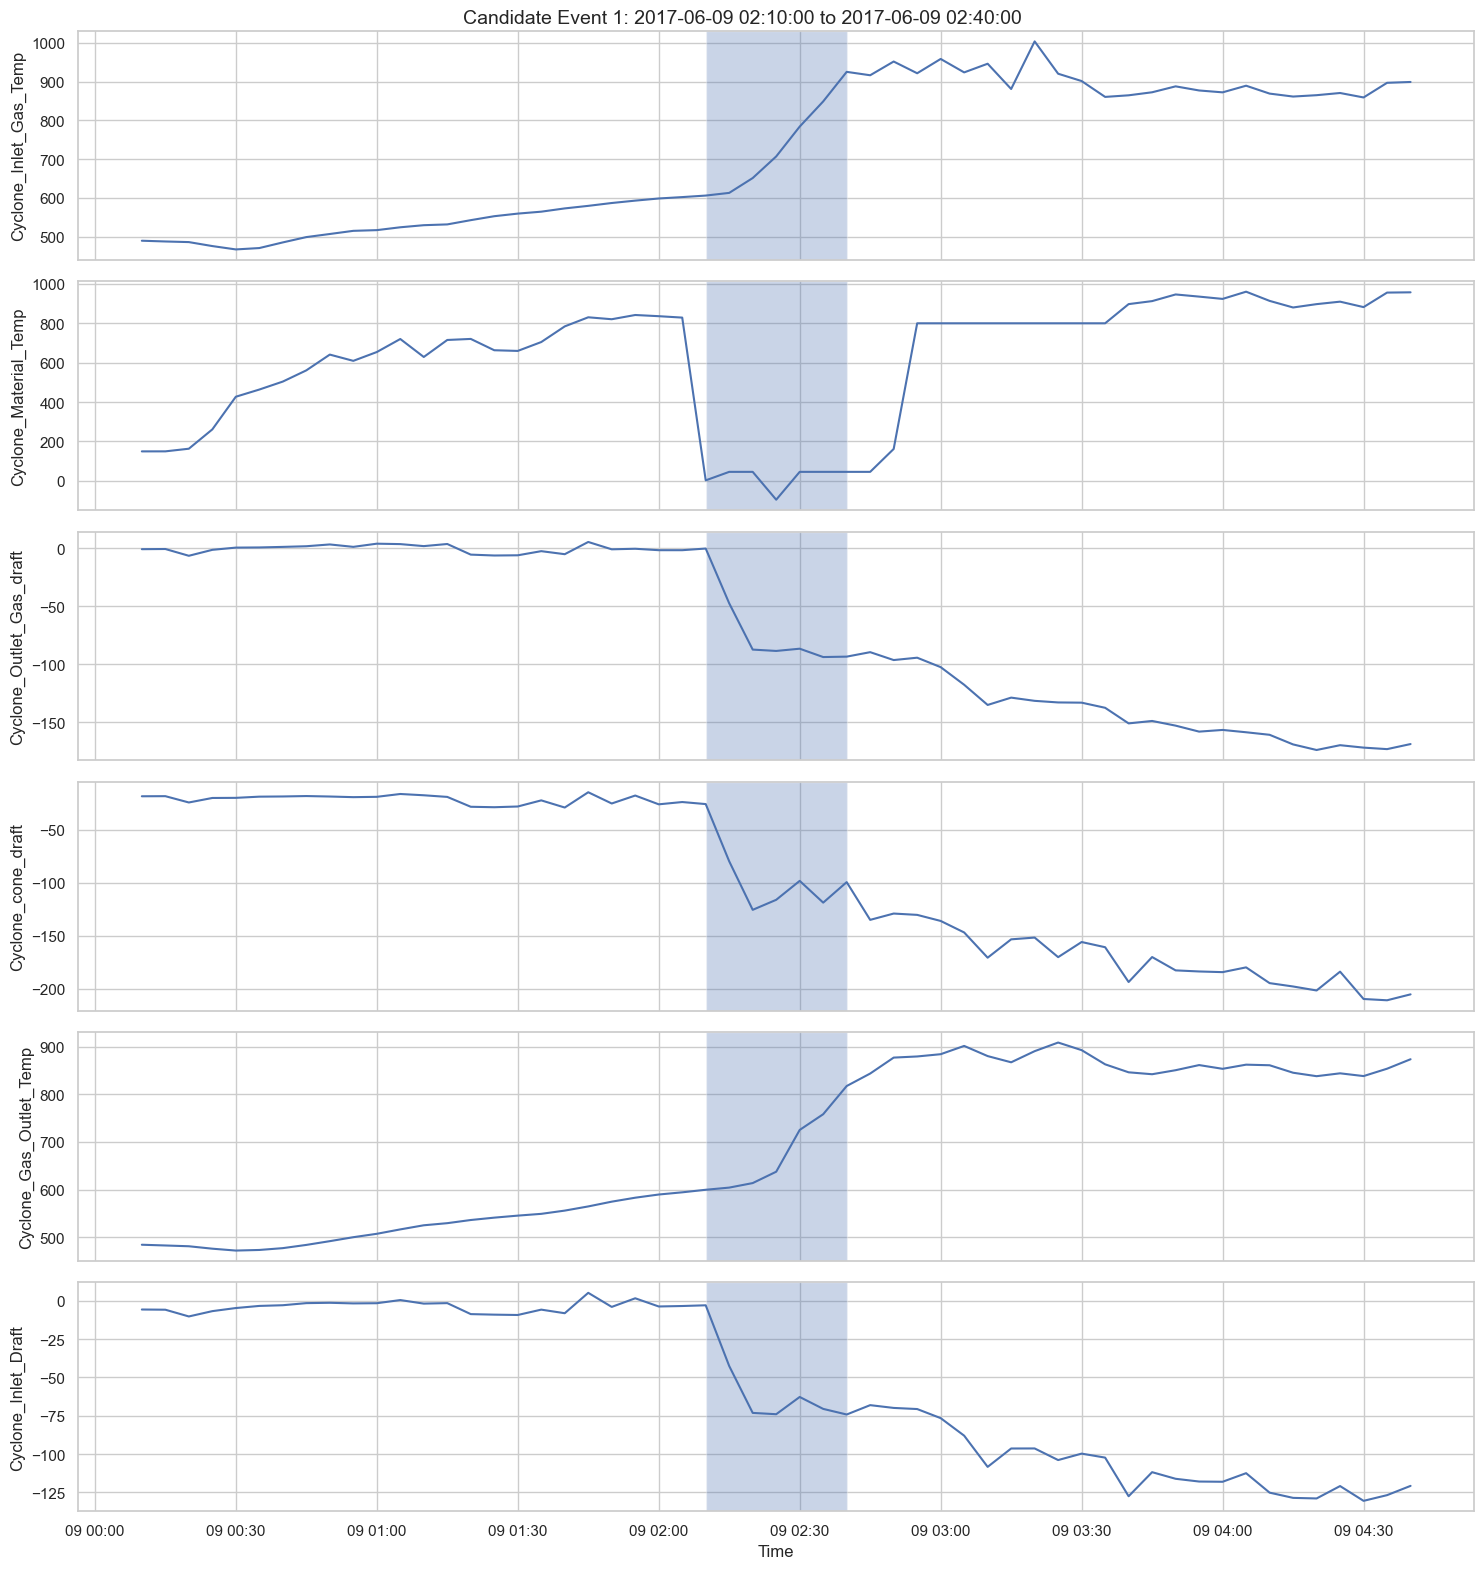

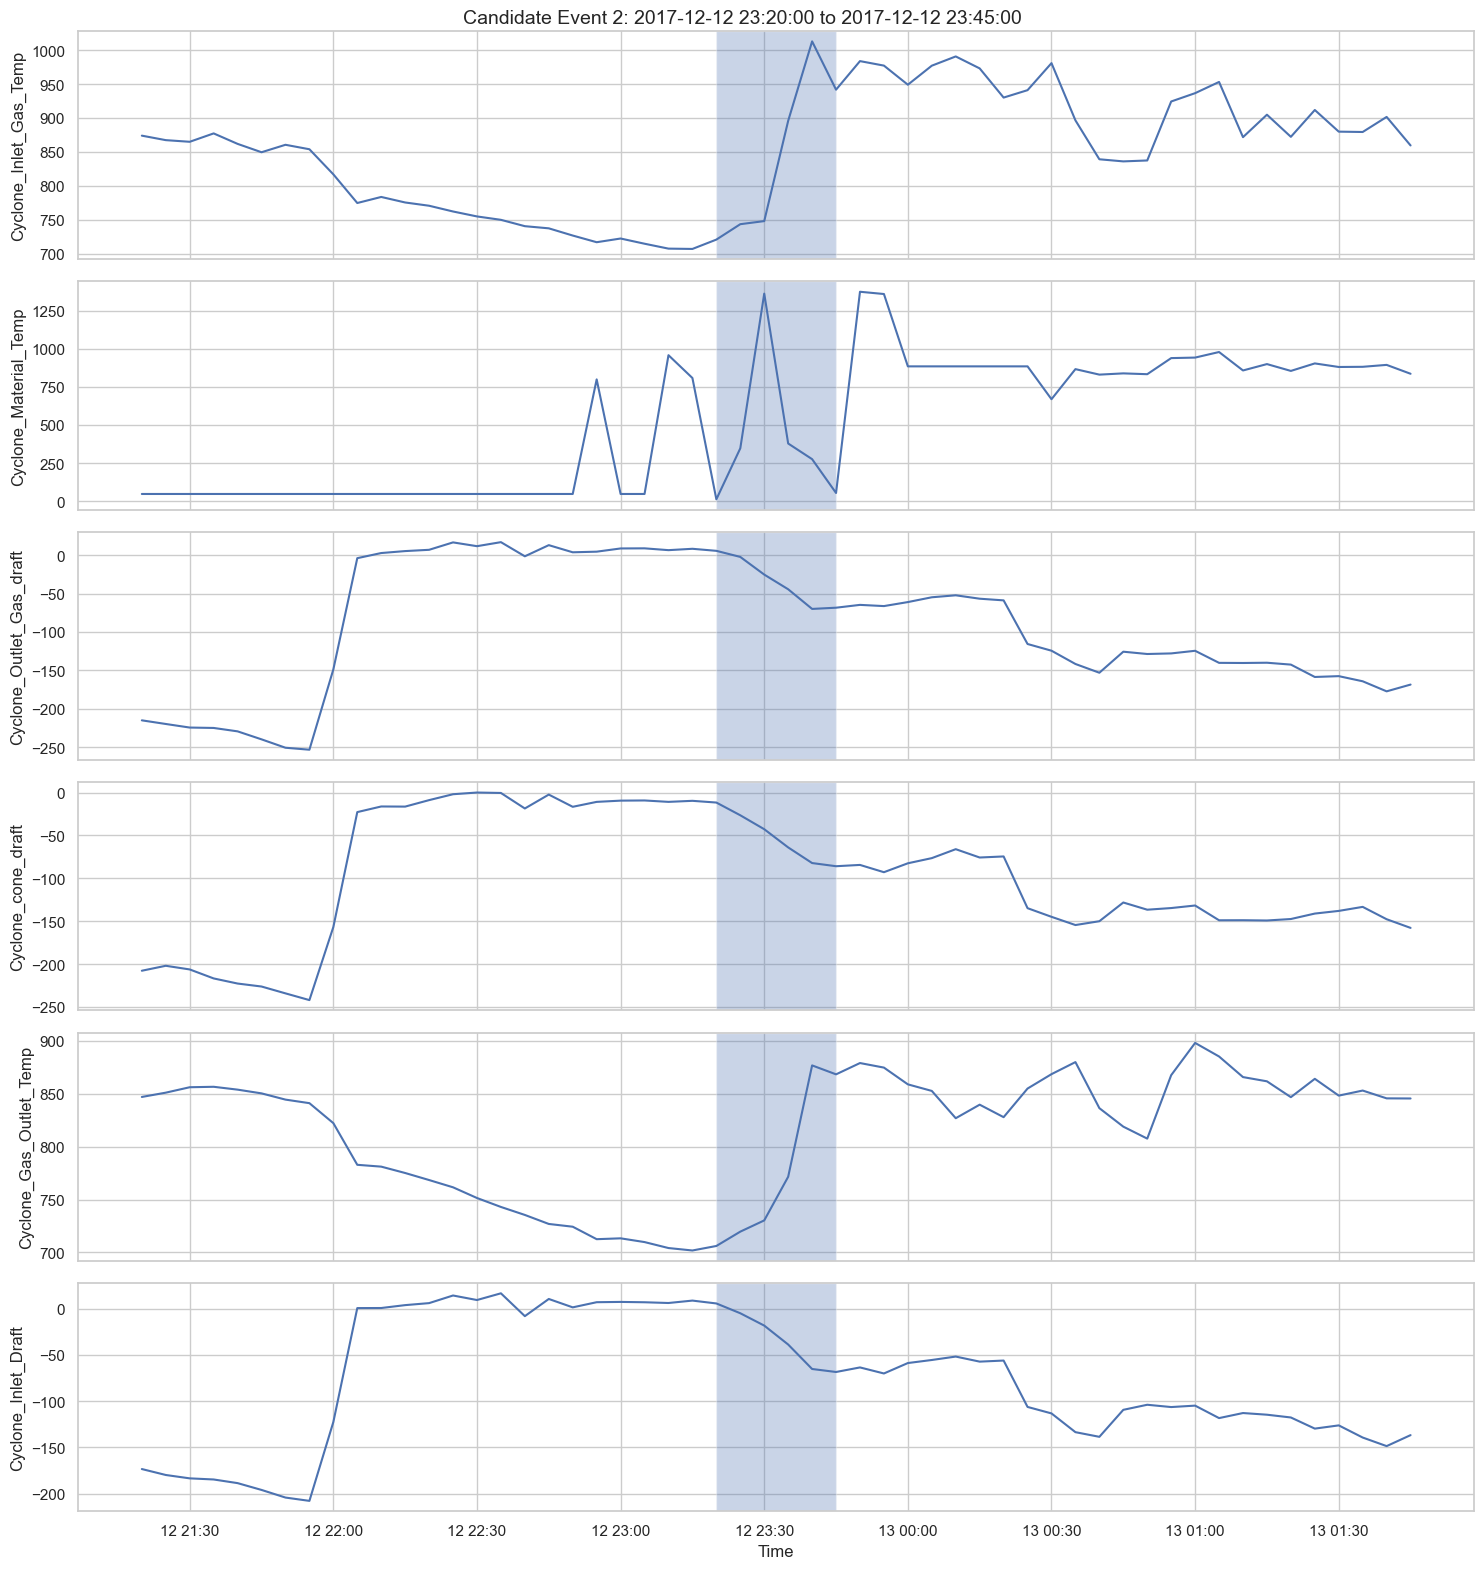

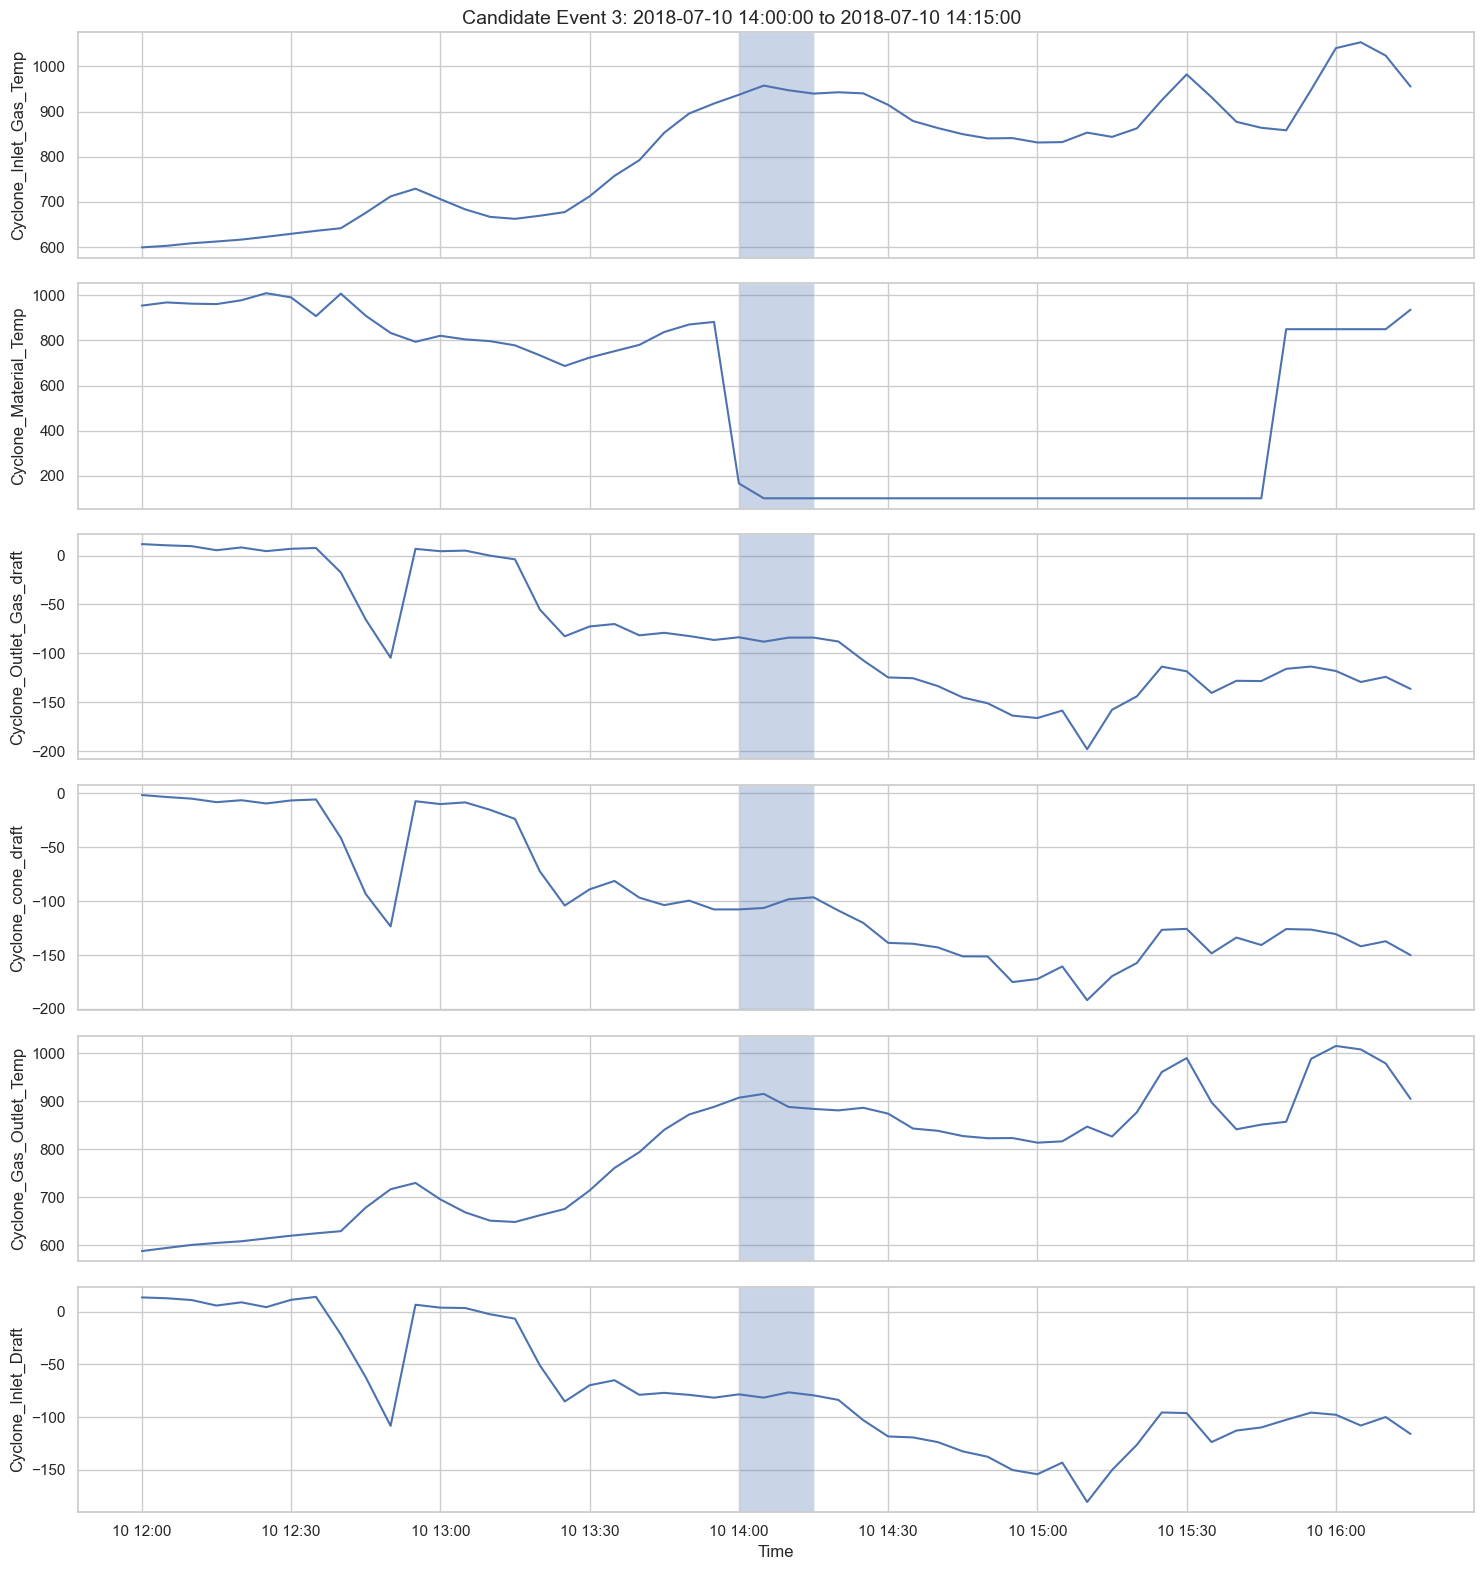

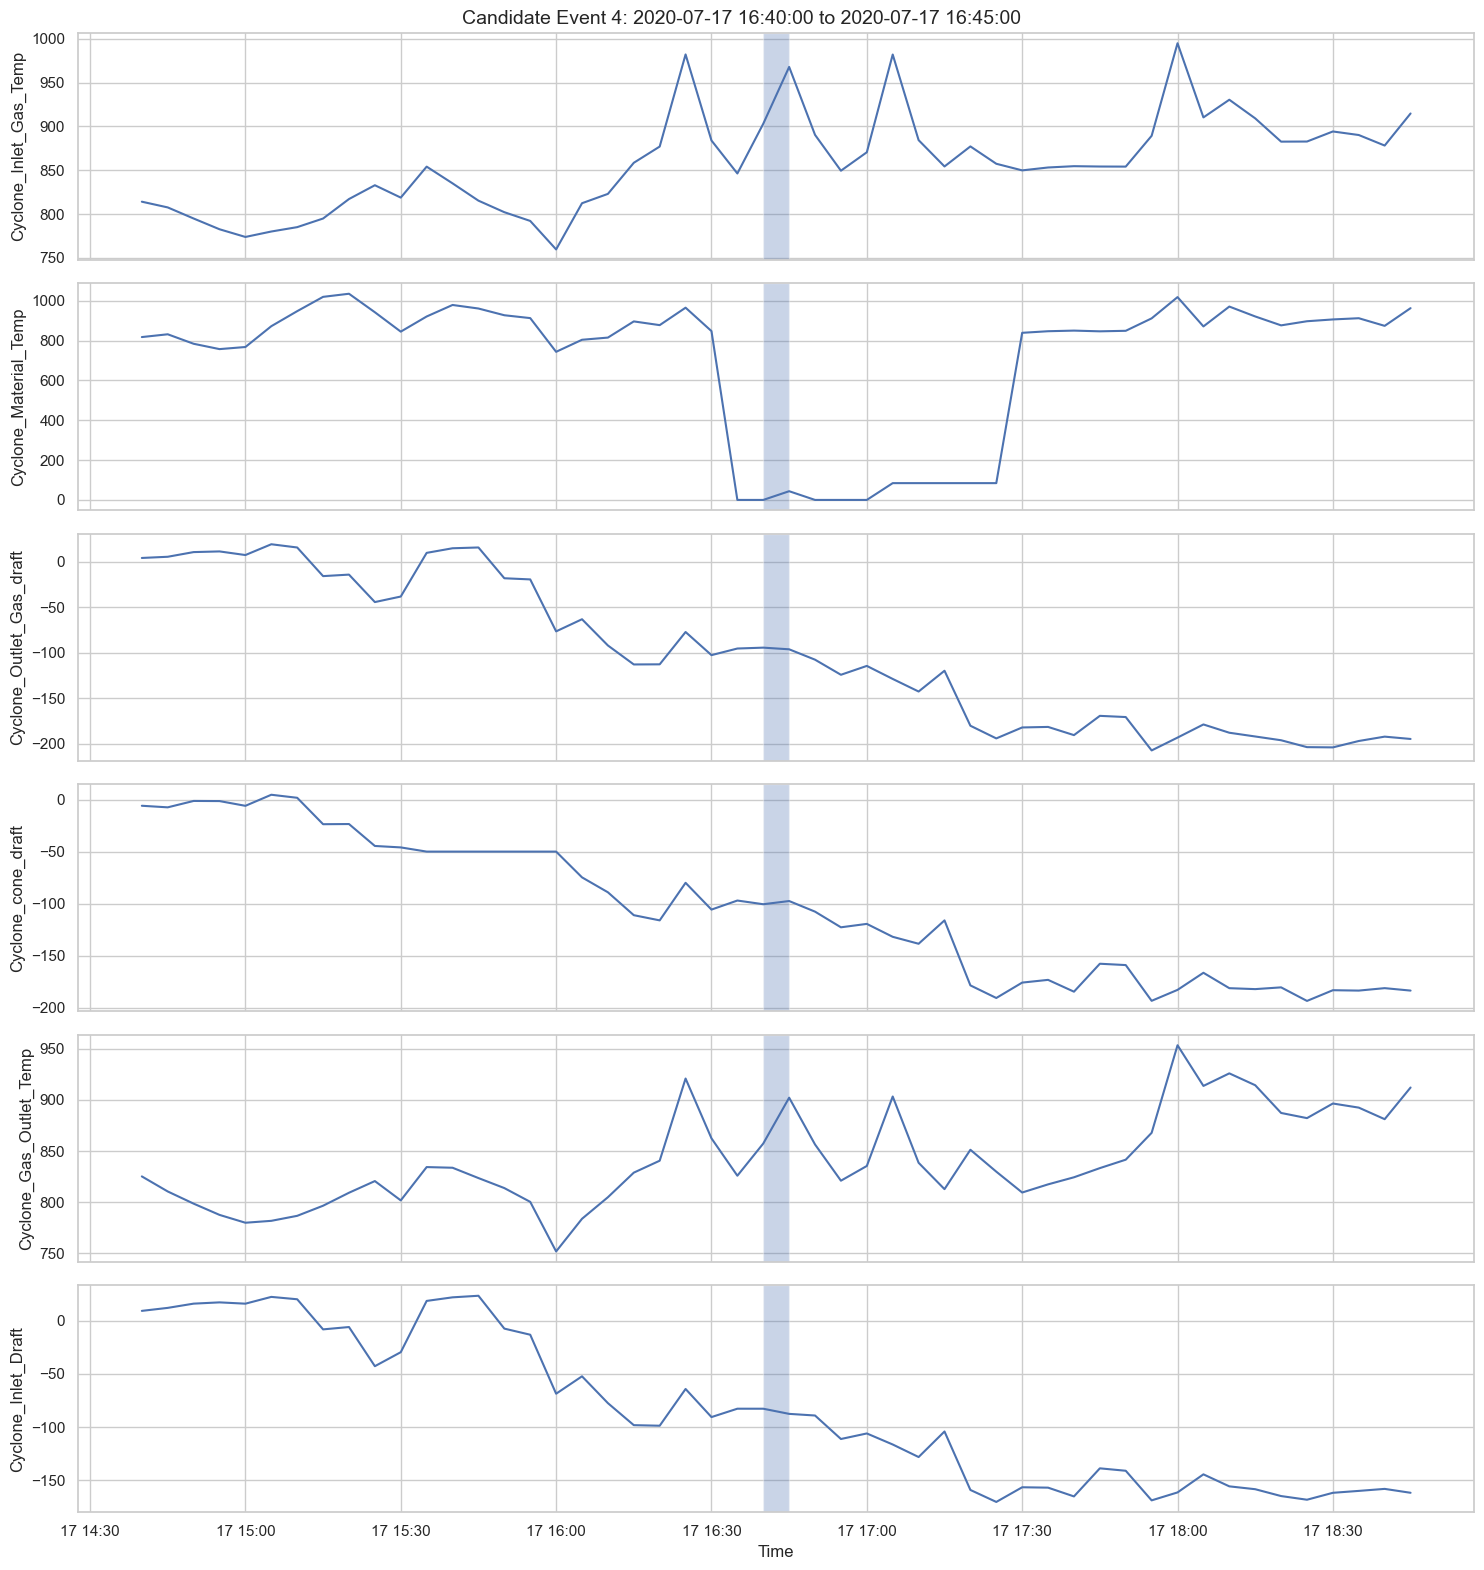

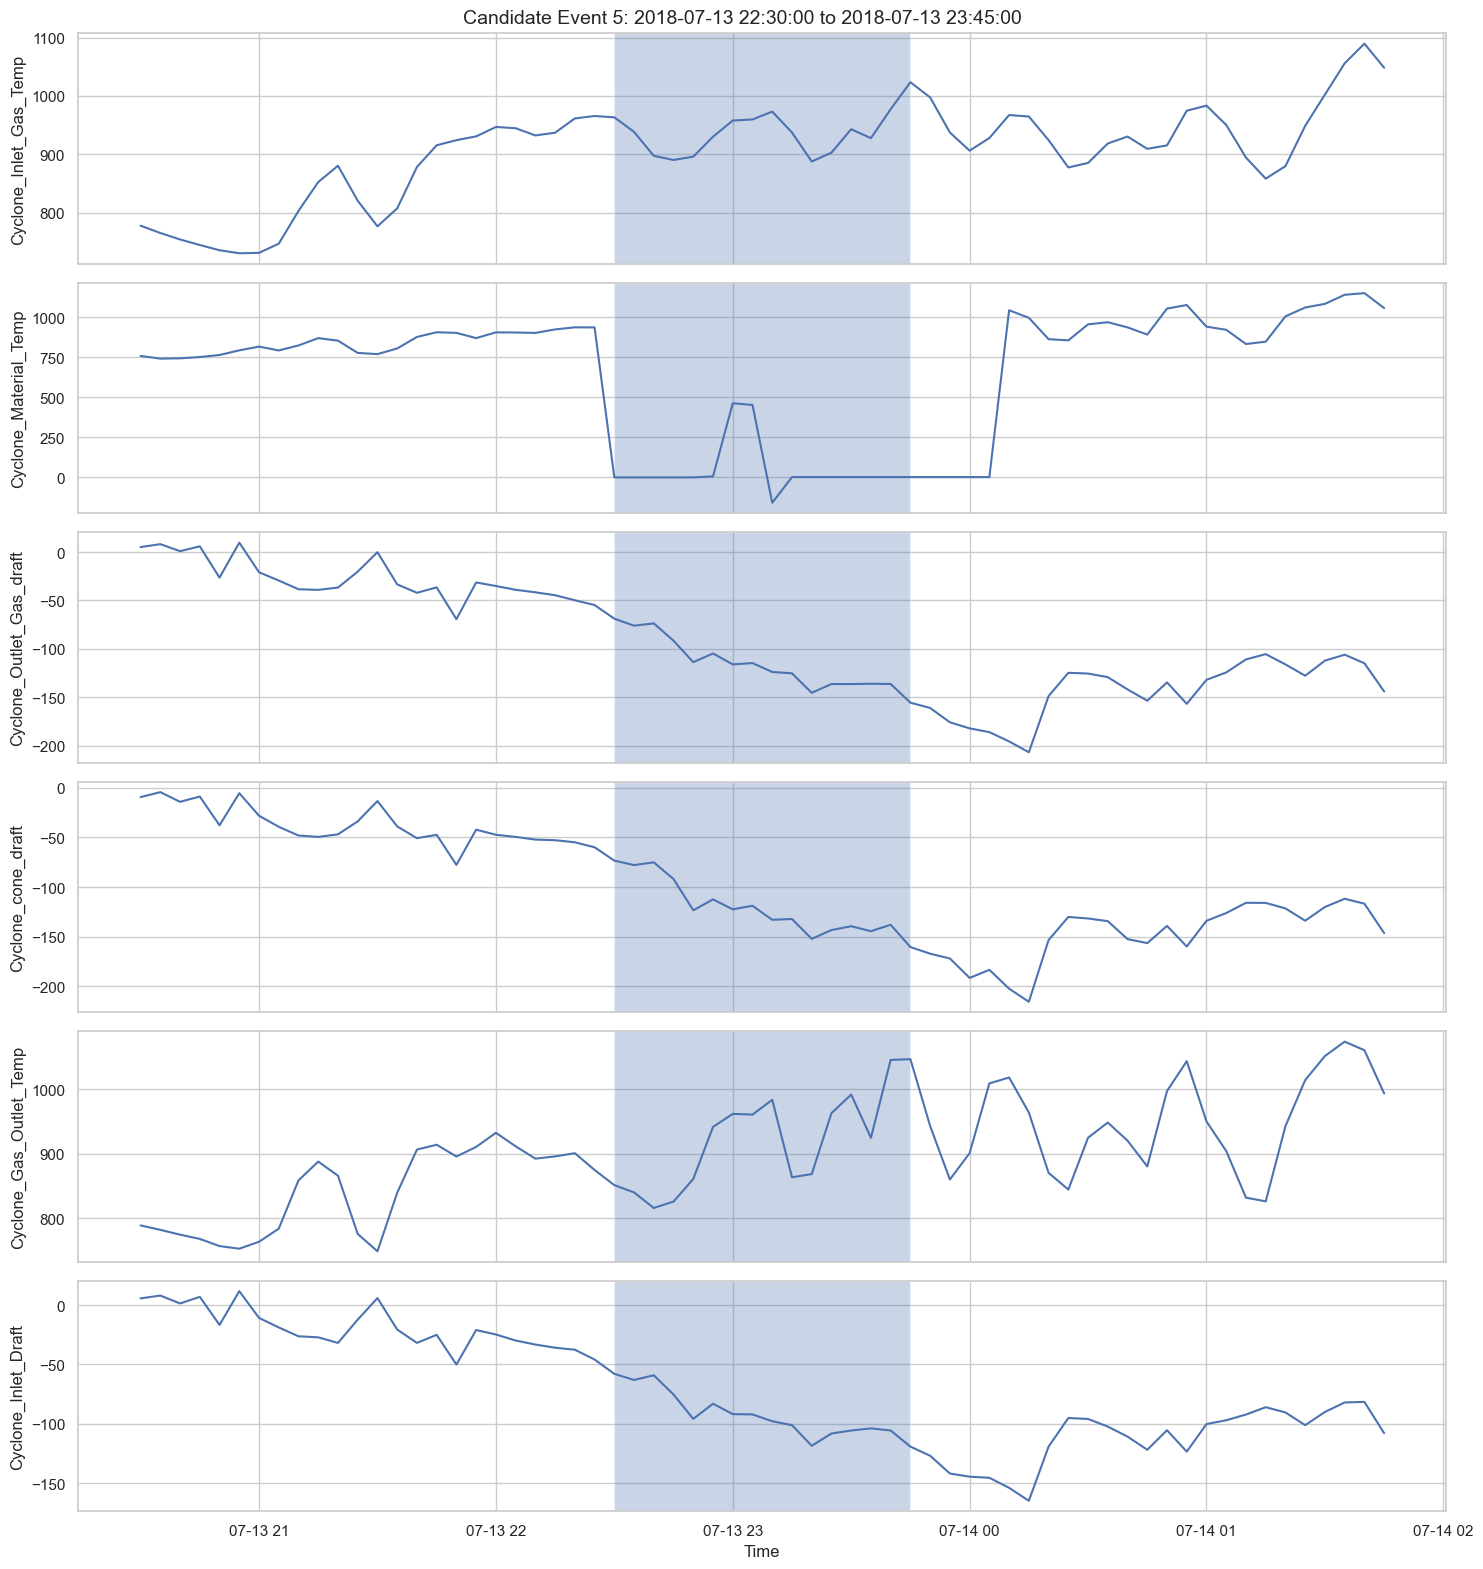

In [113]:
final_candidates = final_validation_table.head(5).copy()

for i, event in final_candidates.iterrows():

    start_time = event["start_time"]
    end_time = event["end_time"]

    window_start = start_time - pd.Timedelta(hours=2)
    window_end = end_time + pd.Timedelta(hours=2)

    event_window = df_eda[
        (df_eda["timestamp"] >= window_start) &
        (df_eda["timestamp"] <= window_end)
    ].copy()

    fig, axes = plt.subplots(
        6, 1,
        figsize=(15, 16),
        sharex=True
    )

    for ax, col in zip(axes, SENSOR_COLS):

        ax.plot(
            event_window["timestamp"],
            event_window[col]
        )

        ax.axvspan(
            start_time,
            end_time,
            alpha=0.3
        )

        ax.set_ylabel(col)
        ax.grid(True)

    axes[-1].set_xlabel("Time")

    plt.suptitle(
        f"Candidate Event {i+1}: "
        f"{start_time} to {end_time}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

#### FINAL SUMMARY — CANDIDATE ABNORMAL OPERATING PERIODS

In [114]:
# Final candidate abnormal periods

final_events = final_validation_table.copy()

# Sort by our evidence and multi-method support
final_events = final_events.sort_values(
    ["methods_supported", "max_unstable_sensors", "evidence_score"],
    ascending=False
).reset_index(drop=True)

print("FINAL CANDIDATE ABNORMAL PERIODS")
print("=" * 80)

print(
    final_events[
        [
            "start_time",
            "end_time",
            "duration_minutes",
            "observations",
            "max_unstable_sensors",
            "methods_supported",
            "evidence_score"
        ]
    ].head(10).to_string(index=False)
)

FINAL CANDIDATE ABNORMAL PERIODS
         start_time            end_time  duration_minutes  observations  max_unstable_sensors  methods_supported  evidence_score
2017-06-09 02:10:00 2017-06-09 02:40:00              30.0             7                     6                  3       65.513429
2017-12-12 23:20:00 2017-12-12 23:45:00              25.0             5                     6                  3       65.049856
2018-07-10 14:00:00 2018-07-10 14:15:00              15.0             4                     6                  3       64.382027
2020-07-17 16:40:00 2020-07-17 16:45:00               5.0             2                     6                  3       62.890372
2018-07-13 22:30:00 2018-07-13 23:45:00              75.0             9                     5                  3       61.633318
2018-09-02 22:00:00 2018-09-02 22:40:00              40.0             4                     5                  3       60.323010
2018-02-24 09:15:00 2018-02-24 09:50:00              35.0       